## IMPORT LIBRARIES

In [2]:
# pip install graphviz

In [3]:
import os
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

from IPython.display import Image, display
from scipy.stats import randint
from scipy.stats import uniform
%matplotlib inline
from matplotlib.colors import ListedColormap
from mlxtend.plotting import plot_decision_regions

from sklearn import tree
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.tree import export_graphviz
from sklearn.tree import DecisionTreeClassifier as dt
from sklearn.metrics import accuracy_score as acs
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold as sk
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import KFold as sk

## IMPORT DATA

In [5]:
df = pd.read_csv("Group 5_CleanedData.csv")

X = df.drop("Condition", axis=1)
y = df["Condition"]

X = pd.DataFrame(X)
y= pd.DataFrame(y)

## DATA UNDERSTANDING

In [7]:
#Data Preprocessing
display(df.describe().round(2))

#Dimensions of dataframe
print(f"Total no.of columns: {df.shape[1]}")
print(f"Total no. of rows: {df.shape[0]}")

#Number of rows for each condition
conditions = ['Normal1', 'Condition4', 'Condition7']
for cond in conditions:
    print(f"No. of rows of {cond}: {df[df['Condition'] == cond]['Condition'].count()}")

,Cylinder heating zone 1,Cylinder heating zone 4,Maximum injection pressure,Mould temperature control unit 1,Cycle time,Cylinder heating zone 5,Injection time,Cylinder heating zone 2,Dosage time,Cylinder heating zone 3,Switch-over volume,Material cushion
count,126.00,126.00,126.00,126.00,126.00,126.00,126.00,126.00,126.00,126.00,126.00,126.00
mean,281.04,310.81,1614.31,90.30,28.92,316.56,0.23,293.92,2.90,311.41,1.35,0.90
std,12.05,10.75,105.71,3.80,1.16,13.69,0.02,12.35,0.14,11.25,0.10,0.05
min,254.69,281.54,1436.38,81.84,26.33,289.89,0.19,268.48,2.61,286.29,1.15,0.77
25%,271.41,304.29,1532.42,87.93,28.09,305.56,0.19,285.41,2.81,304.11,1.28,0.86
50%,282.06,310.47,1597.90,90.20,28.85,317.16,0.23,294.18,2.91,310.66,1.36,0.90
75%,289.61,319.17,1701.37,93.14,29.80,327.68,0.24,300.62,3.01,317.75,1.42,0.95
max,306.08,336.55,1838.17,98.49,31.64,345.70,0.26,320.88,3.18,340.49,1.55,1.01


Total no.of columns: 13
Total no. of rows: 126
No. of rows of Normal1: 50
No. of rows of Condition4: 41
No. of rows of Condition7: 35


## CREATING SAVED PATHS

In [9]:
def create_save_path(model_name):
    # Create a save path based on the model name
    base_path = os.getcwd()  # Get the current working directory
    save_path = os.path.join(base_path, model_name)  # Create a path for the specific model
    os.makedirs(save_path, exist_ok=True)  # Create the directory if it doesn't exist
    return save_path

# Example usage for each model
decision_tree_save_path = create_save_path('Decision_Tree_Project1')
print("Decision Tree Save Path:", decision_tree_save_path)

# For Decision Tree - Grid Search
grid_search_save_path = create_save_path('Decision_Tree_Project1/GridSearch')
print("\nGrid Search Save Path:", grid_search_save_path)

# For Decision Tree - Random Search
random_search_save_path = create_save_path('Decision_Tree_Project1/RandomizedSearch')
print("\nRandom Search Save Path:", random_search_save_path)

# For SVM
svm_save_path = create_save_path('SVM_Project1')
print("\nSVM Save Path:", svm_save_path)

# For tuned SVM
tuned_svm_save_path = create_save_path('SVM_Project1/tuned')
print("\nTuned SVM Save Path:", tuned_svm_save_path)

# For Random Forest
random_forest_save_path = create_save_path('Random_Forest_Project1')
print("\nRandom Forest Save Path:", random_forest_save_path)

Decision Tree Save Path: C:\Users\Ivan Chee\Decision_Tree_Project1

Grid Search Save Path: C:\Users\Ivan Chee\Decision_Tree_Project1/GridSearch

Random Search Save Path: C:\Users\Ivan Chee\Decision_Tree_Project1/RandomizedSearch

SVM Save Path: C:\Users\Ivan Chee\SVM_Project1

Tuned SVM Save Path: C:\Users\Ivan Chee\SVM_Project1/tuned

Random Forest Save Path: C:\Users\Ivan Chee\Random_Forest_Project1


## DECISION TREE

#### DEFAULT DECISION TREE


training data length: 94
verification data length: 32
Accuracy: 0.9375
F1 Score: 0.9375

Decision tree Prediction classification report 
               precision    recall  f1-score   support

  Condition4       0.89      0.89      0.89         9
  Condition7       1.00      1.00      1.00         9
     Normal1       0.93      0.93      0.93        14

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32

Normal1_accuracy: 0.89
condition4_accuracy: 1.0
condition7_accuracy: 0.93

training data length: 94
verification data length: 32
Accuracy: 0.9062
F1 Score: 0.9061

Decision tree Prediction classification report 
               precision    recall  f1-score   support

  Condition4       0.91      0.83      0.87        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.85      0.92      0.88        12

    accuracy                           0.91      

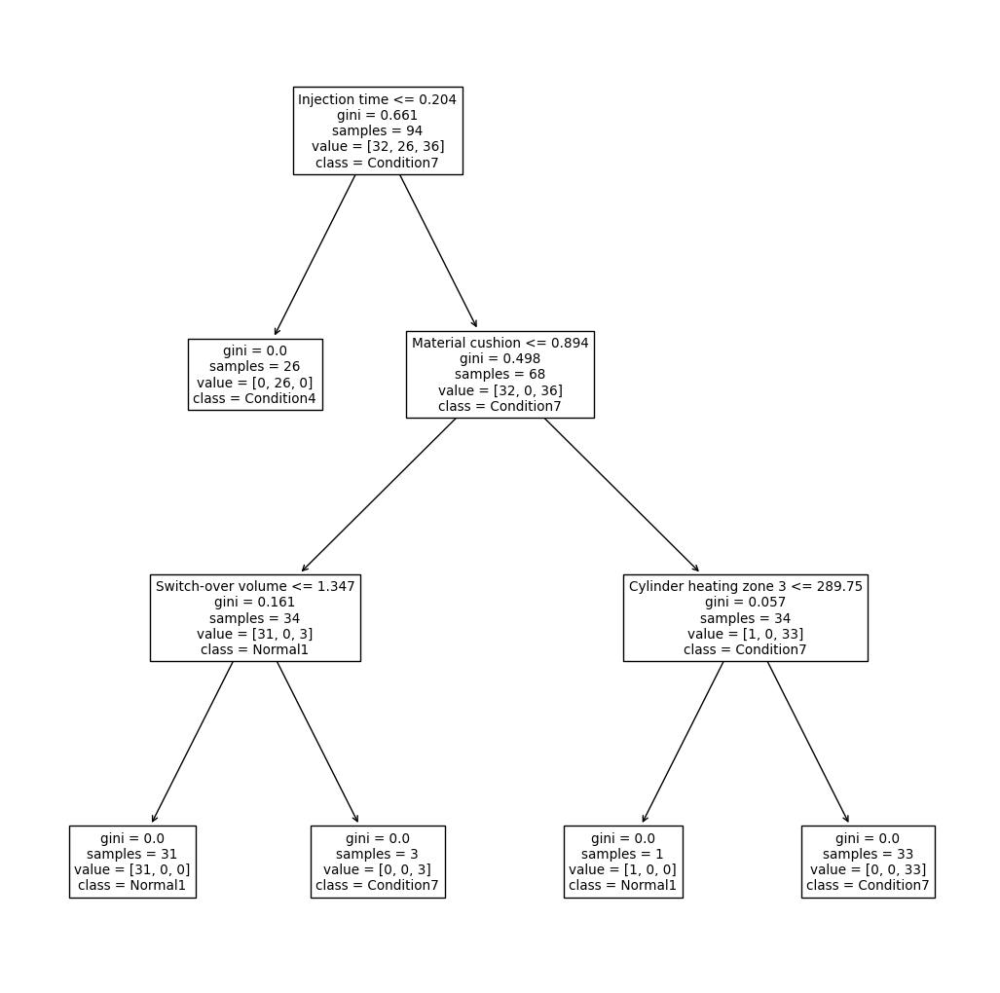

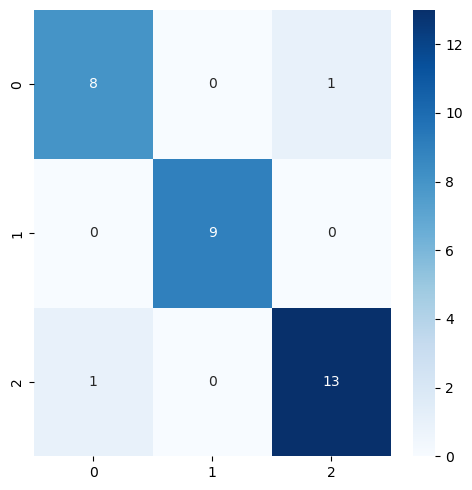

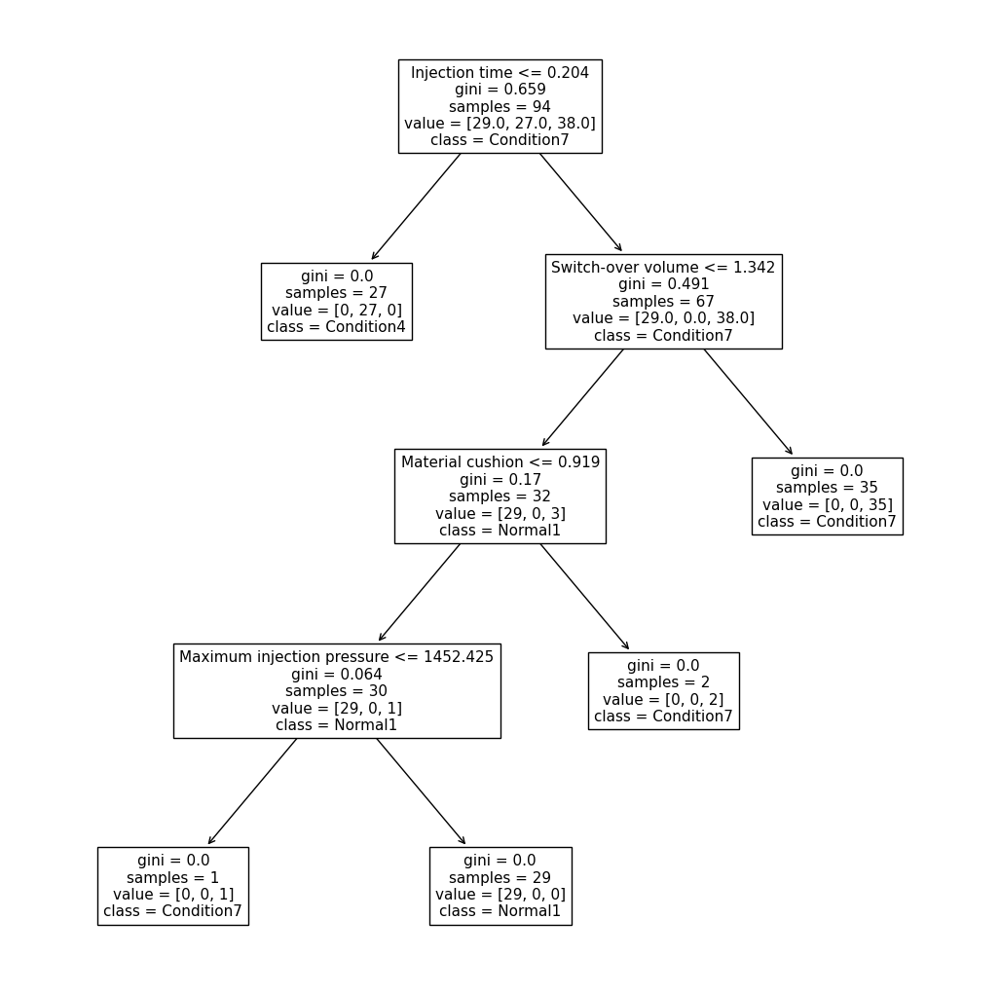

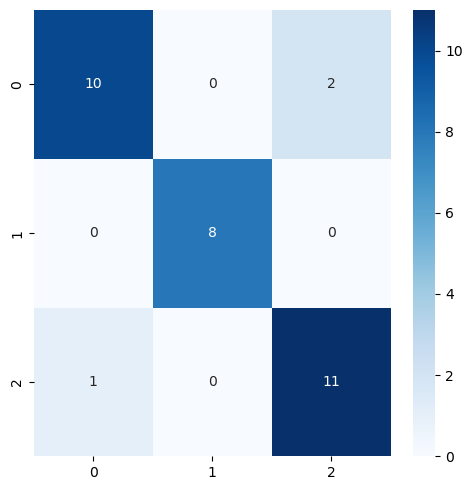

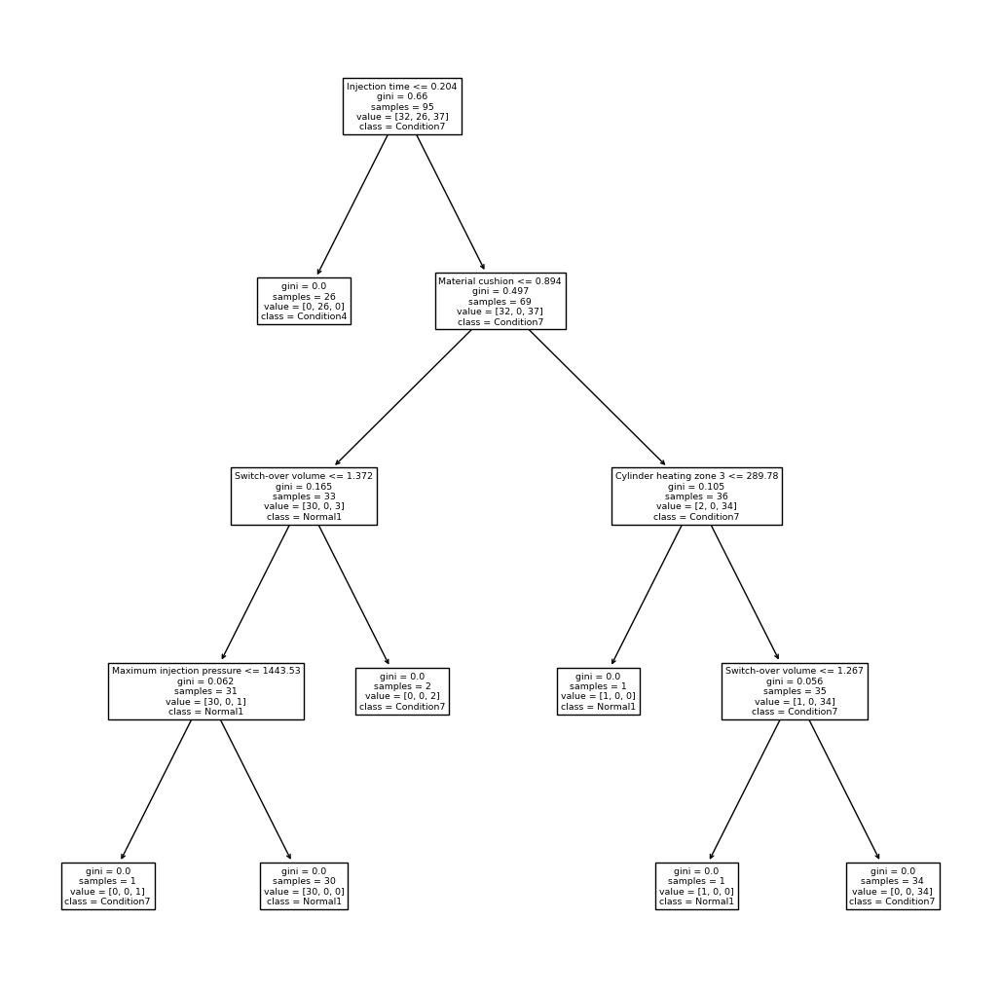

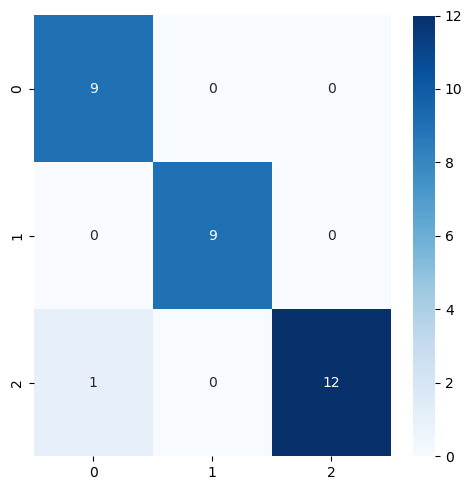

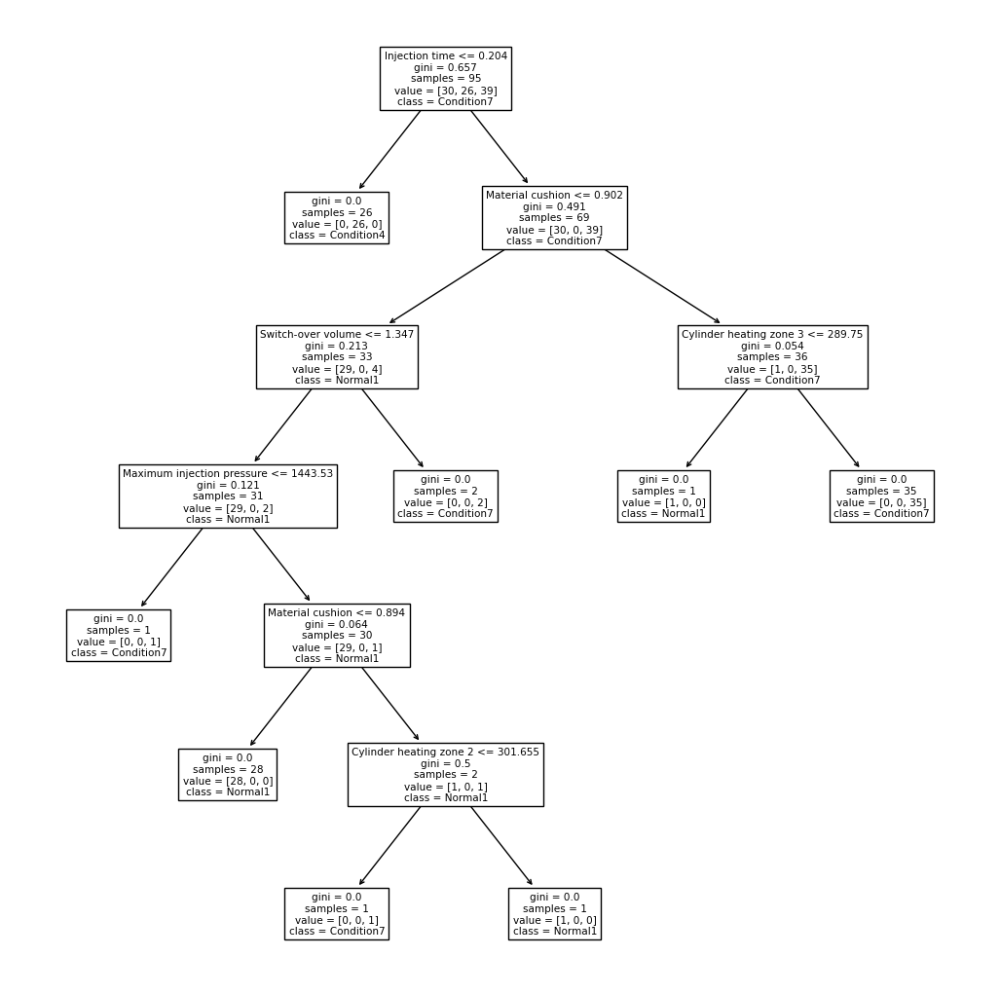

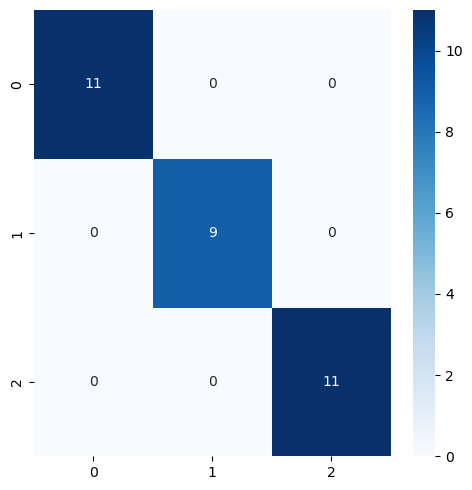

In [12]:
#define decision model
model_name = 'Decision Tree'
model2 = dt(random_state=0)

#split data into 3/4 for training and 1/4 for testing
cv = sk(n_splits=4, shuffle=True, random_state=0)

# accuracy and f1 score list
accuracy_l = []
f1_l = []

# result list
result_matrix =[]

y_series=y.iloc[:,0]

for tr_i, te_i in cv.split(X, y):
    X_tr = X.iloc[tr_i]
    X_v = X.iloc[te_i]
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]
    #print(X_v)
    #print(X_tr)
    print("\ntraining data length:", len(y_tr))
    print("verification data length:", len(y_v))
    
    #fit decision tree model and predict y_p
    model2.fit(X_tr, y_tr)
    y_p = model2.predict(X_v)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_v, y_p)
    print("Accuracy:", f"{accuracy:.4f}")
    accuracy_l.append(accuracy)
    
    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='weighted')
    print("F1 Score:", f"{f1:.4f}")
    f1_l.append(f1)
    
    # plot and save Decision tree 
    fig = plt.figure(figsize=(13, 13))
    # plot tree
    tree.plot_tree(model2, feature_names=X.columns,  class_names=y_series.unique().astype(str), filled=False)
    plt.savefig(decision_tree_save_path + '/' + 'Proj1_' + str(len(accuracy_l)) + 'decision_tree.png')
    
    ### use confusion matrix to compare y_v and y_p, plot and save confusion matrix
    fig, ax = plt.subplots(figsize=(5,5))
    
    #use heatmap
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues')
    plt.tight_layout()
    plt.savefig(decision_tree_save_path + '/' + 'Proj1_' + str(len(accuracy_l)) + 'confusion matrix.png')
    
    #reset the label to original and save the original test data +prediction into a .csv file 
    X_v.reset_index(drop=True, inplace=True)
    y_v.reset_index(drop=True,inplace=True)
    result_matrix = pd.concat([X_v, y_v], axis=1,ignore_index=True)
    result_matrix.loc[:,13] = y_p 
    result_matrix.to_csv(decision_tree_save_path + '/' + 'cv_' + str(len(accuracy_l)) + '.csv', index=False)
    
    print("\nDecision tree Prediction classification report", "\n", classification_report(y_v,y_p))

    normal1_accuracy =  confusion_matrix(y_v,y_p)[0,0] / (confusion_matrix(y_v,y_p)[0,1] + confusion_matrix(y_v,y_p)[0,2] + 
                                                          confusion_matrix(y_v,y_p)[0,0])
    print("Normal1_accuracy:", normal1_accuracy.round(2))
                                        
    condition4_accuracy = confusion_matrix(y_v,y_p)[1,1] / (confusion_matrix(y_v,y_p)[1,0] + confusion_matrix(y_v,y_p)[1,1] + 
                                                            confusion_matrix(y_v,y_p)[1,2])
    print("condition4_accuracy:", condition4_accuracy.round(2))

    condition7_accuracy = confusion_matrix(y_v,y_p)[2,2] / (confusion_matrix(y_v,y_p)[2,0] + confusion_matrix(y_v,y_p)[2,1] + 
                                                            confusion_matrix(y_v,y_p)[2,2])
    print("condition7_accuracy:", condition7_accuracy.round(2))


##  Mean accuracy score and F1 score
m_sc_proj1 = np.mean(accuracy_l)
mean_f1_proj1 = np.mean(f1_l)
print(f'{model_name} Mean Accuracy: {m_sc_proj1:.4f}')
print(f'{model_name} Mean F1 Score: {mean_f1_proj1:.4f}')

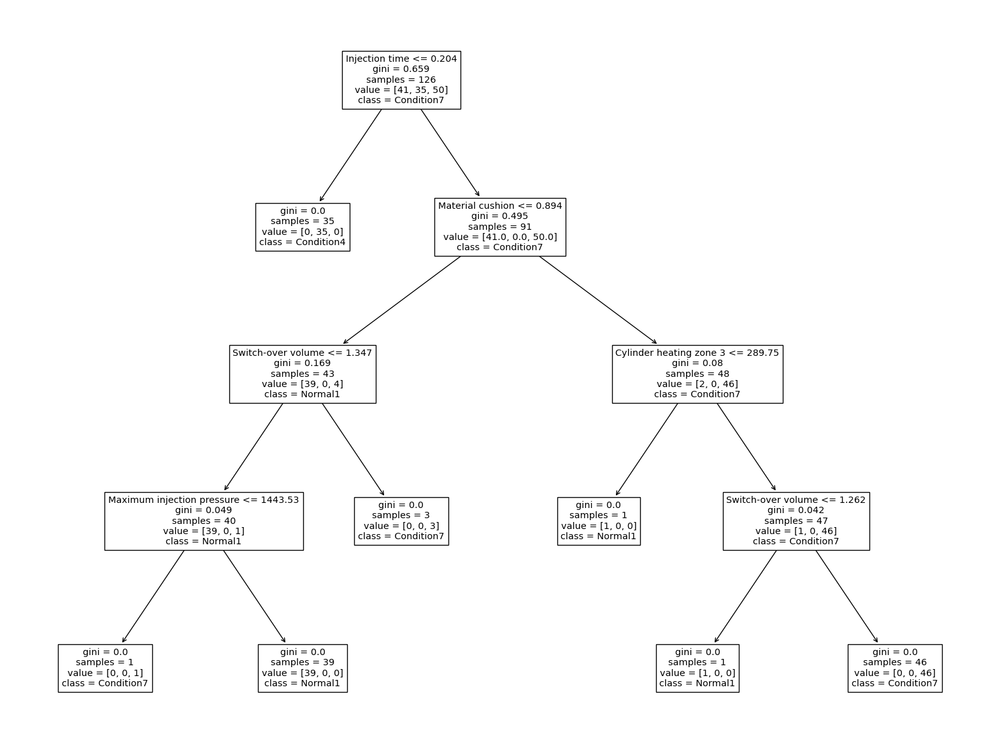

In [13]:
#Create decision tree classifier object and Controlling Tree Parameters
# import libraries
from sklearn.tree import DecisionTreeClassifier
from sklearn import datasets
from sklearn import tree
#Load data

features=X
target=y
# Create decision tree classifier object and Controlling Tree Parameters
decisiontree = DecisionTreeClassifier(random_state=0,                                      
                                        max_depth=8,   #max depth is how much it will brnach down                                
                                        min_samples_split=2,                                      
                                        min_samples_leaf=1,                                                                         
                                        max_leaf_nodes=None,                                      
                                        min_impurity_decrease=0)
# Train model
model1 = decisiontree.fit(features, target)

#plot and save a decision tree
# define figure size
fig = plt.figure(figsize=(20, 15))

# plot tree
tree.plot_tree(model1, feature_names=X.columns,  class_names=y_series.unique().astype(str), filled=False)

#save tree
plt.savefig(decision_tree_save_path + '/' + 'Proj1_' + 'mydecision_tree1.png')

### GRIDSEARCH

In [15]:
a = confusion_matrix(y_v,y_p)

In [16]:
#The hyperparameter values are organized into a dictionary format to facilitate their integration with GridSearchCV.
model_params  = {
    "criterion": ['gini', 'entropy'], #this two here reeplace with gamma and C for the sbf
    "max_depth": range(1, 13),
    "min_samples_split": range(2, 13),  # Starting from 2 as 1 would result in no splitting
    "min_samples_leaf": range(1, 13)
}

In [17]:
start_time = time.time()
# create Decision Tree classifier model
dt_model = dt(random_state=0)

# set up grid search
clf = GridSearchCV(dt_model, model_params, cv=4)

# train the grid search to find the best model
model = clf.fit(X, y)

# print winning set of hyperparameters
print(model.best_params_)
end_time = time.time()
total_time = end_time - start_time
print(f"The program took {round(total_time,0)} seconds to run.")

{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
The program took 64.0 seconds to run.


training data length: 94
verification data length: 32
Accuracy: 0.9375
F1 Score: 0.9375
Decision tree Prediction classification report 
               precision    recall  f1-score   support

  Condition4       0.89      0.89      0.89         9
  Condition7       1.00      1.00      1.00         9
     Normal1       0.93      0.93      0.93        14

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32

Normal1_accuracy: 1.0
condition4_accuracy: 1.0
condition7_accuracy: 1.0
training data length: 94
verification data length: 32
Accuracy: 0.9375
F1 Score: 0.9375
Decision tree Prediction classification report 
               precision    recall  f1-score   support

  Condition4       0.92      0.92      0.92        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.92      0.92      0.92        12

    accuracy                           0.94        32
 

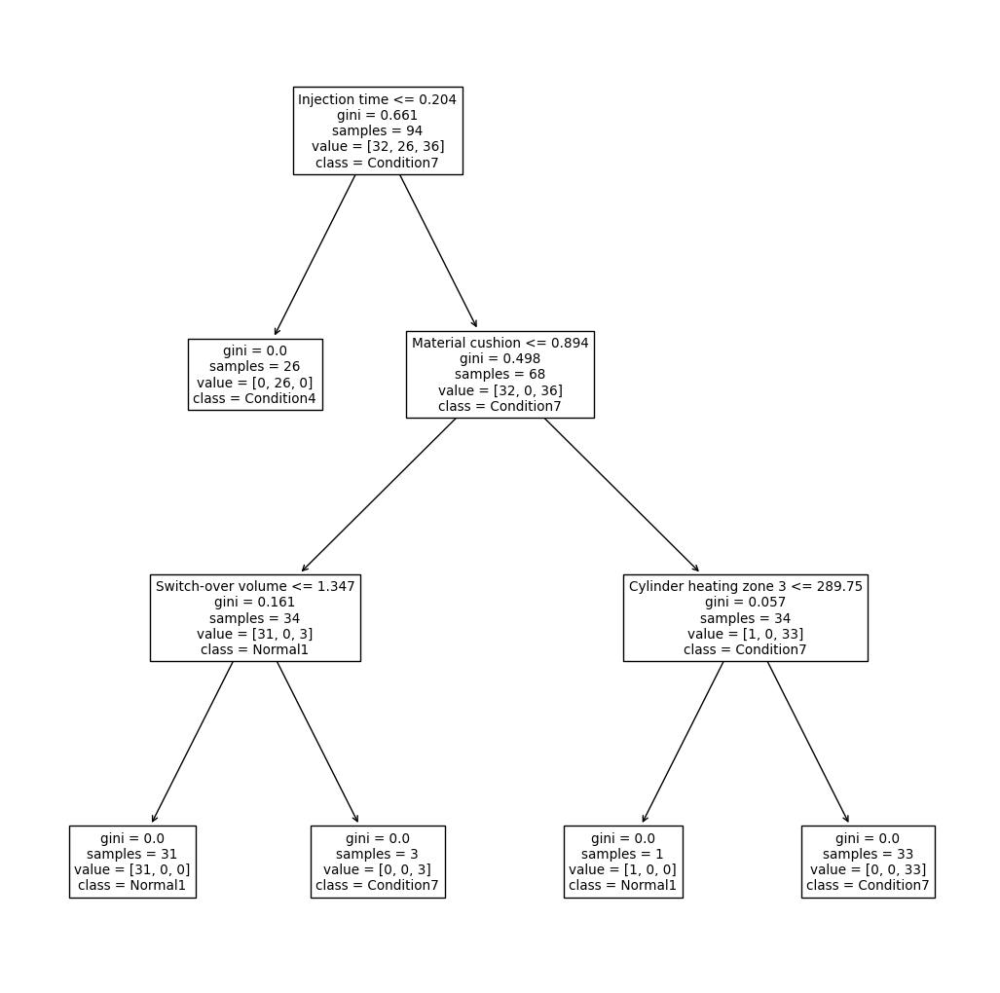

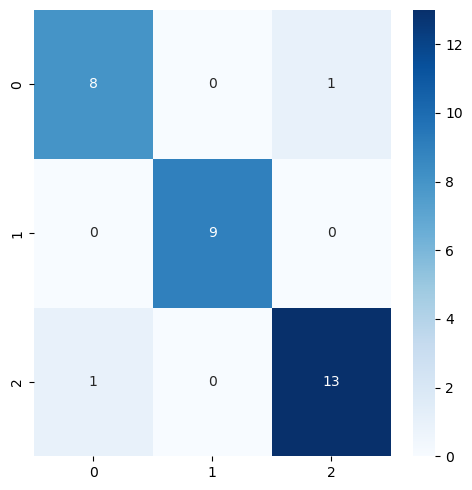

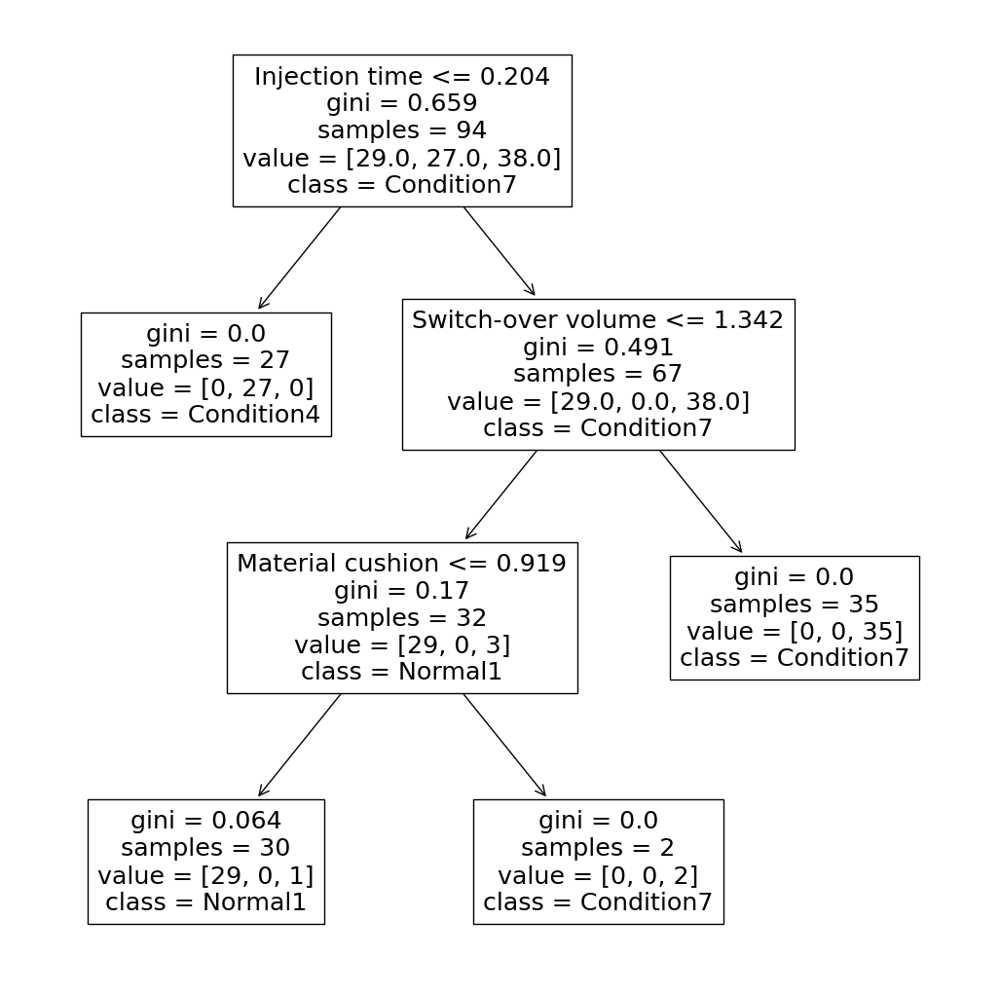

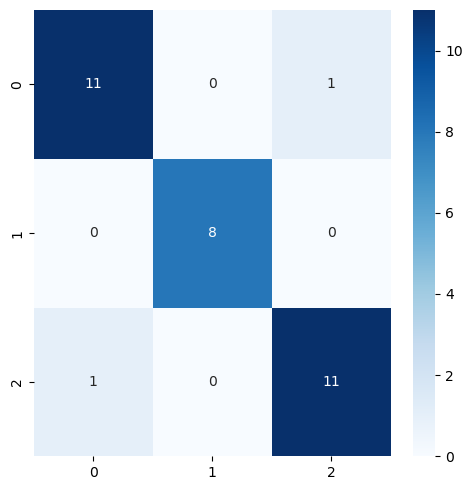

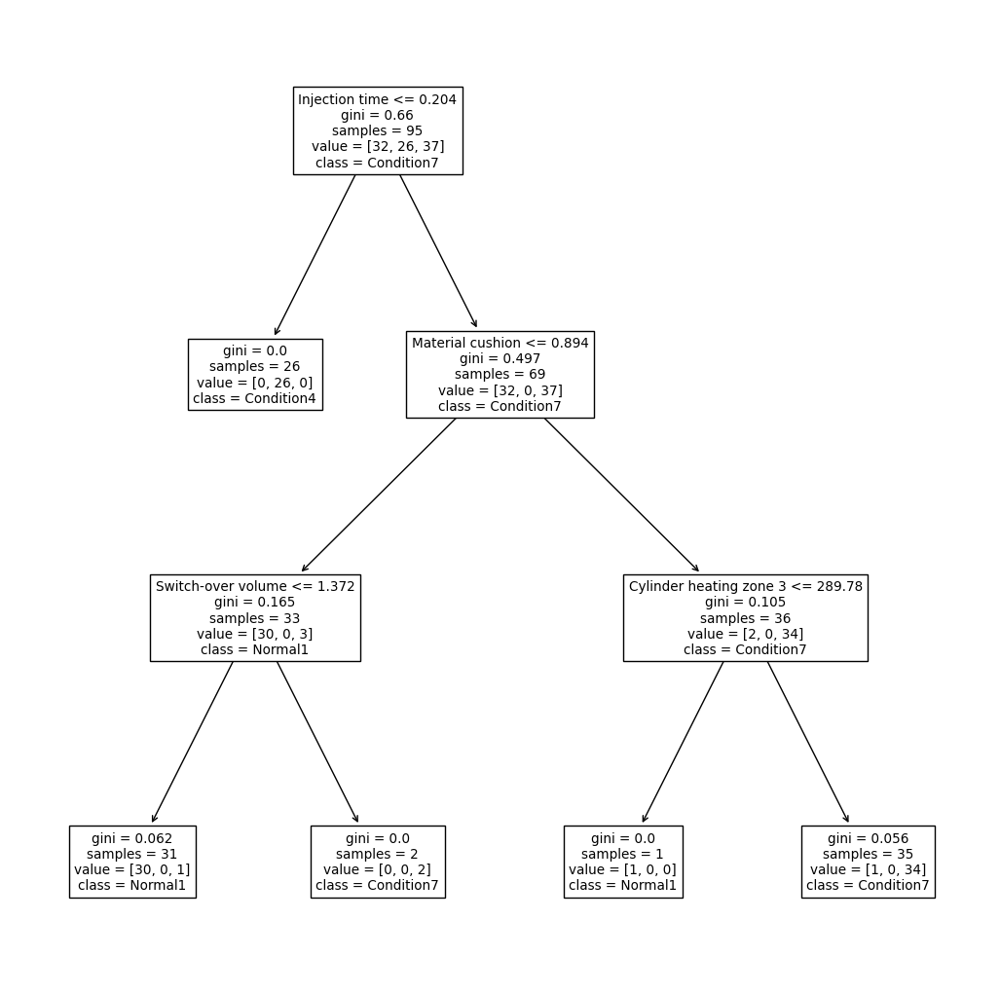

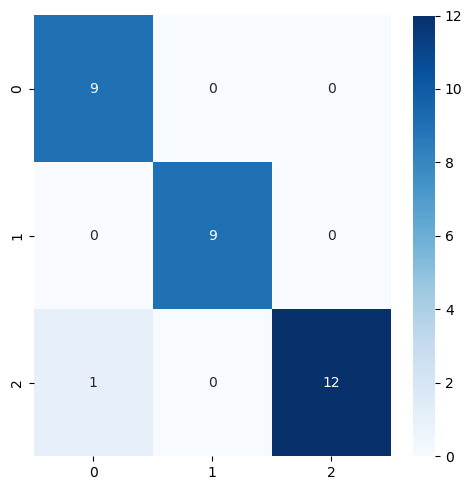

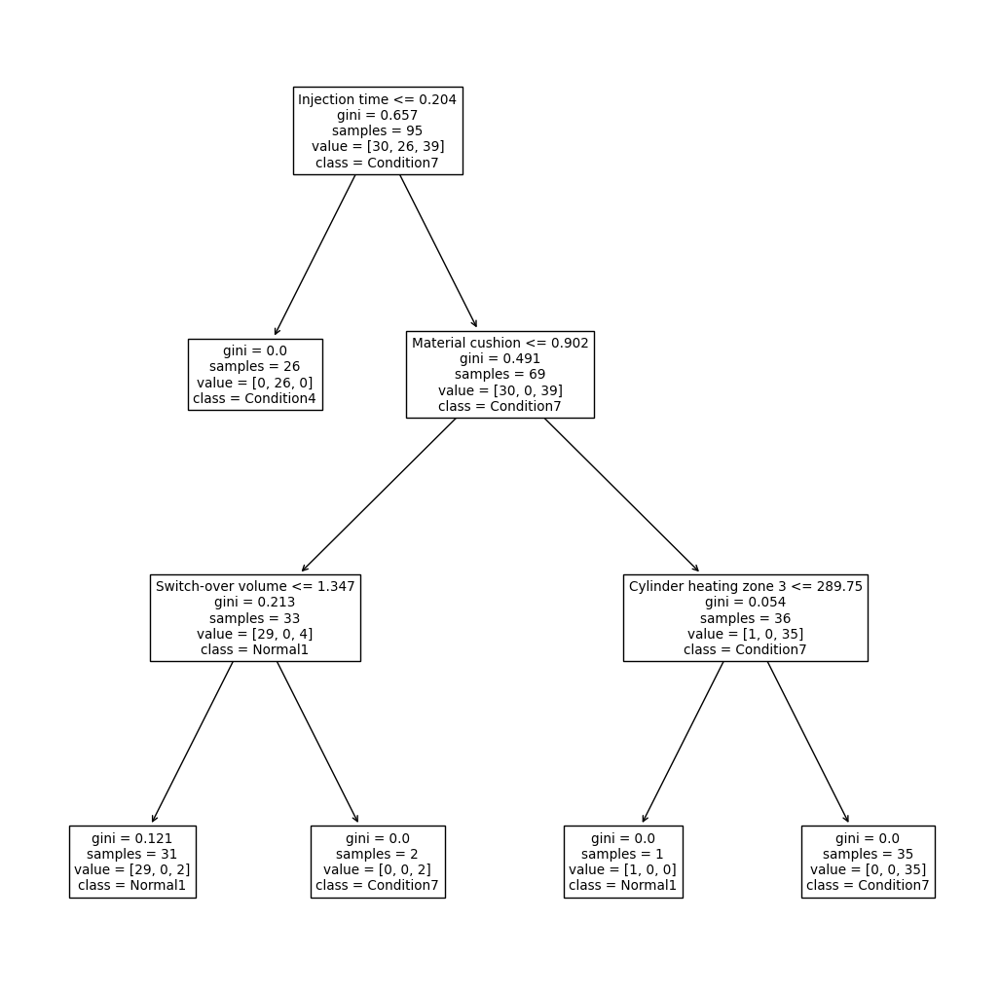

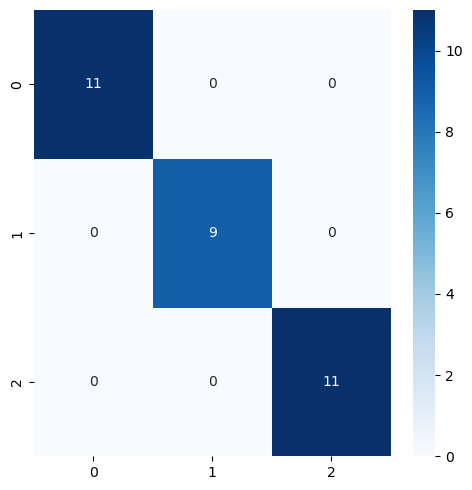

In [18]:
#define decision model
model_name = 'Decision Tree'
model2 = dt(**model.best_params_,random_state=0)

#split data into 3/4 for training and 1/4 for testing
cv = sk(n_splits=4, shuffle=True, random_state=0)

# accuracy list
accuracy_l = []
f1_l = []

# result list
result_matrix =[]

for tr_i, te_i in cv.split(X, y):
    X_tr = X.iloc[tr_i]
    X_v = X.iloc[te_i]
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]
    #print(X_v)
    #print(X_tr)
    print("training data length:", len(y_tr))
    print("verification data length:", len(y_v))
    
    #fit decision tree model and predict y_p
    model2.fit(X_tr, y_tr)
    y_p = model2.predict(X_v)
    
    #calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(4))
    accuracy_l.append(accuracy)
    #calc f1
    f1 = f1_score(y_v, y_p, average='weighted')
    print("F1 Score:", f"{f1:.4f}")
    f1_l.append(f1)
    
    # plot and save Decision tree 
    fig = plt.figure(figsize=(13, 13))
    # plot tree
    tree.plot_tree(model2, feature_names=X.columns,  class_names=y_series.unique().astype(str), filled=False)    
    plt.savefig(grid_search_save_path + '/' + '(Gridsearch)proj1_' + str(len(accuracy_l)) + 'decision_tree.png')
    
    ### use confusion matrix to compare y_v and y_p, plot and save confusion matrix
    fig, ax = plt.subplots(figsize=(5,5))
    
    #use heatmap
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues')
    plt.tight_layout()
    plt.savefig(grid_search_save_path + '/' + '(Gridsearch)proj1_' + str(len(accuracy_l)) + 'confusion matrix.png')
    
    #reset the label to original and save the original test data +prediction into a .csv file 
    X_v.reset_index(drop=True, inplace=True)
    y_v.reset_index(drop=True,inplace=True)
    #print(X_v)
    #print(y_v)
    #print(y_p)
    result_matrix = pd.concat([X_v, y_v], axis=1,ignore_index=True)
    result_matrix.loc[:,13] = y_p 
    #print("Result matrix")
    #print(result_matrix)
    result_matrix.to_csv(grid_search_save_path + '/' + 'cv_' + str(len(accuracy_l)) + '.csv', index=False)
    print("Decision tree Prediction classification report", "\n", classification_report(y_v,y_p))

    normal1_accuracy =  a[0,0] / (a[0,1]+a[0,2]+a[0,0])
    print("Normal1_accuracy:", normal1_accuracy.round(2))
                                        
    condition4_accuracy = a[1,1] / (a[1,0] + a[1,1] + a[1,2])
    print("condition4_accuracy:", condition4_accuracy.round(2))

    condition7_accuracy = a[2,2] / (a[2,0] + a[2,1] + a[2,2])
    print("condition7_accuracy:", condition7_accuracy.round(2))
    
##  Mean accuracy score and F1 score
m_sc = np.mean(accuracy_l)
mean_f1 = np.mean(f1_l)
print(f'{model_name} Mean Accuracy: {m_sc:.4f}')
print(f'{model_name} Mean F1 Score: {mean_f1:.4f}')

### RANDOMSEARCH

In [20]:
#The hyperparameter distributions are set up as a dictionary so they can be passed to RandomizedSearchCV.
model_params = {
    'criterion': ['gini', 'entropy'],  # Categorical, hence list
    'max_depth': randint(1, 13),  # Uniform distribution over [1, 5) for max_depth
    'min_samples_split': randint(2, 13),  # Uniform distribution over [2, 5) for min_samples_split
    'min_samples_leaf': randint(1, 13)  # Uniform distribution over [1, 5) for min_samples_leaf
}
#Uniform Sampling: randint samples from a uniform distribution over the given range, meaning every integer within the range is equally likely to be chosen. 
#This uniformity ensures that no particular segment of a range is favored over another, providing a fair sampling of all possible integer values.
#By sampling uniformly, randint helps in thoroughly exploring the hyperparameter space. This can be particularly 
#advantageous when the relationship between the hyperparameter and the model's performance is not linear or well-understood.

In [21]:
start_time = time.time()
# create Decision Tree classifier model
dt_model = dt(random_state=0)

# set up random search meta-estimator
# The number of iterations (n_iter) controls how many different combinations are tried.
clf = RandomizedSearchCV(dt_model, model_params, n_iter=200, cv=4, random_state=0)

# train the random search to find the best model out of 100 candidates
model = clf.fit(X, y)

# print winning set of hyperparameters
print(model.best_params_)
end_time = time.time()
total_time = end_time - start_time
print(f"The program took {round(total_time,0)} seconds to run.")

{'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 5}
The program took 4.0 seconds to run.


training data length: 94
verification data length: 32
Accuracy: 0.9375
F1 Score: 0.9375
Decision tree Prediction classification report 
               precision    recall  f1-score   support

  Condition4       0.89      0.89      0.89         9
  Condition7       1.00      1.00      1.00         9
     Normal1       0.93      0.93      0.93        14

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32

Normal1_accuracy: 1.0
condition4_accuracy: 1.0
condition7_accuracy: 1.0
training data length: 94
verification data length: 32
Accuracy: 0.9062
F1 Score: 0.9061
Decision tree Prediction classification report 
               precision    recall  f1-score   support

  Condition4       0.91      0.83      0.87        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.85      0.92      0.88        12

    accuracy                           0.91        32
 

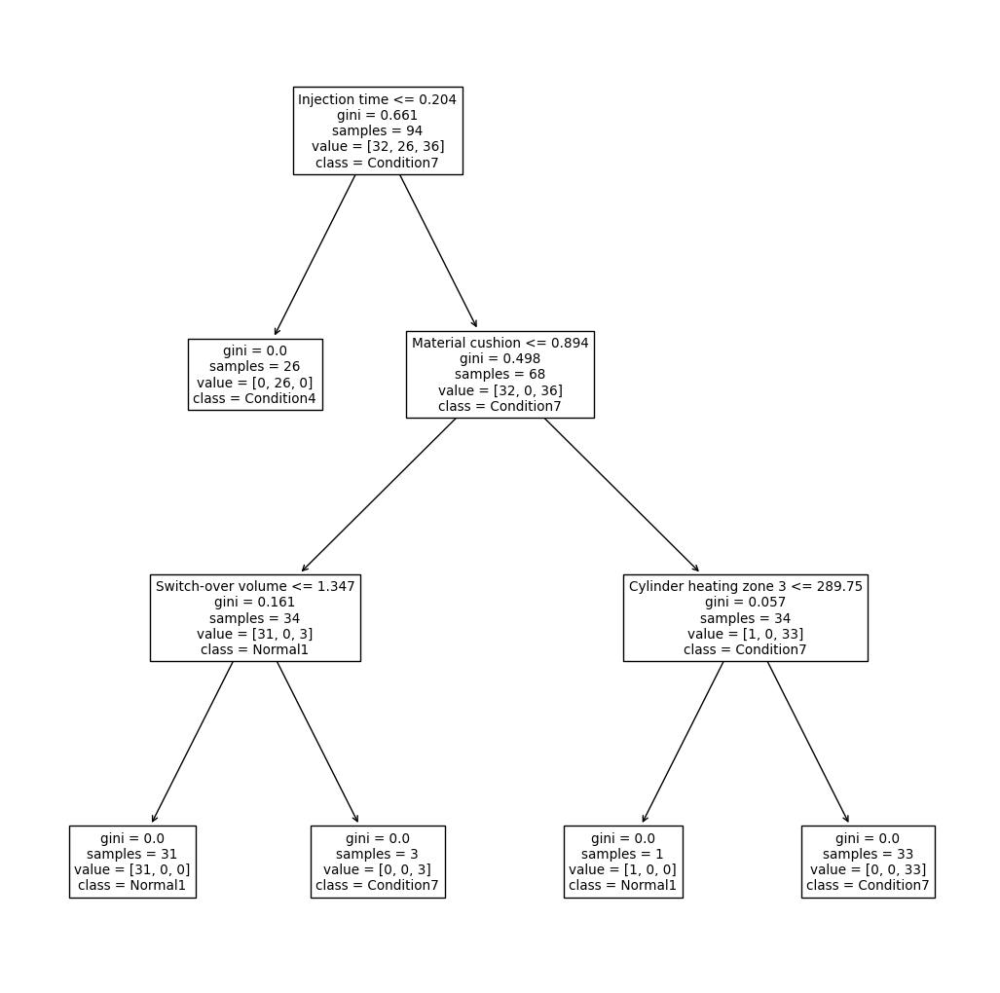

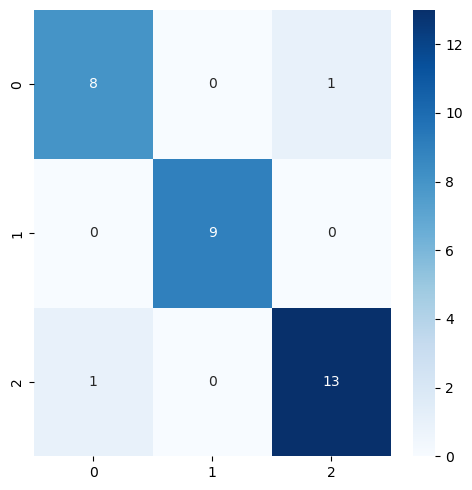

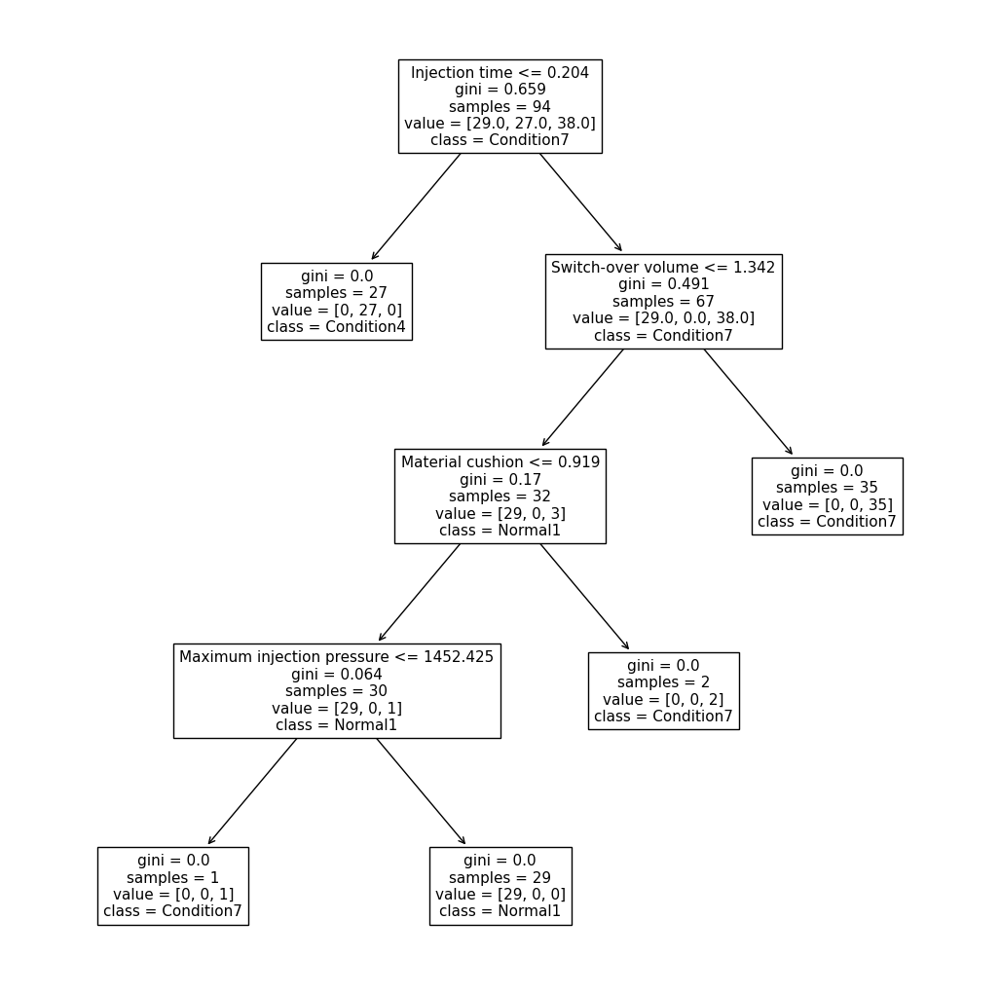

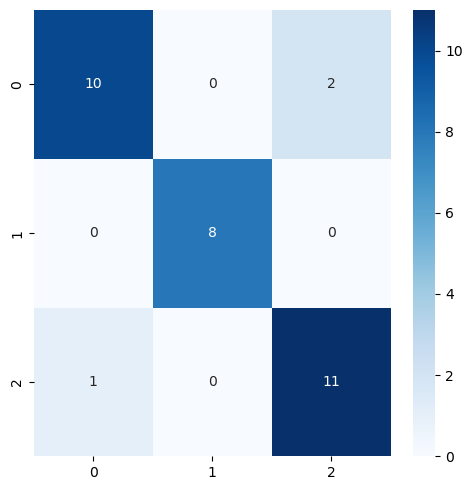

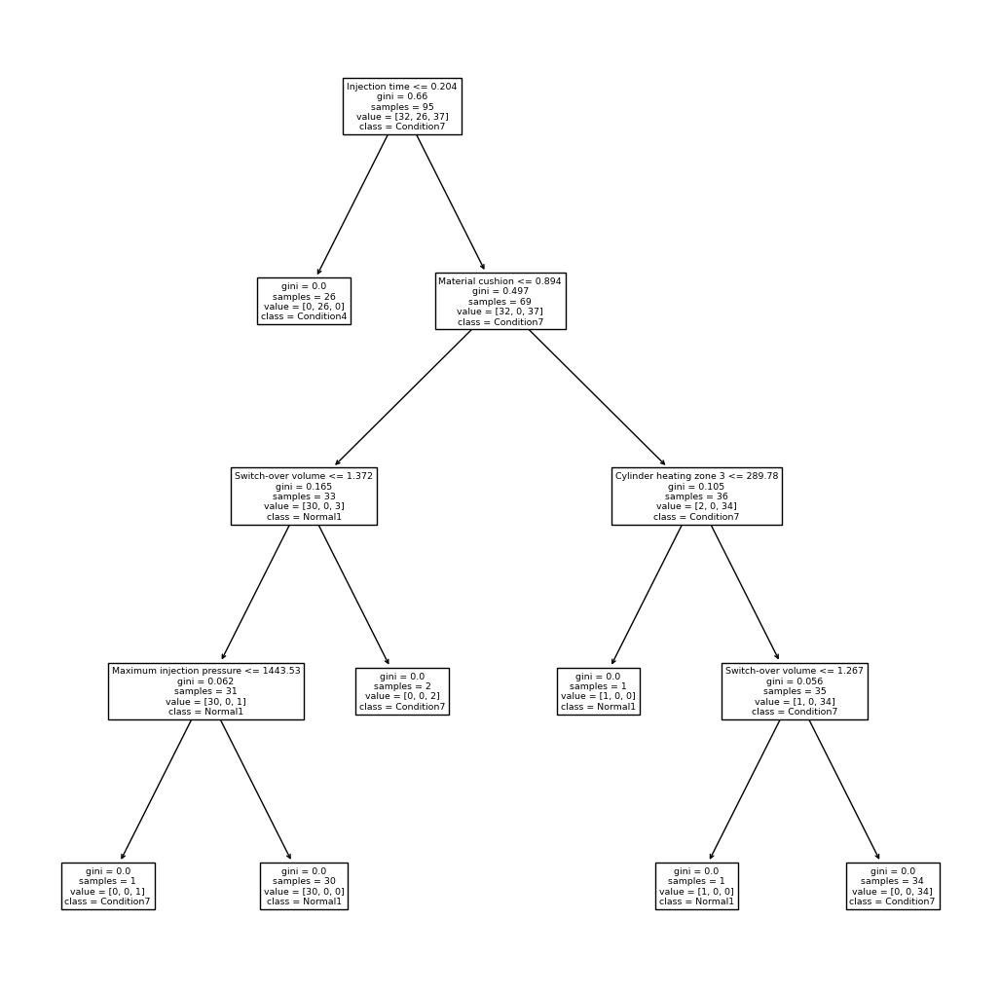

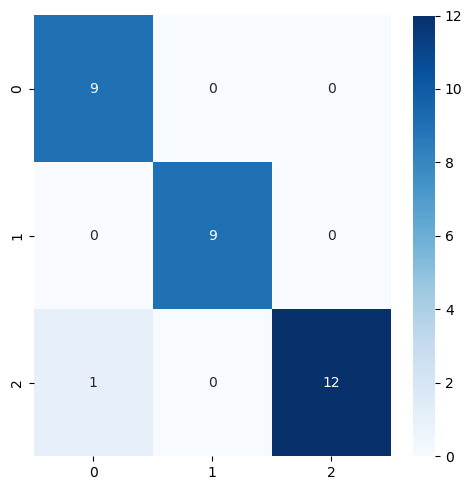

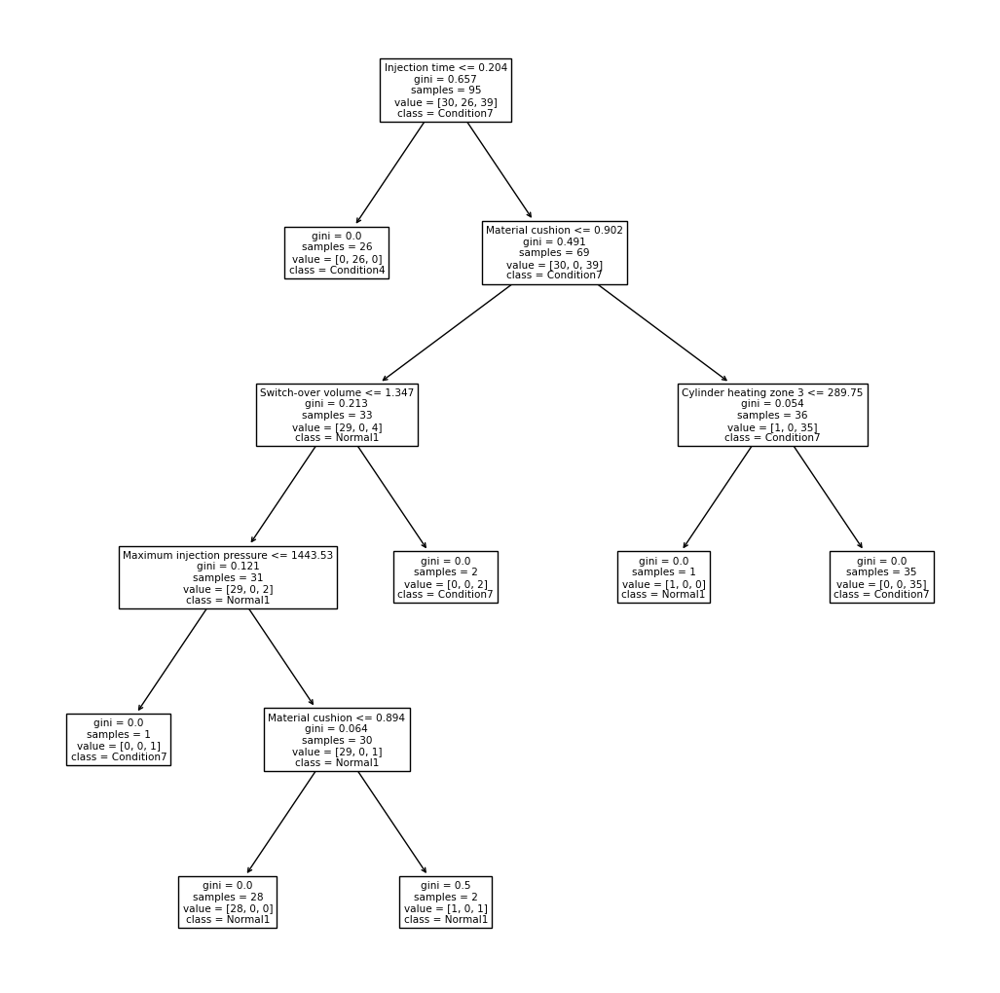

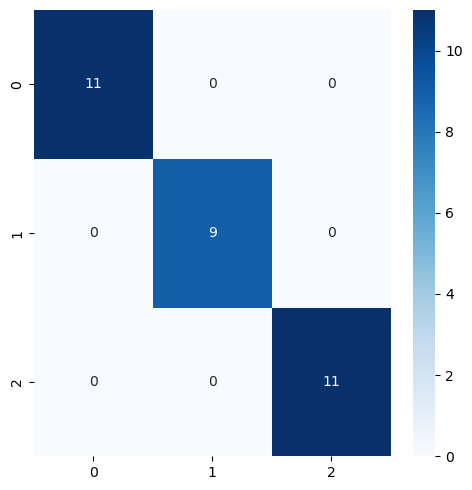

In [22]:
#define decision model
model_name = 'Decision Tree'
model2 = dt(**model.best_params_,random_state=0)

#split data into 3/4 for training and 1/4 for testing
cv = sk(n_splits=4, shuffle=True, random_state=0)
# accuracy list
accuracy_l = []
#f1 list
f1_l = []
# result list
result_matrix =[]

for tr_i, te_i in cv.split(X, y):
    X_tr = X.iloc[tr_i]
    X_v = X.iloc[te_i]
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]
    #print(X_v)
    #print(X_tr)
    print("training data length:", len(y_tr))
    print("verification data length:", len(y_v))
    
    #fit decision tree model and predict y_p
    model2.fit(X_tr, y_tr)
    y_p = model2.predict(X_v)
    
    #calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(4))
    accuracy_l.append(accuracy)
    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='weighted')
    print("F1 Score:", f"{f1:.4f}")
    f1_l.append(f1)
    
    # plot and save Decision tree 
    fig = plt.figure(figsize=(13, 13))
    # plot tree
    tree.plot_tree(model2, feature_names=X.columns,  class_names=y_series.unique().astype(str), filled=False)
    plt.savefig(random_search_save_path + '/' + '(RandomizedSearch)Proj1_' + str(len(accuracy_l)) + 'decision_tree.png')
    
    ### use confusion matrix to compare y_v and y_p, plot and save confusion matrix
    fig, ax = plt.subplots(figsize=(5,5))
    
    #use heatmap
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues')
    plt.tight_layout()
    plt.savefig(random_search_save_path + '/' + '(RandomizedSearch)Proj1_' + str(len(accuracy_l)) + 'confusion matrix.png')
    
    #reset the label to original and save the original test data +prediction into a .csv file 
    X_v.reset_index(drop=True, inplace=True)
    y_v.reset_index(drop=True,inplace=True)
    #print(X_v)
    #print(y_v)
    #print(y_p)
    result_matrix = pd.concat([X_v, y_v], axis=1,ignore_index=True)
    result_matrix.loc[:,13] = y_p 
    #print("Result matrix")
    #print(result_matrix)
    result_matrix.to_csv(random_search_save_path + '/' + 'cv_' + str(len(accuracy_l)) + '.csv', index=False)
    print("Decision tree Prediction classification report", "\n", classification_report(y_v,y_p))

    normal1_accuracy =  a[0,0] / (a[0,1]+a[0,2]+a[0,0])
    print("Normal1_accuracy:", normal1_accuracy.round(2))
                                        
    condition4_accuracy = a[1,1] / (a[1,0] + a[1,1] + a[1,2])
    print("condition4_accuracy:", condition4_accuracy.round(2))

    condition7_accuracy = a[2,2] / (a[2,0] + a[2,1] + a[2,2])
    print("condition7_accuracy:", condition7_accuracy.round(2))
    
##  Mean accuracy score and F1 score
m_sc = np.mean(accuracy_l)
mean_f1 = np.mean(f1_l)
print(f'{model_name} Mean Accuracy: {m_sc:.4f}')
print(f'{model_name} Mean F1 Score: {mean_f1:.4f}')


### SUMMARY OF DT USING F1 AND ACCURACY

Evaluating Default Decision Tree:

Default Decision Tree Classification Report for Fold 1:
               precision    recall  f1-score   support

  Condition4       0.90      0.90      0.90        10
  Condition7       1.00      1.00      1.00         9
     Normal1       0.92      0.92      0.92        13

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32



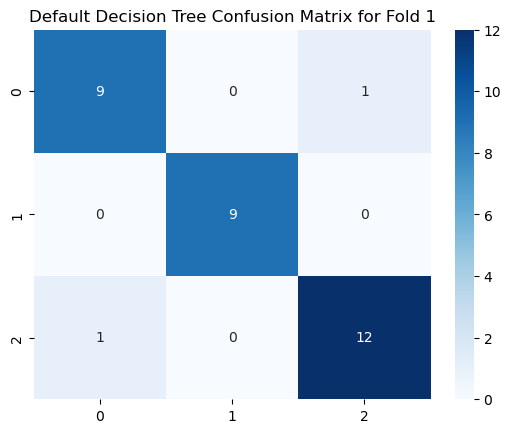


Default Decision Tree Classification Report for Fold 2:
               precision    recall  f1-score   support

  Condition4       0.90      0.90      0.90        10
  Condition7       1.00      1.00      1.00         9
     Normal1       0.92      0.92      0.92        13

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32



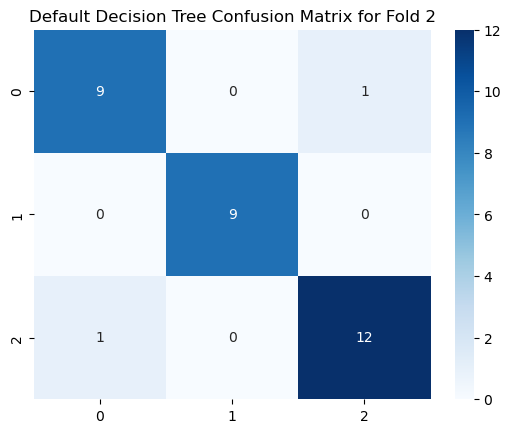


Default Decision Tree Classification Report for Fold 3:
               precision    recall  f1-score   support

  Condition4       0.92      1.00      0.96        11
  Condition7       1.00      1.00      1.00         8
     Normal1       1.00      0.92      0.96        12

    accuracy                           0.97        31
   macro avg       0.97      0.97      0.97        31
weighted avg       0.97      0.97      0.97        31



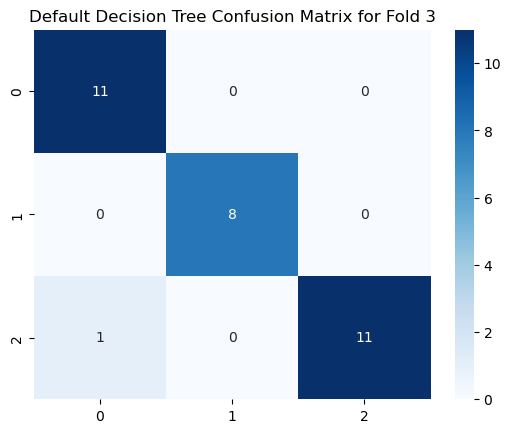


Default Decision Tree Classification Report for Fold 4:
               precision    recall  f1-score   support

  Condition4       0.89      0.80      0.84        10
  Condition7       1.00      1.00      1.00         9
     Normal1       0.85      0.92      0.88        12

    accuracy                           0.90        31
   macro avg       0.91      0.91      0.91        31
weighted avg       0.90      0.90      0.90        31



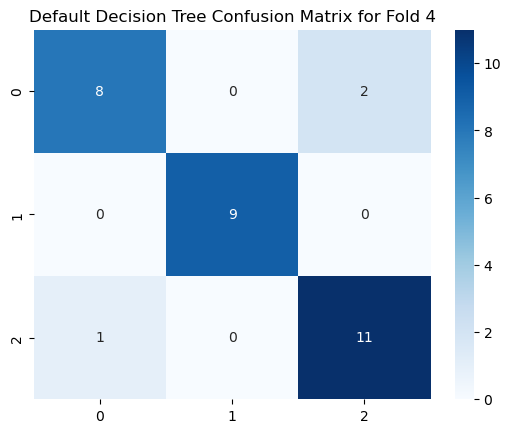


Default Decision Tree Mean Accuracy Score: 0.9365
Default Decision Tree Mean F1 Score: 0.9363

Evaluating GridSearchCV Decision Tree:
Best Parameters from GridSearchCV: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}

GridSearchCV Decision Tree Classification Report for Fold 1:
               precision    recall  f1-score   support

  Condition4       0.91      1.00      0.95        10
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.92      0.96        13

    accuracy                           0.97        32
   macro avg       0.97      0.97      0.97        32
weighted avg       0.97      0.97      0.97        32



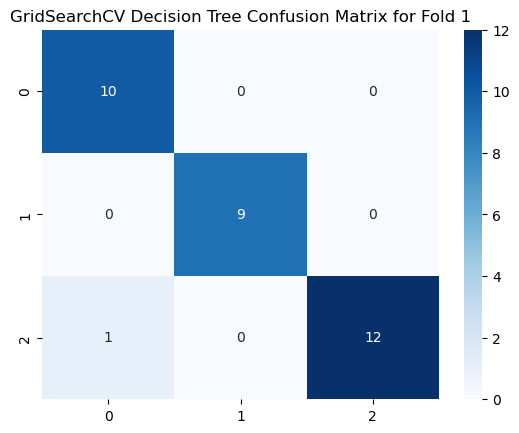


GridSearchCV Decision Tree Classification Report for Fold 2:
               precision    recall  f1-score   support

  Condition4       0.90      0.90      0.90        10
  Condition7       1.00      1.00      1.00         9
     Normal1       0.92      0.92      0.92        13

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32



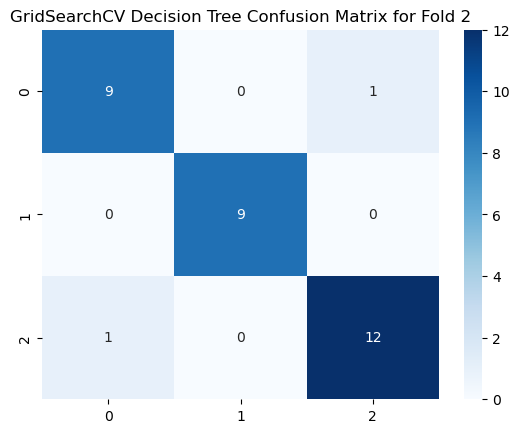


GridSearchCV Decision Tree Classification Report for Fold 3:
               precision    recall  f1-score   support

  Condition4       0.92      1.00      0.96        11
  Condition7       1.00      1.00      1.00         8
     Normal1       1.00      0.92      0.96        12

    accuracy                           0.97        31
   macro avg       0.97      0.97      0.97        31
weighted avg       0.97      0.97      0.97        31



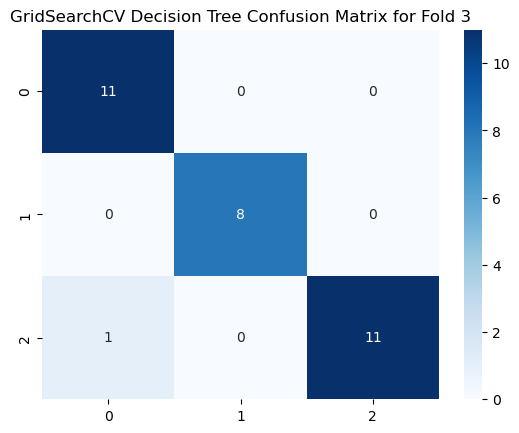


GridSearchCV Decision Tree Classification Report for Fold 4:
               precision    recall  f1-score   support

  Condition4       1.00      0.90      0.95        10
  Condition7       1.00      1.00      1.00         9
     Normal1       0.92      1.00      0.96        12

    accuracy                           0.97        31
   macro avg       0.97      0.97      0.97        31
weighted avg       0.97      0.97      0.97        31



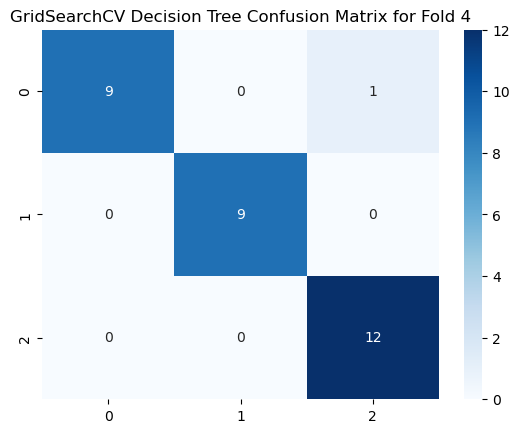


GridSearchCV Decision Tree Mean Accuracy Score: 0.9604
GridSearchCV Decision Tree Mean F1 Score: 0.9604

Evaluating RandomizedSearchCV Decision Tree:
Best Parameters from RandomizedSearchCV: {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 5}

RandomizedSearchCV Decision Tree Classification Report for Fold 1:
               precision    recall  f1-score   support

  Condition4       0.91      1.00      0.95        10
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.92      0.96        13

    accuracy                           0.97        32
   macro avg       0.97      0.97      0.97        32
weighted avg       0.97      0.97      0.97        32



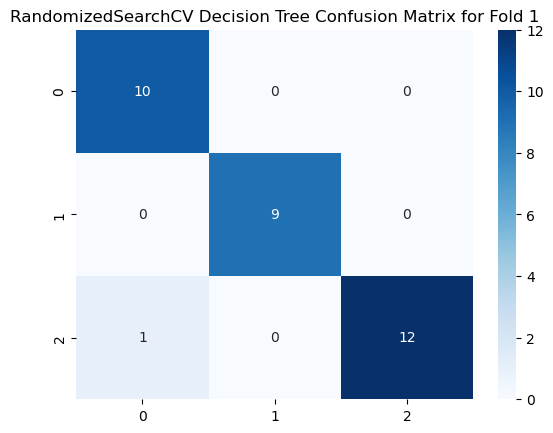


RandomizedSearchCV Decision Tree Classification Report for Fold 2:
               precision    recall  f1-score   support

  Condition4       0.90      0.90      0.90        10
  Condition7       1.00      1.00      1.00         9
     Normal1       0.92      0.92      0.92        13

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32



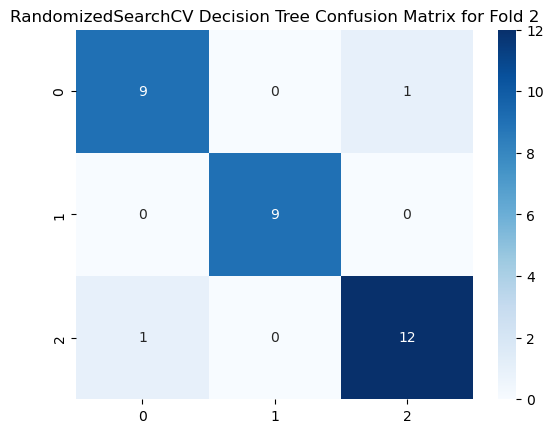


RandomizedSearchCV Decision Tree Classification Report for Fold 3:
               precision    recall  f1-score   support

  Condition4       0.92      1.00      0.96        11
  Condition7       1.00      1.00      1.00         8
     Normal1       1.00      0.92      0.96        12

    accuracy                           0.97        31
   macro avg       0.97      0.97      0.97        31
weighted avg       0.97      0.97      0.97        31



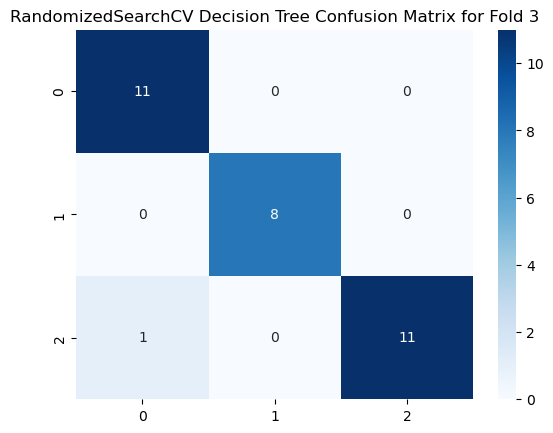


RandomizedSearchCV Decision Tree Classification Report for Fold 4:
               precision    recall  f1-score   support

  Condition4       0.89      0.80      0.84        10
  Condition7       1.00      1.00      1.00         9
     Normal1       0.85      0.92      0.88        12

    accuracy                           0.90        31
   macro avg       0.91      0.91      0.91        31
weighted avg       0.90      0.90      0.90        31



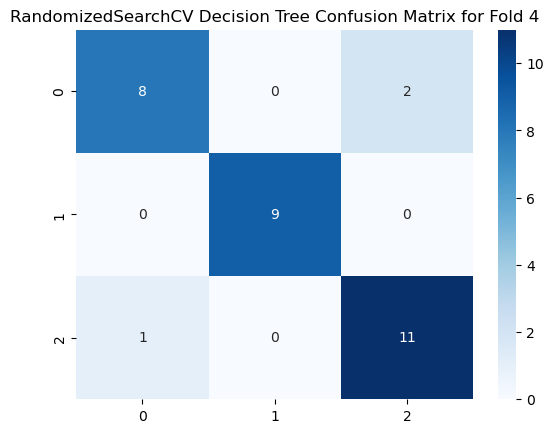


RandomizedSearchCV Decision Tree Mean Accuracy Score: 0.9443
RandomizedSearchCV Decision Tree Mean F1 Score: 0.9442

Summary Table of Average Scores for Each Model:
                              Model  Mean Accuracy  Mean F1 Score
0             Default Decision Tree         0.9365         0.9363
1        GridSearchCV Decision Tree         0.9604         0.9604
2  RandomizedSearchCV Decision Tree         0.9443         0.9442


In [24]:
from sklearn.tree import DecisionTreeClassifier as dt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from scipy.stats import randint
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

df = pd.read_csv("Group 5_CleanedData.csv")
X = df.drop("Condition", axis=1)
y = pd.DataFrame(df["Condition"]) 

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

# Function to evaluate a model and calculate acc and F1 score
def evaluate_model(model, model_name):
    accuracy_l = []
    f1_l = []
    
    for fold, (tr_i, te_i) in enumerate(cv.split(X, y), 1):
        X_tr, X_v = X.iloc[tr_i], X.iloc[te_i]
        y_tr, y_v = y.iloc[tr_i], y.iloc[te_i]

        model.fit(X_tr, y_tr)
        y_p = model.predict(X_v)
        
        # Calculate accuracy and F1 score
        accuracy = accuracy_score(y_v, y_p)
        accuracy_l.append(accuracy)
        
        f1 = f1_score(y_v, y_p, average='weighted')
        f1_l.append(f1)

        #confusion matrix and classification report for each fold (fold1 to 4)
        print(f"\n{model_name} Classification Report for Fold {fold}:\n", classification_report(y_v, y_p))
        sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues')
        plt.title(f"{model_name} Confusion Matrix for Fold {fold}")
        plt.show()

    # Print overall mean accuracy and F1 score
    mean_accuracy = np.mean(accuracy_l)
    mean_f1 = np.mean(f1_l)
    print(f'\n{model_name} Mean Accuracy Score: {mean_accuracy:.4f}')
    print(f'{model_name} Mean F1 Score: {mean_f1:.4f}')
    
    return mean_accuracy, mean_f1

# Default Decision Tree model
model_default = dt(random_state=0)
print("Evaluating Default Decision Tree:")
default_accuracy, default_f1 = evaluate_model(model_default, "Default Decision Tree")

#GridSearchCV para tuning
param_grid = {
    "criterion": ['gini', 'entropy'],
    "max_depth": range(1, 13),
    "min_samples_split": range(2, 13),
    "min_samples_leaf": range(1, 13)
}
grid_search = GridSearchCV(dt(random_state=0), param_grid, cv=4)
print("\nEvaluating GridSearchCV Decision Tree:")
grid_search.fit(X, y)
print("Best Parameters from GridSearchCV:", grid_search.best_params_) #get best params for gridsearch tuning
model_grid = dt(**grid_search.best_params_, random_state=0) #gridsearch model w th eoptimized paras
grid_accuracy, grid_f1 = evaluate_model(model_grid, "GridSearchCV Decision Tree")

#RandomizedSearchCV para tuning
param_dist = {
    "criterion": ['gini', 'entropy'],
    "max_depth": randint(1, 13),
    "min_samples_split": randint(2, 13),
    "min_samples_leaf": randint(1, 13)
}
random_search = RandomizedSearchCV(dt(random_state=0), param_distributions=param_dist, n_iter=200, cv=4, random_state=0)
print("\nEvaluating RandomizedSearchCV Decision Tree:")
random_search.fit(X, y)
print("Best Parameters from RandomizedSearchCV:", random_search.best_params_) #get best params for randomsearch tuning
model_random = dt(**random_search.best_params_, random_state=0) #randomsearch w the optimized paras
random_accuracy, random_f1 = evaluate_model(model_random, "RandomizedSearchCV Decision Tree")

# Store all results in a DataFrame
results_df = pd.DataFrame({
    "Model": ["Default Decision Tree", "GridSearchCV Decision Tree", "RandomizedSearchCV Decision Tree"],
    "Mean Accuracy": [default_accuracy, grid_accuracy, random_accuracy],
    "Mean F1 Score": [default_f1, grid_f1, random_f1]
})

# Round the values to 4 decimal places
results_df = results_df.round({"Mean Accuracy": 4, "Mean F1 Score": 4})

# Display the table of average scores
print("\nSummary Table of Average Scores for Each Model:")
print(results_df)

# Determine the best model based on accuracy and F1 score, for nxt cell
results = {
    "Default Decision Tree": {
        "accuracy": default_accuracy,
        "f1": default_f1,
        "model": model_default,
        "params": model_default.get_params()
    },
    "GridSearchCV Decision Tree": {
        "accuracy": grid_accuracy,
        "f1": grid_f1,
        "model": model_grid,
        "params": grid_search.best_params_
    },
        "RandomizedSearchCV Decision Tree": {
        "accuracy": random_accuracy,
        "f1": random_f1,
        "model": model_random,
        "params": random_search.best_params_
    }
}

#### FIND BEST MODEL


Best Model Summary:
Best Model: GridSearchCV Decision Tree
Mean Accuracy: 0.9604
Mean F1 Score: 0.9604
Best Hyperparameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}

Feature Importances for Full Feature Set:
                             Feature  Importance
6                     Injection time      0.4804
11                  Material cushion      0.4289
10                Switch-over volume      0.0670
9            Cylinder heating zone 3      0.0237
0            Cylinder heating zone 1      0.0000
1            Cylinder heating zone 4      0.0000
2         Maximum injection pressure      0.0000
3   Mould temperature control unit 1      0.0000
4                         Cycle time      0.0000
5            Cylinder heating zone 5      0.0000
7            Cylinder heating zone 2      0.0000
8                        Dosage time      0.0000


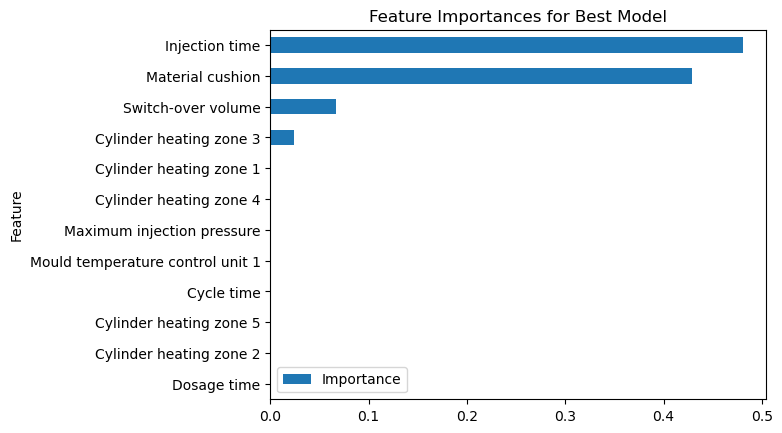

In [26]:
#find the best model 
best_model_name = max(results, key=lambda x: (results[x]["f1"], results[x]["accuracy"]))
best_model = results[best_model_name]["model"]
best_accuracy = results[best_model_name]["accuracy"]
best_f1 = results[best_model_name]["f1"]
best_params = results[best_model_name]["params"]

print("\nBest Model Summary:")
print(f"Best Model: {best_model_name}")
print(f"Mean Accuracy: {best_accuracy:.4f}")
print(f"Mean F1 Score: {best_f1:.4f}")
print("Best Hyperparameters:", best_params)

# Returning the best model with accuracy and F1 score
best_model_info = {
    "model_name": best_model_name,
    "model": best_model,
    "accuracy": round(best_accuracy, 4),
    "f1_score": round(best_f1, 4),
    "hyperparameters": best_params
}
best_model_info

##plot feat impt for full features to compare again w the selected feat later on
#train the best model using all features (before RFE)
best_model.fit(X, y)

#check if feature importances are available for the trained model
try:
    # Extract feature importances for the full feature set
    feature_importances = np.round(best_model.feature_importances_, 4)
    feature_importance_df = pd.DataFrame({
        'Feature': X.columns,  #Uses the full feature set from X
        'Importance': feature_importances
    }).sort_values(by='Importance', ascending=False)

    print("\nFeature Importances for Full Feature Set:")
    print(feature_importance_df)

    #plot feature importances
    feature_importance_df.plot(kind='barh', x='Feature', y='Importance', title="Feature Importances for Best Model")
    plt.gca().invert_yaxis()  #display the highest importance at the top
    plt.show()
except AttributeError:
    print("Feature importance is not available for this model.")


### Feature selection for best hypertuned model (gridsearch), using f1 as imbalanced dataset


Starting RFE feature selection...

Number of Features: 1
Selected Features: ['Injection time']
Mean Accuracy: 0.8248
Mean F1 Score: 0.8061

Number of Features: 2
Selected Features: ['Injection time', 'Switch-over volume']
Mean Accuracy: 0.9133
Mean F1 Score: 0.9135

Number of Features: 3
Selected Features: ['Injection time', 'Switch-over volume', 'Material cushion']
Mean Accuracy: 0.9604
Mean F1 Score: 0.9604

Number of Features: 4
Selected Features: ['Injection time', 'Cylinder heating zone 3', 'Switch-over volume', 'Material cushion']
Mean Accuracy: 0.9604
Mean F1 Score: 0.9604

Number of Features: 5
Selected Features: ['Injection time', 'Dosage time', 'Cylinder heating zone 3', 'Switch-over volume', 'Material cushion']
Mean Accuracy: 0.9604
Mean F1 Score: 0.9604

Number of Features: 6
Selected Features: ['Injection time', 'Cylinder heating zone 2', 'Dosage time', 'Cylinder heating zone 3', 'Switch-over volume', 'Material cushion']
Mean Accuracy: 0.9604
Mean F1 Score: 0.9604

Number

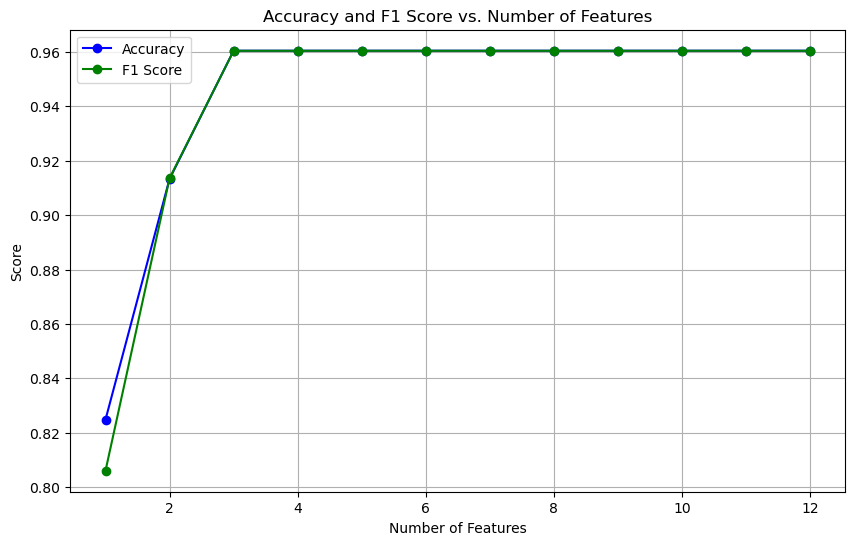

In [28]:
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
import numpy as np

# Use the best model from the previous cell
if best_model_name == "GridSearchCV Decision Tree":
    best_model = model_grid
elif best_model_name == "RandomizedSearchCV Decision Tree":
    best_model = model_random
else:
    best_model = model_default

# Stratified K-Fold for cross-validation
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

# Initialize variables to store the best results
best_accuracy = 0
best_f1_score = 0
best_num_features = 0
best_features = []

#lists to store accuracy and f1 scores for plotting
accuracy_scores = []
f1_scores = []
num_features_list = []

print("\nStarting RFE feature selection...")

# RFE loop to find the optimal number of features
for num_features in range(1, X.shape[1] + 1):
    rfe = RFE(best_model, n_features_to_select=num_features)
    accuracy_list = []
    f1_list = []
    
    for train_index, test_index in cv.split(X, y):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        # Fit RFE model
        rfe.fit(X_train, y_train)
        
        # Predict and evaluate accuracy and F1 score
        y_pred = rfe.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average='weighted')  # Use 'weighted' to handle class imbalance
        
        accuracy_list.append(accuracy)
        f1_list.append(f1)
    
    # Calculate mean accuracy and F1 score for the current number of features
    mean_accuracy = np.mean(accuracy_list)
    mean_f1 = np.mean(f1_list)
    feature_names = X.columns[rfe.support_].tolist()  # Get selected feature names
    
    print(f"\nNumber of Features: {num_features}")
    print(f"Selected Features: {feature_names}")
    print(f"Mean Accuracy: {mean_accuracy:.4f}")
    print(f"Mean F1 Score: {mean_f1:.4f}")

    #store values for plotting
    num_features_list.append(num_features)
    accuracy_scores.append(mean_accuracy)
    f1_scores.append(mean_f1)
    
    # Update best if the current mean F1 score is higher
    if mean_f1 > best_f1_score:
        best_accuracy = mean_accuracy
        best_f1_score = mean_f1
        best_num_features = num_features
        best_features = feature_names

# Display the best number of features and their names
print("\nBest Number of Features:", best_num_features)
print("Feature Names:", best_features)
print(f"Best Accuracy with {best_num_features} features: {best_accuracy:.4f}")
print(f"Best F1 Score with {best_num_features} features: {best_f1_score:.4f}")

##PLOTTING: the accuracy and F1 scores for each number of features
plt.figure(figsize=(10, 6))

#plot acc
plt.plot(num_features_list, accuracy_scores, label='Accuracy', color='blue', marker='o')
#plot f1
plt.plot(num_features_list, f1_scores, label='F1 Score', color='green', marker='o')

#add labels, legend and title t plot
plt.xlabel('Number of Features')
plt.ylabel('Score')
plt.title('Accuracy and F1 Score vs. Number of Features')
plt.legend()

plt.grid(True)
plt.show()

#### REBUILDING MODEL W SELECTED FEATURES

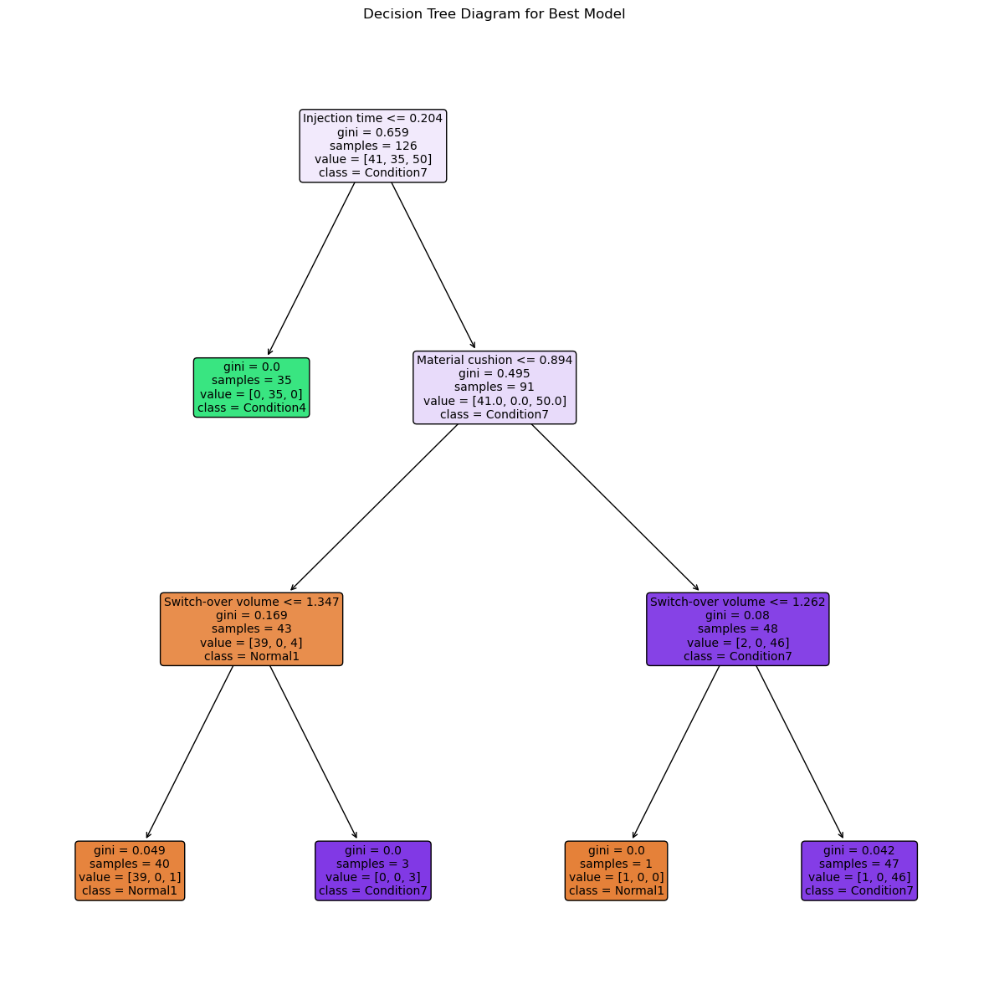


Final_Model Accuracy: 0.9841

Final_Model Classification Report:
               precision    recall  f1-score   support

  Condition4       0.98      0.98      0.98        41
  Condition7       1.00      1.00      1.00        35
     Normal1       0.98      0.98      0.98        50

    accuracy                           0.98       126
   macro avg       0.99      0.99      0.99       126
weighted avg       0.98      0.98      0.98       126

Final_Model F1 Score (Weighted): 0.9841


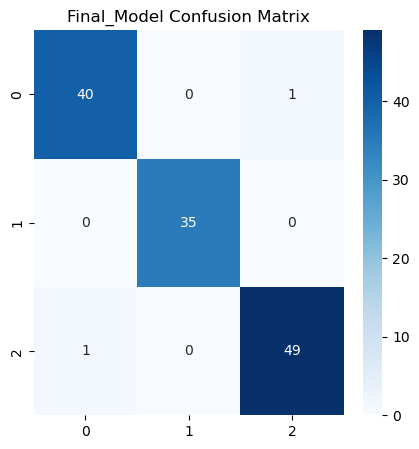


Feature Importances:
              Feature  Importance
0      Injection time      0.4804
2    Material cushion      0.4289
1  Switch-over volume      0.0907


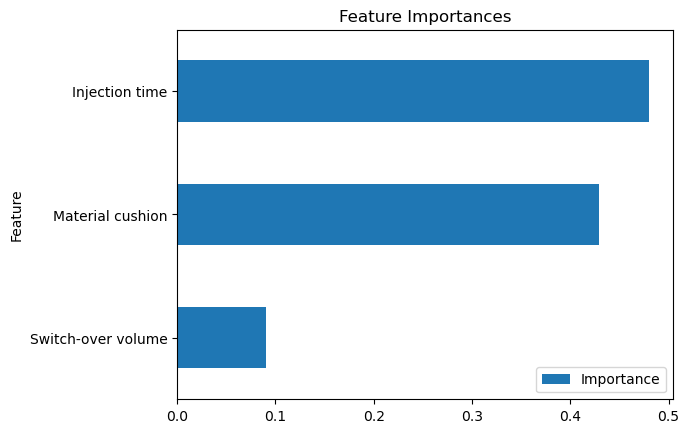

In [30]:
## rebuild model w the 3 features
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn import tree
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

#Train the best hypertuned model on selected features
X_reduced = X[best_features]  # Use only selected features from RFE in cell abovw
# retrain the model with the selected features
best_model.fit(X_reduced, y)

#Plot the decision tree with the reduced features
fig, ax = plt.subplots(figsize=(15, 15))
tree.plot_tree(
    best_model, 
    feature_names=best_features, 
    class_names=y["Condition"].unique().astype(str), 
    filled=True, 
    rounded=True, 
    fontsize=10
)
plt.title("Decision Tree Diagram for Best Model")
plt.show()

# Train the model with the selected features
best_model.fit(X_reduced, y)


# Evaluate the Final Model w f1 and acc included
def evaluate_final_model(model, X_eval, y_eval, model_name="Final_Model"):
    # make pred
    y_pred = model.predict(X_eval)

    # accuracy
    accuracy = accuracy_score(y_eval, y_pred)
    print(f'\n{model_name} Accuracy: {accuracy:.4f}')

    # classification report
    print(f'\n{model_name} Classification Report:\n', classification_report(y_eval, y_pred))

    # Calculate and print overall F1 score (weighted to account for class imbalance, ensures that each class contributes to the overall F1 score in proportion to its presence in the data)
    f1 = f1_score(y_eval, y_pred, average='weighted')
    print(f'{model_name} F1 Score (Weighted): {f1:.4f}')

    # Plot confusion matrix
    fig, ax = plt.subplots(figsize=(5, 5))
    sns.heatmap(confusion_matrix(y_eval, y_pred), annot=True, fmt='d', cmap='Blues', ax=ax)
    plt.title(f'{model_name} Confusion Matrix')
    plt.show()

# Evaluate model w reduced feature set
evaluate_final_model(best_model, X_reduced, y)


#feat impt
try:
    feature_importances = np.round(best_model.feature_importances_,4) 
    feature_importance_df = pd.DataFrame({
        'Feature': best_features,
        'Importance': feature_importances
    }).sort_values(by='Importance', ascending=False)

    print("\nFeature Importances:")
    print(feature_importance_df)

    # Plot feature importances
    feature_importance_df.plot(kind='barh', x='Feature', y='Importance', title="Feature Importances")
    plt.gca().invert_yaxis()
    plt.show()
except AttributeError:
    print("Feature importance is not available for this model.")

## SUPPORT VECTOR MACHINE (SVM)

In [32]:
# Print data (feature) shape 
print("Feature Shape:", X.shape)

Feature Shape: (126, 12)


### Default Linear SVM

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.97
F1 Score: 0.9701


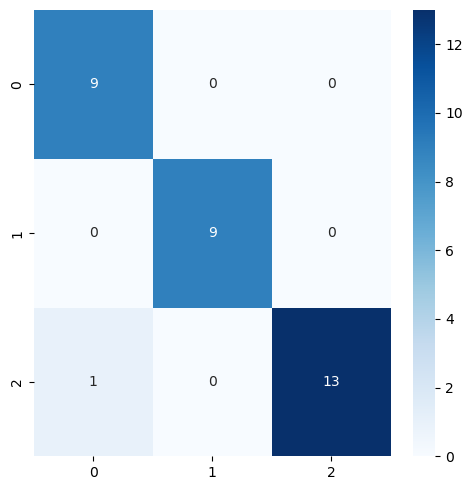

SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.90      1.00      0.95         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.93      0.96        14

    accuracy                           0.97        32
   macro avg       0.97      0.98      0.97        32
weighted avg       0.97      0.97      0.97        32

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.94
F1 Score: 0.9441


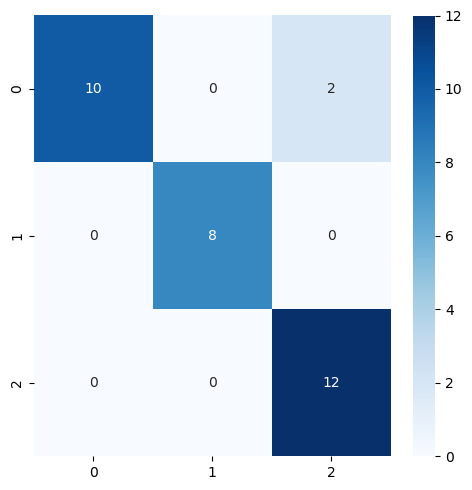

SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      0.83      0.91        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.86      1.00      0.92        12

    accuracy                           0.94        32
   macro avg       0.95      0.94      0.94        32
weighted avg       0.95      0.94      0.94        32

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0


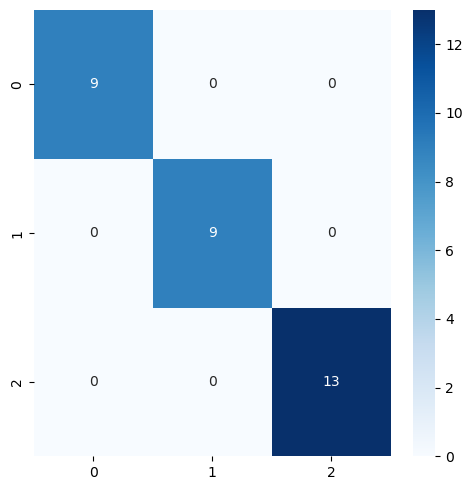

SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        13

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 0.94
F1 Score: 0.9394


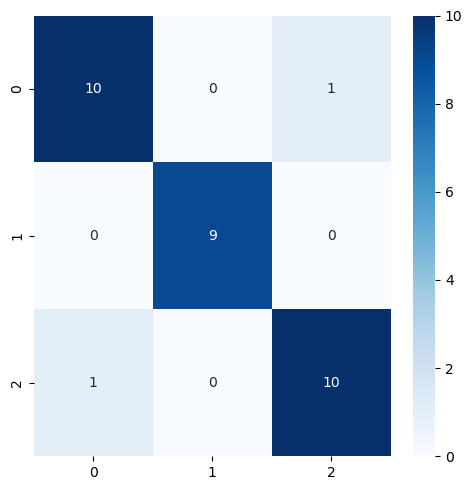

SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.91      0.91      0.91        11
  Condition7       1.00      1.00      1.00         9
     Normal1       0.91      0.91      0.91        11

    accuracy                           0.94        31
   macro avg       0.94      0.94      0.94        31
weighted avg       0.94      0.94      0.94        31

____________________________________________________________

Cross-validation F1 Scores: [0.9701, 0.9441, 1.0, 0.9394]
Mean F1 Score: 0.9634

Cross-validation Accuracies: [0.9688, 0.9375, 1.0, 0.9355]
Mean Accuracy: 0.9604


In [34]:
# Define default SVC model
model_name = 'Linear SVM'
linear_svm = SVC(kernel = 'linear')

# Initialize scaler and cross-validator
scaler = StandardScaler()
cv = sk(n_splits=4, shuffle=True, random_state=0)

# Accuracy list
accuracy_l = []
f1_l = []  

# Result list
result_matrix = []

for tr_i, te_i in cv.split(X, y):
    X_train = X.iloc[tr_i]
    X_test = X.iloc[te_i]
    X_tr = scaler.fit_transform(X_train)
    X_v = scaler.transform(X_test)
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    
    # Fit SVM model with polynomial kernel and predict y_p
    linear_svm.fit(X_tr, y_tr)
    y_p = linear_svm.predict(X_v)
    
    # Calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(2))
    accuracy_l.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l.append(f1)
    
    # Use confusion matrix to compare y_v and y_p, plot, and save it
    fig, ax = plt.subplots(figsize=(5,5))
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues')
    plt.tight_layout()
    plt.savefig(os.path.join(svm_save_path, 'linear_' + str(len(accuracy_l)) + '_confusion_matrix.png'))
    plt.show()
    
    # Generate classification report
    print("SVM classification_report:\n", classification_report(y_v, y_p))

# Summary of cross-validation
mean_accuracy = round(np.mean(accuracy_l), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l])
print("Mean Accuracy:", mean_accuracy)

### Default Polynomial SVM

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.97
F1 Score: 0.9701


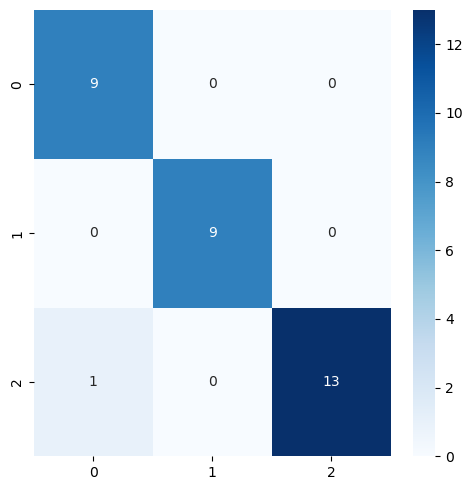

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.90      1.00      0.95         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.93      0.96        14

    accuracy                           0.97        32
   macro avg       0.97      0.98      0.97        32
weighted avg       0.97      0.97      0.97        32

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.88
F1 Score: 0.883


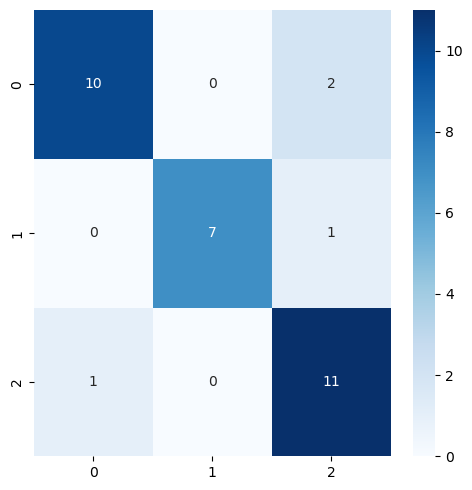

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.91      0.83      0.87        12
  Condition7       1.00      0.88      0.93         8
     Normal1       0.79      0.92      0.85        12

    accuracy                           0.88        32
   macro avg       0.90      0.88      0.88        32
weighted avg       0.89      0.88      0.88        32

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 0.9
F1 Score: 0.9042


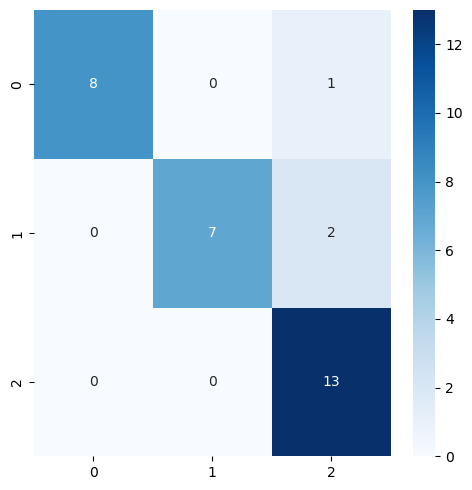

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      0.89      0.94         9
  Condition7       1.00      0.78      0.88         9
     Normal1       0.81      1.00      0.90        13

    accuracy                           0.90        31
   macro avg       0.94      0.89      0.90        31
weighted avg       0.92      0.90      0.90        31

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 0.84
F1 Score: 0.8272


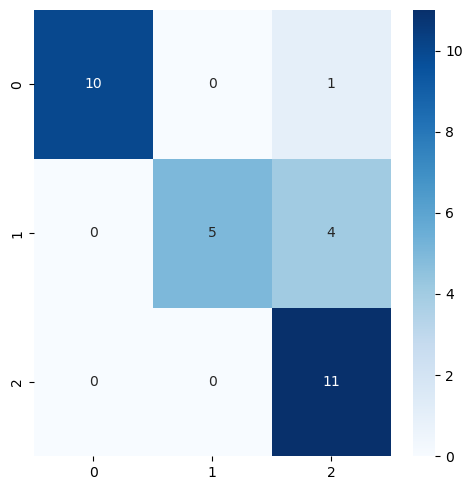

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      0.91      0.95        11
  Condition7       1.00      0.56      0.71         9
     Normal1       0.69      1.00      0.81        11

    accuracy                           0.84        31
   macro avg       0.90      0.82      0.83        31
weighted avg       0.89      0.84      0.83        31

____________________________________________________________

Cross-validation F1 Scores: [0.9701, 0.883, 0.9042, 0.8272]
Mean F1 Score: 0.8961

Cross-validation Accuracies: [0.9688, 0.875, 0.9032, 0.8387]
Mean Accuracy: 0.8964


In [36]:
# Define default SVC model
model_name = 'Polynomial SVM'
poly_svm = SVC(kernel = 'poly', degree = 3, random_state = 0)

# Initialize scaler and cross-validator
scaler = StandardScaler()
cv = sk(n_splits=4, shuffle=True, random_state=0)

# Accuracy list
accuracy_l_poly = []
f1_l_poly = []  

# Result list
result_matrix = []

for tr_i, te_i in cv.split(X, y):
    X_train = X.iloc[tr_i]
    X_test = X.iloc[te_i]
    X_tr = scaler.fit_transform(X_train)
    X_v = scaler.transform(X_test)
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    
    # Fit SVM model with polynomial kernel and predict y_p
    poly_svm.fit(X_tr, y_tr)
    y_p = poly_svm.predict(X_v)
    
    # Calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(2))
    accuracy_l_poly.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_poly.append(f1)
    
    # Use confusion matrix to compare y_v and y_p, plot, and save it
    fig, ax = plt.subplots(figsize=(5,5))
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues')
    plt.tight_layout()
    plt.savefig(os.path.join(svm_save_path, 'poly_' + str(len(accuracy_l_poly)) + '_confusion_matrix.png'))
    plt.show()
    
    # Generate classification report
    print('____________________________________________________________')
    print("SVM classification_report:\n", classification_report(y_v, y_p))

# Summary of cross-validation
mean_accuracy = round(np.mean(accuracy_l_poly), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_poly), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_poly])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_poly])
print("Mean Accuracy:", mean_accuracy)

### DEFAULT RBF SVM

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.97
F1 Score: 0.9701


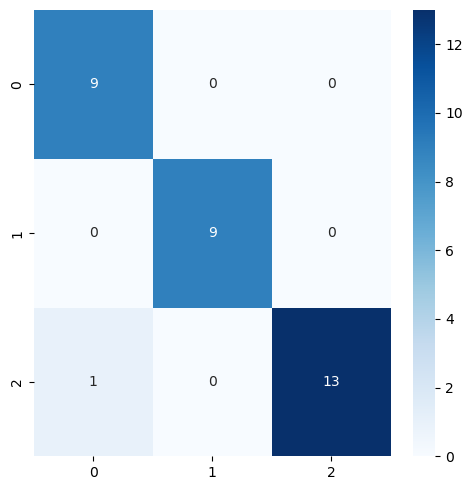

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.90      1.00      0.95         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.93      0.96        14

    accuracy                           0.97        32
   macro avg       0.97      0.98      0.97        32
weighted avg       0.97      0.97      0.97        32

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.91
F1 Score: 0.9165


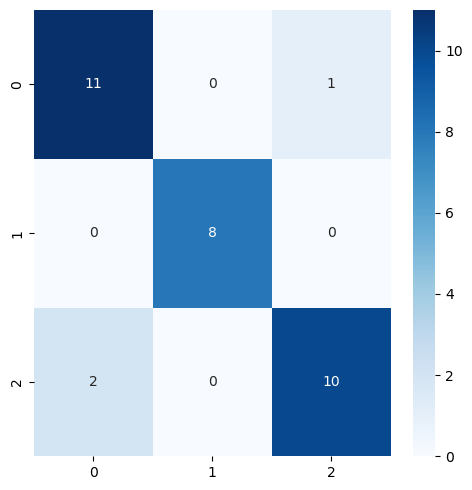

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.85      0.92      0.88        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.91      0.83      0.87        12

    accuracy                           0.91        32
   macro avg       0.92      0.92      0.92        32
weighted avg       0.91      0.91      0.91        32

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 0.97
F1 Score: 0.9691


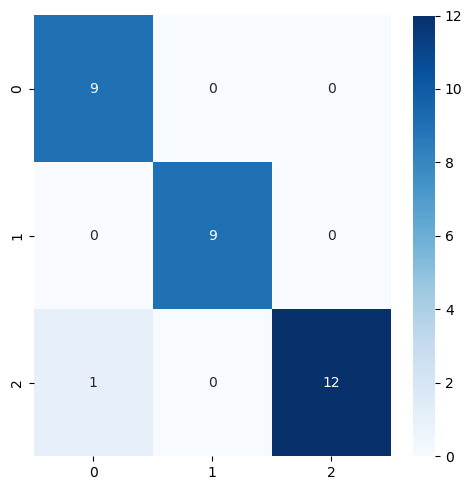

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.90      1.00      0.95         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.92      0.96        13

    accuracy                           0.97        31
   macro avg       0.97      0.97      0.97        31
weighted avg       0.97      0.97      0.97        31

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0


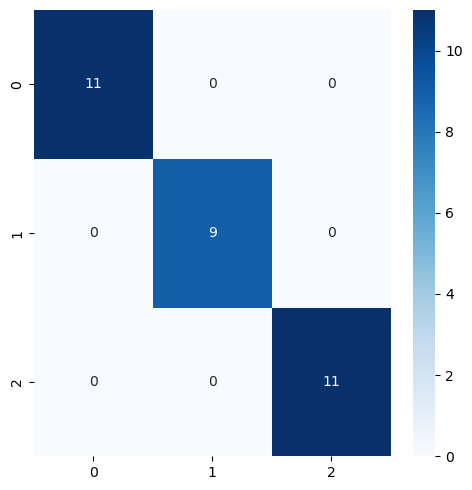

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        11
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        11

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31

____________________________________________________________

Cross-validation F1 Scores: [0.9701, 0.9165, 0.9691, 1.0]
Mean F1 Score: 0.9639

Cross-validation Accuracies: [0.9688, 0.9062, 0.9677, 1.0]
Mean Accuracy: 0.9607


In [38]:
# Define default SVC model
model_name = 'RBF SVM'
rbf_svm = SVC(kernel='rbf', random_state=0)

# Initialize scaler and cross-validator
scaler = StandardScaler()
cv = sk(n_splits=4, shuffle=True, random_state=0)

# Accuracy list
accuracy_l_rbf = []
f1_l_rbf = []  

# Result list
result_matrix = []

for tr_i, te_i in cv.split(X, y):
    X_train = X.iloc[tr_i]
    X_test = X.iloc[te_i]
    X_tr = scaler.fit_transform(X_train)
    X_v = scaler.transform(X_test)
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    
    # Fit SVM model with polynomial kernel and predict y_p
    rbf_svm.fit(X_tr, y_tr)
    y_p = rbf_svm.predict(X_v)
    
    # Calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(2))
    accuracy_l_rbf.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_rbf.append(f1)
    
    # Use confusion matrix to compare y_v and y_p, plot, and save it
    fig, ax = plt.subplots(figsize=(5,5))
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues')
    plt.tight_layout()
    plt.savefig(os.path.join(svm_save_path, 'rbf_' + str(len(accuracy_l_rbf)) + '_confusion_matrix.png'))
    plt.show()
    
    # Generate classification report
    print('____________________________________________________________')
    print("SVM classification_report:\n", classification_report(y_v, y_p))

# Summary of cross-validation
mean_accuracy = round(np.mean(accuracy_l_rbf), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_rbf), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_rbf])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_rbf])
print("Mean Accuracy:", mean_accuracy)

### HYPERPARAMETER TUNING

In [40]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [1, 2, 3, 4],
    'gamma': ['scale', 'auto', 0.001, 0.1],  # Kernel coefficient for ‘rbf’, ‘poly’ and ‘sigmoid’.
    'coef0': [0.0, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0] # Independent term in kernel function. It is only significant in ‘poly’ and ‘sigmoid’.
}

# # for randomsearch
# rand_param_grid = {
#     'C': [0.1, 1, 10, 100, 1000],
#     'kernel': ['linear', 'poly', 'rbf'],
#     'degree': randint(1,4),
#     'gamma': ['scale', 'auto', 0.001, 0.01, 0.1],  # Discrete values for gamma
#     'coef0': [0.0, 0.001, 0.1, 1.0]                  # Discrete values for coef0 (for poly and rbf kernels)
# }

# for randomsearch
rand_param_grid = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'poly', 'rbf'],
    'degree': [2, 3, 4],
    'gamma': uniform(0.001, 1),  # Discrete values for gamma
    'coef0': uniform(0, 1)                # Discrete values for coef0 (for poly and rbf kernels)
}

In [41]:
# Initialize the scaler
scaler = StandardScaler()

# Best Selection of HyperParameters for GridSearch
start_time = time.time()

# create SVM classifier model
grid_base = SVC(random_state=0)

# set up grid search
grid = GridSearchCV(grid_base, param_grid, cv=4, error_score='raise')

# train the grid search to find the best model
X_scaled = scaler.fit_transform(X_train)

grid.fit(X_scaled, y_train)

# print winning set of hyperparameters
grid_best_params = grid.best_params_
print("Grid Search Best Parameters:", grid_best_params)

end_time = time.time()
total_time = end_time - start_time
print(f"The GridSearch program took {round(total_time, 0)} seconds to run.")

# Best Selection of HyperParameters for RandomSearch
start_time = time.time()

rand_base = SVC(random_state=0)

# Set up randomized search
random = RandomizedSearchCV(rand_base, rand_param_grid, n_iter=500, cv=4, random_state=0)

# Train the random search to find the best model
X_scaled = scaler.fit_transform(X_train)
random.fit(X_scaled, y_train)

# Print winning set of hyperparameters
random_best_params = random.best_params_
# Round numeric values to 2 decimal places
rounded_random_best_params = {k: round(v, 2) if isinstance(v, (float, int)) else v for k, v in random_best_params.items()}
print("\nRandom Search Best Parameters:", rounded_random_best_params)

end_time = time.time()
total_time = end_time - start_time
print(f"The Random Search took {round(total_time, 0)} seconds to run.")

Grid Search Best Parameters: {'C': 0.1, 'coef0': 1.0, 'degree': 2, 'gamma': 'scale', 'kernel': 'poly'}
The GridSearch program took 23.0 seconds to run.

Random Search Best Parameters: {'C': 14.58, 'coef0': 0.49, 'degree': 2, 'gamma': 0.03, 'kernel': 'poly'}
The Random Search took 8.0 seconds to run.


### BUILD TUNED MODEL W GRID SEARCH BEST PARAMS

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 1.0
F1 Score: 1.0


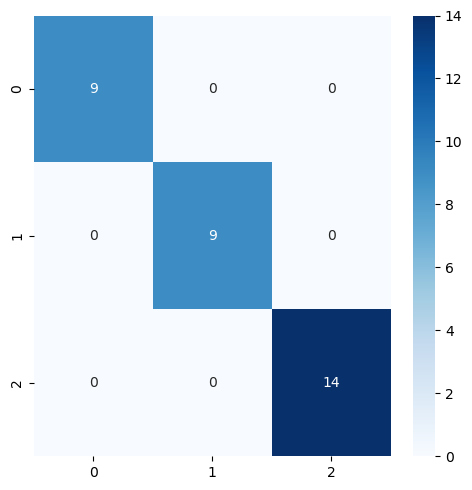

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        14

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.94
F1 Score: 0.9444


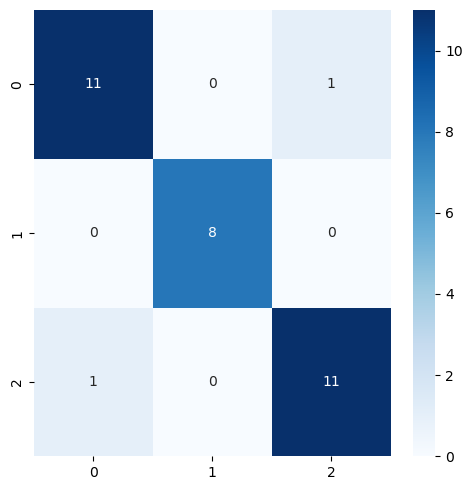

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.92      0.92      0.92        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.92      0.92      0.92        12

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 0.97
F1 Score: 0.9691


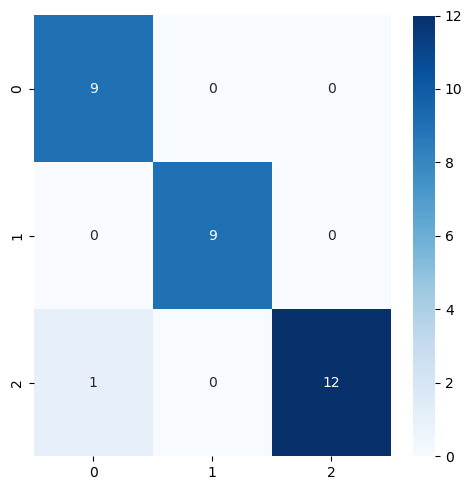

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.90      1.00      0.95         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.92      0.96        13

    accuracy                           0.97        31
   macro avg       0.97      0.97      0.97        31
weighted avg       0.97      0.97      0.97        31

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0


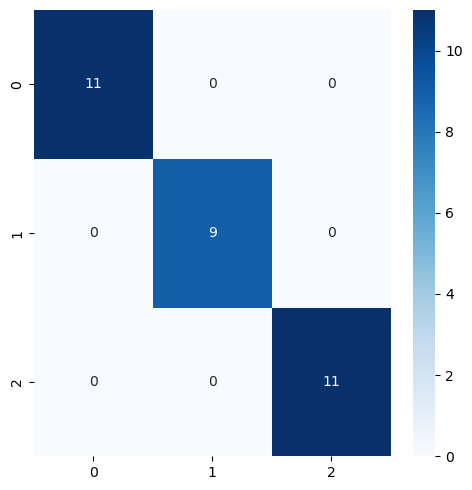

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        11
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        11

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31

____________________________________________________________

Cross-validation F1 Scores: [1.0, 0.9444, 0.9691, 1.0]
Mean F1 Score: 0.9784

Cross-validation Accuracies: [1.0, 0.9375, 0.9677, 1.0]
Mean Accuracy: 0.9763


In [43]:
# polynomial svm
model_name = 'GridSearch Best Params SVM'
grid_svm = SVC(**grid.best_params_, random_state = 0) 

# Initialize scaler and cross-validator
scaler = StandardScaler()
cv = sk(n_splits=4, shuffle=True, random_state=0)

# Accuracy list
accuracy_l_grid = []
f1_l_grid = []

# Result list
result_matrix = []

for tr_i, te_i in cv.split(X, y):
    X_train = X.iloc[tr_i]
    X_test = X.iloc[te_i]
    X_tr = scaler.fit_transform(X_train)
    X_v = scaler.transform(X_test)
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    
    # Fit SVM model with polynomial kernel and predict y_p
    grid_svm.fit(X_tr, y_tr)
    y_p = grid_svm.predict(X_v)
    
    # Calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(2))
    accuracy_l_grid.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_grid.append(f1)
    
    # Use confusion matrix to compare y_v and y_p, plot, and save it
    fig, ax = plt.subplots(figsize=(5,5))
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues')
    plt.tight_layout()
    plt.savefig(os.path.join(tuned_svm_save_path, 'tuned_grid' + str(len(accuracy_l_grid)) + '_confusion_matrix.png'))
    plt.show()
    
    # Generate classification report
    print('____________________________________________________________')
    print("SVM classification_report:\n", classification_report(y_v, y_p))

# Summary of cross-validation
mean_accuracy = round(np.mean(accuracy_l_grid), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_grid), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_grid])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_grid])
print("Mean Accuracy:", mean_accuracy)

### BUILD TUNED MODEL W RANDOM SEARCH BEST PARAMS

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 1.0
F1 Score: 1.0


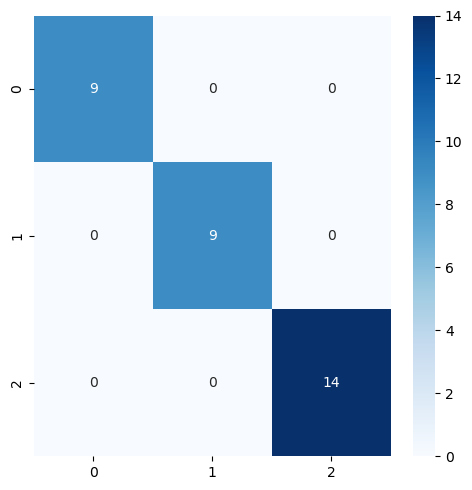

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        14

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.94
F1 Score: 0.9444


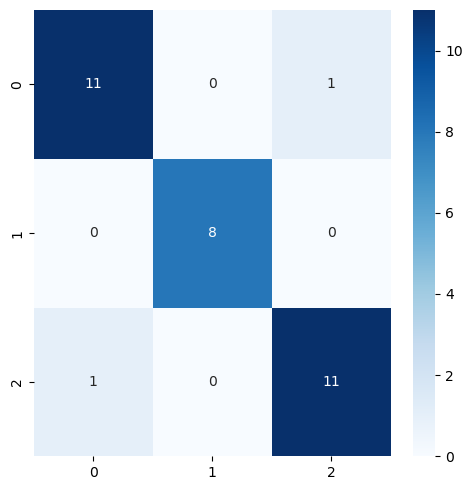

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.92      0.92      0.92        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.92      0.92      0.92        12

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0


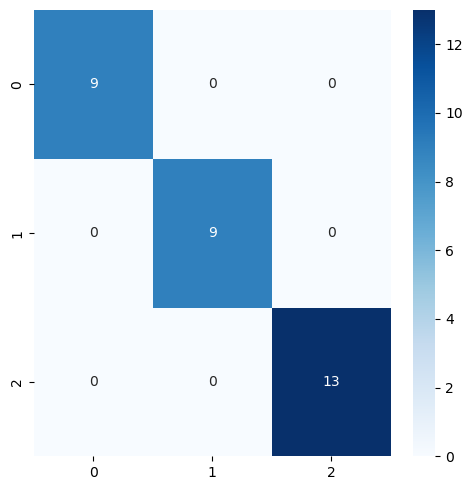

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        13

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0


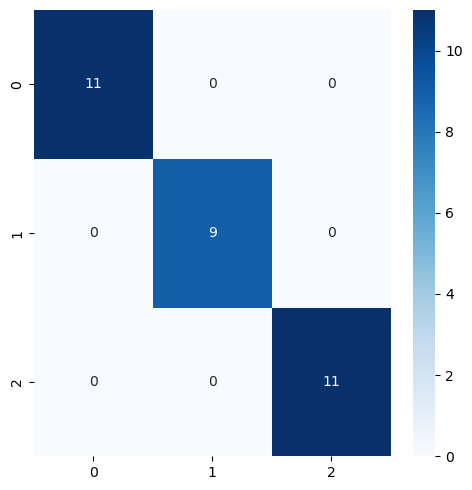

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        11
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        11

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31

____________________________________________________________

Cross-validation F1 Scores: [1.0, 0.9444, 1.0, 1.0]
Mean F1 Score: 0.9861

Cross-validation Accuracies: [1.0, 0.9375, 1.0, 1.0]
Mean Accuracy: 0.9844


In [45]:
model_name = 'RandomSearch Best Params SVM'
rand_svm = SVC(**random.best_params_, random_state=0)

# Initialize scaler and cross-validator
scaler = StandardScaler()
cv = sk(n_splits=4, shuffle=True, random_state=0)

# Accuracy list
accuracy_l_rand = []
f1_l_rand = []

# Result list
result_matrix = []

for tr_i, te_i in cv.split(X, y):
    X_train = X.iloc[tr_i]
    X_test = X.iloc[te_i]
    X_tr = scaler.fit_transform(X_train)
    X_v = scaler.transform(X_test)
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    
    # Fit SVM model with polynomial kernel and predict y_p
    rand_svm.fit(X_tr, y_tr)
    y_p = rand_svm.predict(X_v)
    
    # Calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(2))
    accuracy_l_rand.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_rand.append(f1)
    
    # Use confusion matrix to compare y_v and y_p, plot, and save it
    fig, ax = plt.subplots(figsize=(5,5))
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues')
    plt.tight_layout()
    plt.savefig(os.path.join(tuned_svm_save_path, 'tuned_rand_' + str(len(accuracy_l_rand)) + '_confusion_matrix.png'))
    plt.show()
    
    # Generate classification report
    print('____________________________________________________________')
    print("SVM classification_report:\n", classification_report(y_v, y_p))

# Summary of cross-validation
mean_accuracy = round(np.mean(accuracy_l_rand), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_rand), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_rand])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_rand])
print("Mean Accuracy:", mean_accuracy)

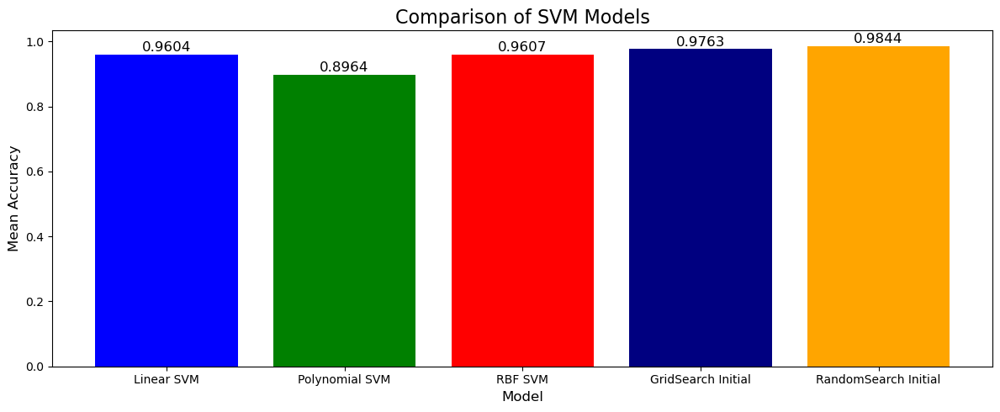

In [46]:
# Check if accuracy lists are empty or contain NaN values, and handle them
accuracies = [
    np.mean(accuracy_l) if accuracy_l else 0.0,
    np.mean(accuracy_l_poly) if accuracy_l_poly else 0.0,
    np.mean(accuracy_l_rbf) if accuracy_l_rbf else 0.0,
    np.mean(accuracy_l_grid) if accuracy_l_grid else 0.0,
    np.mean(accuracy_l_rand) if accuracy_l_rand else 0.0
]

# Ensure accuracies are finite values (replace NaN or Inf with 0)
accuracies = [acc if np.isfinite(acc) else 0.0 for acc in accuracies]

# Define the model names
model_names = ['Linear SVM', 'Polynomial SVM', 'RBF SVM', 'GridSearch Initial', 'RandomSearch Initial']

# Create the bar plot
plt.figure(figsize=(12, 5))
bars = plt.bar(model_names, accuracies, color=['blue', 'green', 'red', 'navy', 'orange'])

# Add title and labels
plt.title('Comparison of SVM Models', fontsize=16)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Mean Accuracy', fontsize=12)

# Display accuracy values on top of the bars
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

### FEATURE SELECTION

- feature selection are done with models built with best params from the Grid & Random searches

In [49]:
# Step 1: Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # Scale features

# Step 2: Initialize cross-validation with Stratified K-Folds
cv = sk(n_splits=4, shuffle=True, random_state=0)

# Step 3: List to store cross-validation accuracy for each value of k
cv_accuracies_grid = []
cv_accuracies_rand = []

# Define the tuned models from GridSearch and RandomSearch
# These models are assumed to have been tuned already through GridSearch and RandomSearch
grid_svm_model = SVC(**grid.best_params_, random_state=0)  # Polynomial SVM from GridSearch
rand_svm_model = SVC(**random.best_params_, random_state=0)  # RBF SVM from RandomSearch

# Step 4: Iterate over different values of k (number of features to select)
for k in range(1, X_scaled.shape[1] + 1):
    # Select the top k features using SelectKBest with ANOVA F-statistic
    selector = SelectKBest(score_func=f_classif, k=k)
    X_selected = selector.fit_transform(X_scaled, y)  # Apply the feature selection
    
    # Step 5: Perform cross-validation and calculate accuracy for GridSearch
    grid_cv_score = cross_val_score(grid_svm_model, X_selected, y, cv=cv, scoring='accuracy')
    cv_accuracies_grid.append(np.mean(grid_cv_score))  # Store the mean accuracy for GridSearch
    
    # Step 6: Perform cross-validation and calculate accuracy for RandomSearch
    rand_cv_score = cross_val_score(rand_svm_model, X_selected, y, cv=cv, scoring='accuracy')
    cv_accuracies_rand.append(np.mean(rand_cv_score))  # Store the mean accuracy for RandomSearch

    # Print the cross-validation accuracy for the current number of features (k)
    print(f"Number of features: {k}")
    print(f"GridSearch Tuned Accuracy: {np.mean(grid_cv_score).round(4)}")
    print(f"RandomSearch Tuned Accuracy: {np.mean(rand_cv_score).round(4)}\n")

Number of features: 1
GridSearch Tuned Accuracy: 0.7298
RandomSearch Tuned Accuracy: 0.6588

Number of features: 2
GridSearch Tuned Accuracy: 0.9128
RandomSearch Tuned Accuracy: 0.9209

Number of features: 3
GridSearch Tuned Accuracy: 0.9211
RandomSearch Tuned Accuracy: 0.9446

Number of features: 4
GridSearch Tuned Accuracy: 0.9763
RandomSearch Tuned Accuracy: 0.9685

Number of features: 5
GridSearch Tuned Accuracy: 0.9763
RandomSearch Tuned Accuracy: 0.9763

Number of features: 6
GridSearch Tuned Accuracy: 0.9763
RandomSearch Tuned Accuracy: 0.9685

Number of features: 7
GridSearch Tuned Accuracy: 0.9763
RandomSearch Tuned Accuracy: 0.9685

Number of features: 8
GridSearch Tuned Accuracy: 0.9841
RandomSearch Tuned Accuracy: 0.9844

Number of features: 9
GridSearch Tuned Accuracy: 0.9763
RandomSearch Tuned Accuracy: 0.9844

Number of features: 10
GridSearch Tuned Accuracy: 0.9763
RandomSearch Tuned Accuracy: 0.9688

Number of features: 11
GridSearch Tuned Accuracy: 0.9763
RandomSearch

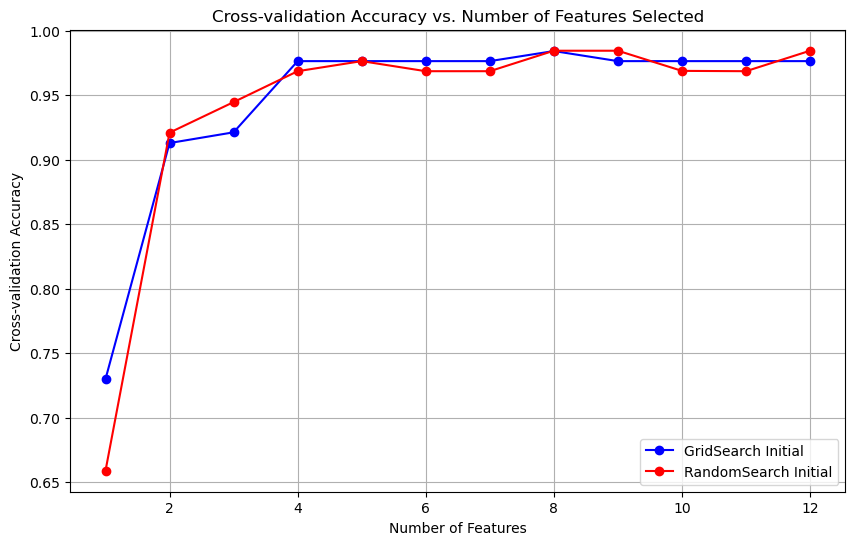


--- GRIDSEARCH MODEL SELECTED FEATURES ---
Best number of features for Polynomial SVM (GridSearch Tuned): 8
Cross-validation accuracy for Polynomial SVM (GridSearch Tuned) at 8 features: 0.9841

Selected feature names for Gridsearch SVM: Index(['Cylinder heating zone 1', 'Cylinder heating zone 4',
       'Maximum injection pressure', 'Injection time', 'Dosage time',
       'Cylinder heating zone 3', 'Switch-over volume', 'Material cushion'],
      dtype='object') 


--- RANDOMSEARCH MODEL SELECTED FEATURES ---
Best number of features for RBF SVM (RandomSearch Tuned): 8
Cross-validation accuracy for RBF SVM (RandomSearch Tuned) at 8 features: 0.9844

Selected feature names for RandomSearch SVM: Index(['Cylinder heating zone 1', 'Cylinder heating zone 4',
       'Maximum injection pressure', 'Injection time', 'Dosage time',
       'Cylinder heating zone 3', 'Switch-over volume', 'Material cushion'],
      dtype='object')


In [50]:
# Step 7: Plot the accuracy vs. number of features selected for both models
plt.figure(figsize=(10, 6))
plt.plot(range(1, X_scaled.shape[1] + 1), cv_accuracies_grid, marker='o', linestyle='-', label='GridSearch Initial', color='b')
plt.plot(range(1, X_scaled.shape[1] + 1), cv_accuracies_rand, marker='o', linestyle='-', label='RandomSearch Initial', color='r')
plt.title('Cross-validation Accuracy vs. Number of Features Selected')
plt.xlabel('Number of Features')
plt.ylabel('Cross-validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Step 8: Determine the best number of features (the k with the highest accuracy) for each model
best_k_grid = np.argmax(cv_accuracies_grid) + 1  # +1 to convert from 0-indexing to number of features
best_k_rand = np.argmax(cv_accuracies_rand) + 1  # +1 to convert from 0-indexing to number of features

# Step 10: Apply SelectKBest with the best k to get the selected features for both models
best_selector_grid = SelectKBest(score_func=f_classif, k=best_k_grid)
best_selector_grid.fit(X_scaled, y)
selected_features_grid = best_selector_grid.get_support(indices=True)

best_selector_rand = SelectKBest(score_func=f_classif, k=best_k_rand)
best_selector_rand.fit(X_scaled, y)
selected_features_rand = best_selector_rand.get_support(indices=True)

# Step 11: Print selected feature names for both models
print("\n--- GRIDSEARCH MODEL SELECTED FEATURES ---")
print(f"Best number of features for Polynomial SVM (GridSearch Tuned): {best_k_grid}")
print(f"Cross-validation accuracy for Polynomial SVM (GridSearch Tuned) at {best_k_grid} features: {cv_accuracies_grid[best_k_grid - 1]:.4f}")
selected_feature_names_grid = X.columns[selected_features_grid]  # Get feature names for GridSearch
print("\nSelected feature names for Gridsearch SVM:", selected_feature_names_grid, '\n\n')

print("--- RANDOMSEARCH MODEL SELECTED FEATURES ---")
print(f"Best number of features for RBF SVM (RandomSearch Tuned): {best_k_rand}")
print(f"Cross-validation accuracy for RBF SVM (RandomSearch Tuned) at {best_k_rand} features: {cv_accuracies_rand[best_k_rand - 1]:.4f}")
selected_feature_names_rand = X.columns[selected_features_rand]  # Get feature names for RandomSearch
print("\nSelected feature names for RandomSearch SVM:", selected_feature_names_rand)

#### GRID SEARCH

In [52]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from scipy.stats import uniform, randint
import matplotlib.pyplot as plt

# Step 1: Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # Scale features

# Step 2: Initialize cross-validation with Stratified K-Folds
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

# Step 3: Perform feature selection to get the reduced features
k = 8  # Replace with the best number of features determined earlier
selector = SelectKBest(score_func=f_classif, k=k)
X_reduced = selector.fit_transform(X_scaled, y)

# Step 4: Define hyperparameter grids for GridSearchCV and RandomizedSearchCV
#HyperParameter Tuning (SVM)
grid_param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [1, 2, 3, 4],
    'gamma': ['scale', 'auto', 0.001, 0.1],  # Kernel coefficient for ‘rbf’, ‘poly’ and ‘sigmoid’.
    'coef0': [0.0, 0.1, 0.2, 0.3, 0.5, 1.0] # Independent term in kernel function. It is only significant in ‘poly’ and ‘sigmoid’.
}

# Step 5: GridSearchCV on Polynomial SVM
grid_svm = SVC()
grid_search = GridSearchCV(estimator=grid_svm, param_grid=grid_param_grid, cv=cv, 
                           scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_reduced, y)

# Step 7: Evaluate the results
print("\nBest parameters for GridSearch_Initial:")
print(grid_search.best_params_)
print(f"Best cross-validation score: {grid_search.best_score_:.4f}\n")

# Step 8: Cross-validate the tuned models
grid_tuned_model = grid_search.best_estimator_

grid_cv_score = cross_val_score(grid_tuned_model, X_reduced, y, cv=cv, scoring='accuracy')

Fitting 4 folds for each of 1152 candidates, totalling 4608 fits

Best parameters for GridSearch_Initial:
{'C': 0.1, 'coef0': 1.0, 'degree': 4, 'gamma': 'scale', 'kernel': 'poly'}
Best cross-validation score: 0.9922



#### RANDOM SEARCH

In [54]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from scipy.stats import uniform, randint
import matplotlib.pyplot as plt

# Step 1: Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # Scale features

# Step 2: Initialize cross-validation with Stratified K-Folds
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

# Step 3: Perform feature selection to get the reduced features
k = 8  # Replace with the best number of features determined earlier
selector = SelectKBest(score_func=f_classif, k=k)
X_reduced = selector.fit_transform(X_scaled, y)

# for randomsearch
rand_param_grid = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'poly', 'rbf'],
    'degree': [2, 3, 4],
    'gamma': uniform(0.001, 1),  # Discrete values for gamma
    'coef0': uniform(0, 1)                # Discrete values for coef0 (for poly and rbf kernels)
}

# Step 6: RandomizedSearchCV on RBF SVM
rand_svm = SVC()
random_search = RandomizedSearchCV(estimator=rand_svm, param_distributions=rand_param_grid,
                                   n_iter=100, cv=cv, scoring='accuracy', n_jobs=-1,
                                   verbose=1, random_state=0)
random_search.fit(X_reduced, y)

print("\nBest parameters for RandomSearch_Initial:")
rounded_random_best_params = {k: round(v, 2) if isinstance(v, (float, int)) else v for k, v in random_best_params.items()}
print("\nRandom Search Best Parameters:", rounded_random_best_params)
print(f"Best cross-validation score: {random_search.best_score_:.4f}\n")

rand_tuned_model = random_search.best_estimator_

rand_cv_score = cross_val_score(rand_tuned_model, X_reduced, y, cv=cv, scoring='accuracy')

Fitting 4 folds for each of 100 candidates, totalling 400 fits

Best parameters for RandomSearch_Initial:

Random Search Best Parameters: {'C': 14.58, 'coef0': 0.49, 'degree': 2, 'gamma': 0.03, 'kernel': 'poly'}
Best cross-validation score: 0.9922



### BUILD REDUCED FEATURES TUNED MODELS

#### GRID SEARCH

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.9688
F1 Score: 0.9708


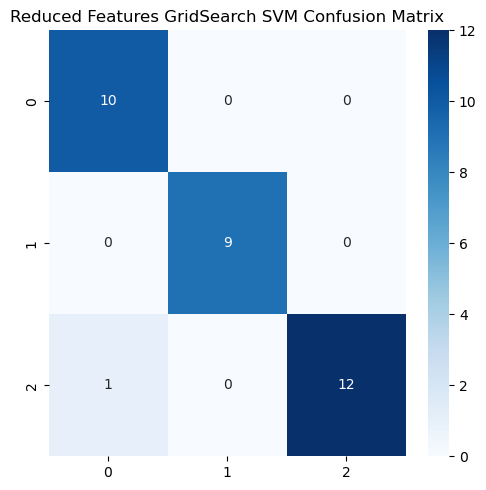

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       0.91      1.00      0.95        10
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.92      0.96        13

    accuracy                           0.97        32
   macro avg       0.97      0.97      0.97        32
weighted avg       0.97      0.97      0.97        32

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.9688
F1 Score: 0.9701


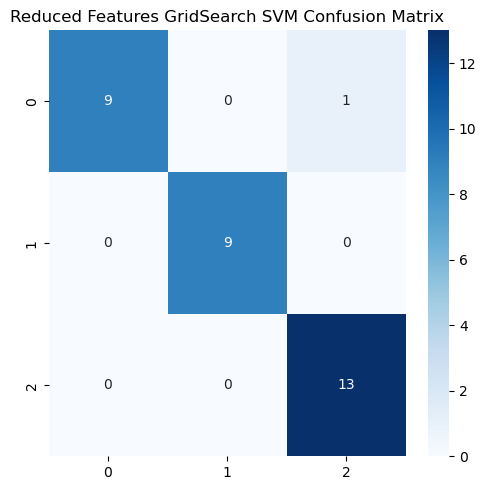

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      0.90      0.95        10
  Condition7       1.00      1.00      1.00         9
     Normal1       0.93      1.00      0.96        13

    accuracy                           0.97        32
   macro avg       0.98      0.97      0.97        32
weighted avg       0.97      0.97      0.97        32

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0


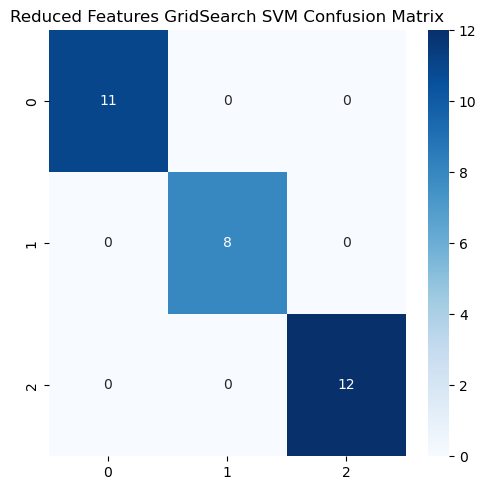

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        11
  Condition7       1.00      1.00      1.00         8
     Normal1       1.00      1.00      1.00        12

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0


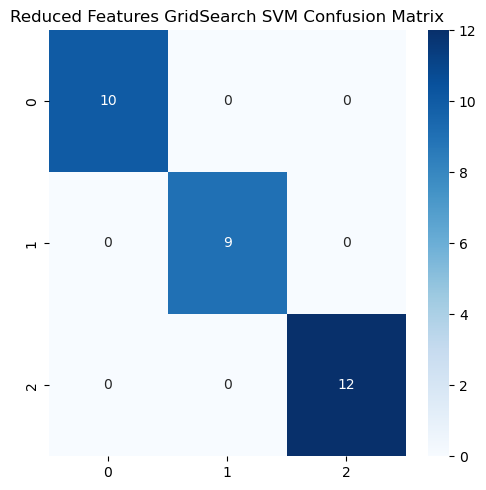

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        10
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        12

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31

____________________________________________________________

Cross-validation F1 Scores: [0.9708, 0.9701, 1.0, 1.0]
Mean F1 Score: 0.9852

Cross-validation Accuracies: [0.9688, 0.9688, 1.0, 1.0]
Mean Accuracy: 0.9844


In [57]:
# Use the selected features from the best SelectKBest for GridSearch
X_reduced = X.iloc[:, selected_features_grid]  # Replace with selected features for GridSearch

# Define model name and path for saving plots
model_name = 'Reduced Features GridSearch SVM'
tuned_svm_save_path = './'  # Ensure the directory exists or update the path

# Define SVC model with best hyperparameters from GridSearch
reduced_grid_svm = SVC(**grid.best_params_, random_state=0)

# Initialize scaler and cross-validator
scaler = StandardScaler()
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

# Accuracy and F1 score lists
accuracy_l_redc_grid = []
f1_l_redc_grid = []

for tr_i, te_i in cv.split(X_reduced, y):  # Use X_reduced with selected features
    # Split and scale data
    X_train = X_reduced.iloc[tr_i]
    X_test = X_reduced.iloc[te_i]
    X_tr = scaler.fit_transform(X_train)
    X_v = scaler.transform(X_test)
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    
    # Fit SVM model and predict
    reduced_grid_svm.fit(X_tr, y_tr)
    y_p = reduced_grid_svm.predict(X_v)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_v, y_p)  # Use sklearn's accuracy_score
    print("Accuracy:", round(accuracy, 4))
    accuracy_l_redc_grid.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_redc_grid.append(f1)
    
    # Use confusion matrix to compare y_v and y_p, plot, and save it
    fig, ax = plt.subplots(figsize=(5, 5))
    sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues', ax=ax)
    plt.title(f'{model_name} Confusion Matrix')
    plt.tight_layout()
    plt.savefig(os.path.join(tuned_svm_save_path, f'redc_grid_{len(accuracy_l_redc_grid)}_confusion_matrix.png'))
    plt.show()
    
    # Generate classification report
    print('____________________________________________________________')
    print("SVM classification_report:\n", classification_report(y_v, y_p))

# Summary of cross-validation
mean_accuracy = round(np.mean(accuracy_l_redc_grid), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_redc_grid), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_redc_grid])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_redc_grid])
print("Mean Accuracy:", mean_accuracy)


#### RANDOM SEARCH

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 1.0
F1 Score: 1.0


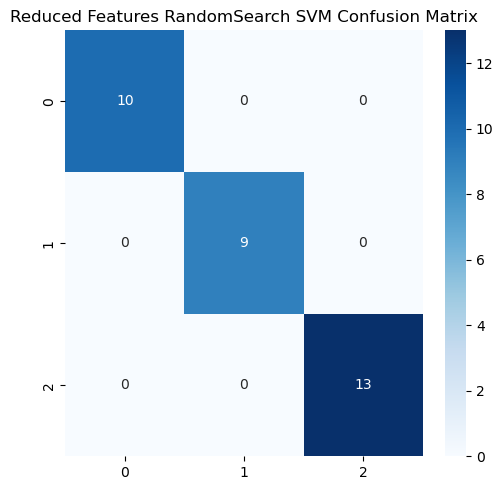

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        10
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        13

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32

____________________________________________________________
Training data length: 94
Verification data length: 32
Accuracy: 0.9375
F1 Score: 0.9392


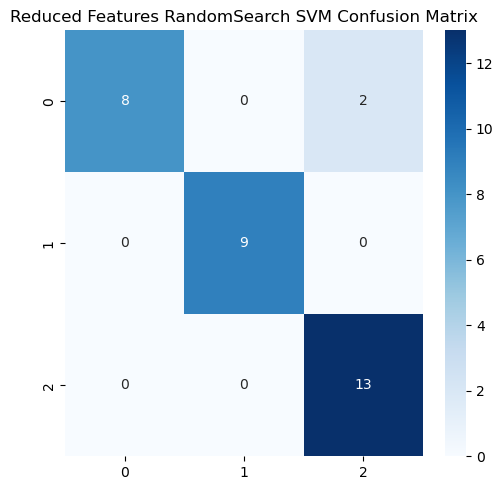

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      0.80      0.89        10
  Condition7       1.00      1.00      1.00         9
     Normal1       0.87      1.00      0.93        13

    accuracy                           0.94        32
   macro avg       0.96      0.93      0.94        32
weighted avg       0.95      0.94      0.94        32

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0


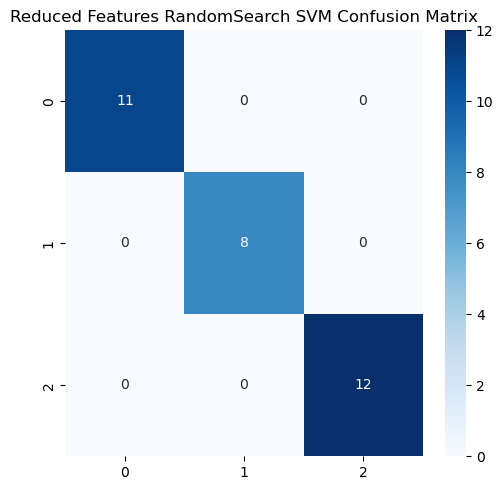

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        11
  Condition7       1.00      1.00      1.00         8
     Normal1       1.00      1.00      1.00        12

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31

____________________________________________________________
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0


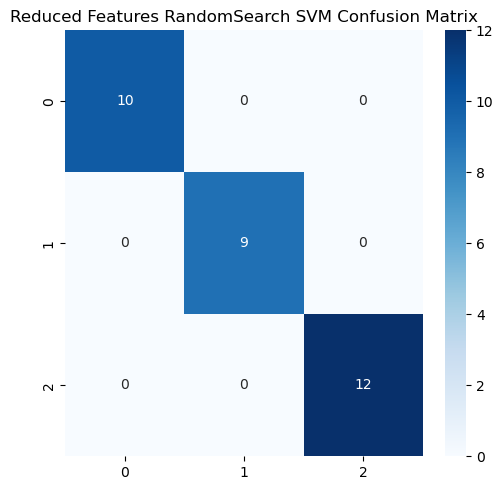

____________________________________________________________
SVM classification_report:
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        10
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        12

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31

____________________________________________________________

Cross-validation F1 Scores: [1.0, 0.9392, 1.0, 1.0]
Mean F1 Score: 0.9848

Cross-validation Accuracies: [1.0, 0.9375, 1.0, 1.0]
Mean Accuracy: 0.9844


In [59]:
# Use the selected features from the best SelectKBest for RandomSearch
X_reduced_rand = X.iloc[:, selected_features_rand]  # Replace with selected features for RandomSearch

# Define model name and path for saving plots
model_name = 'Reduced Features RandomSearch SVM'
tuned_svm_save_path = './'  # Ensure the directory exists or update the path

# Define SVC model with best hyperparameters from RandomSearch
reduced_rand_svm = SVC(**random_best_params, random_state=0)

# Initialize scaler and cross-validator
scaler = StandardScaler()
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

# Accuracy and F1 score lists
accuracy_l_redc_rand = []
f1_l_redc_rand = []

for tr_i, te_i in cv.split(X_reduced_rand, y):  # Use X_reduced_rand with selected features
    # Split and scale data
    X_train = X_reduced_rand.iloc[tr_i]
    X_test = X_reduced_rand.iloc[te_i]
    X_tr = scaler.fit_transform(X_train)
    X_v = scaler.transform(X_test)
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    
    # Fit SVM model and predict
    reduced_rand_svm.fit(X_tr, y_tr)
    y_p = reduced_rand_svm.predict(X_v)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_v, y_p)  # Use sklearn's accuracy_score
    print("Accuracy:", round(accuracy, 4))
    accuracy_l_redc_rand.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_redc_rand.append(f1)
    
    # Use confusion matrix to compare y_v and y_p, plot, and save it
    fig, ax = plt.subplots(figsize=(5, 5))
    sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues', ax=ax)
    plt.title(f'{model_name} Confusion Matrix')
    plt.tight_layout()
    plt.savefig(os.path.join(tuned_svm_save_path, f'redc_rand_{len(accuracy_l_redc_rand)}_confusion_matrix.png'))
    plt.show()
    
    # Generate classification report
    print('____________________________________________________________')
    print("SVM classification_report:\n", classification_report(y_v, y_p))

# Summary of cross-validation
mean_accuracy = round(np.mean(accuracy_l_redc_rand), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_redc_rand), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_redc_rand])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_redc_rand])
print("Mean Accuracy:", mean_accuracy)


### SVM COMPARISON

#### MODEL ACCURACIES

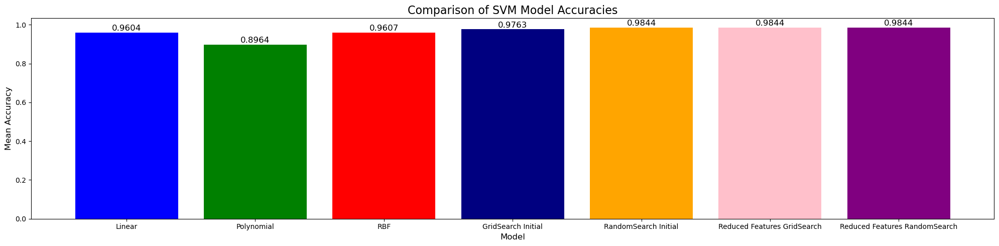

In [62]:
# Check if accuracy lists are empty or contain NaN values, and handle them
accuracies = [
    np.mean(accuracy_l) if accuracy_l else 0.0,
    np.mean(accuracy_l_poly) if accuracy_l_poly else 0.0,
    np.mean(accuracy_l_rbf) if accuracy_l_rbf else 0.0,
    np.mean(accuracy_l_grid) if accuracy_l_grid else 0.0,
    np.mean(accuracy_l_rand) if accuracy_l_rand else 0.0,
    np.mean(accuracy_l_redc_grid) if accuracy_l_redc_grid else 0.0,
    np.mean(accuracy_l_redc_rand) if accuracy_l_redc_rand else 0.0
]

# Ensure accuracies are finite values (replace NaN or Inf with 0)
accuracies = [acc if np.isfinite(acc) else 0.0 for acc in accuracies]

# Define the model names
model_names = ['Linear', 'Polynomial', 'RBF', 'GridSearch Initial', 'RandomSearch Initial',
               'Reduced Features GridSearch', 'Reduced Features RandomSearch']

# Create the bar plot
plt.figure(figsize=(20, 5))
bars = plt.bar(model_names, accuracies, color=['blue', 'green', 'red', 'navy', 'orange', 'pink', 'purple'])

# Add title and labels
plt.title('Comparison of SVM Model Accuracies', fontsize=16)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Mean Accuracy', fontsize=12)

# Display accuracy values on top of the bars
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

#### MODEL F1-SCORES

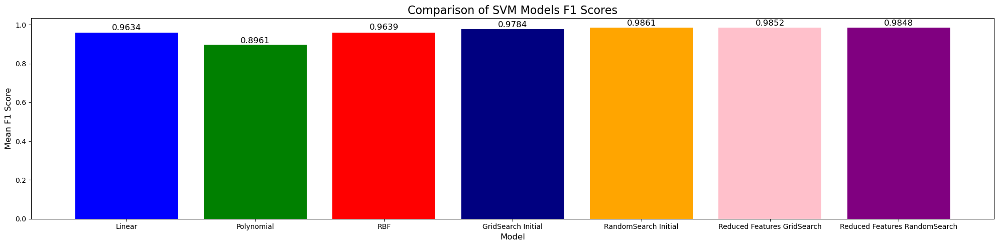

In [64]:
import matplotlib.pyplot as plt
import numpy as np

# Check if accuracy lists are empty or contain NaN values, and handle them
f1 = [
    np.mean(f1_l) if f1_l else 0.0,
    np.mean(f1_l_poly) if f1_l_poly else 0.0,
    np.mean(f1_l_rbf) if f1_l_rbf else 0.0,
    np.mean(f1_l_grid) if f1_l_grid else 0.0,
    np.mean(f1_l_rand) if f1_l_rand else 0.0,
    np.mean(f1_l_redc_grid) if f1_l_redc_grid else 0.0,
    np.mean(f1_l_redc_rand) if f1_l_redc_rand else 0.0
]

# Ensure accuracies are finite values (replace NaN or Inf with 0)
f1 = [score if np.isfinite(score) else 0.0 for score in f1]

# Define the model names
model_names = ['Linear', 'Polynomial', 'RBF', 'GridSearch Initial', 'RandomSearch Initial',
               'Reduced Features GridSearch', 'Reduced Features RandomSearch']

# Create the bar plot
plt.figure(figsize=(20, 5))
bars = plt.bar(model_names, accuracies, color=['blue', 'green', 'red', 'navy', 'orange', 'pink', 'purple'])

# Add title and labels
plt.title('Comparison of SVM Models F1 Scores', fontsize=16)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Mean F1 Score', fontsize=12)

# Display accuracy values on top of the bars
for i, v in enumerate(f1):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

## RANDOM FORESTS (RF)

In [74]:
# Import required libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import export_graphviz
import seaborn as sns
import os
from PIL import Image
from subprocess import call

X = df.drop("Condition", axis=1)
y = df["Condition"]

# Define feature and target names
feature_names = X.columns
target_names = y.unique().astype(str)

____________________________________________________________

Iteration: 1
Training data length: 94
Verification data length: 32
Accuracy: 0.97
F1 Score: 0.9701


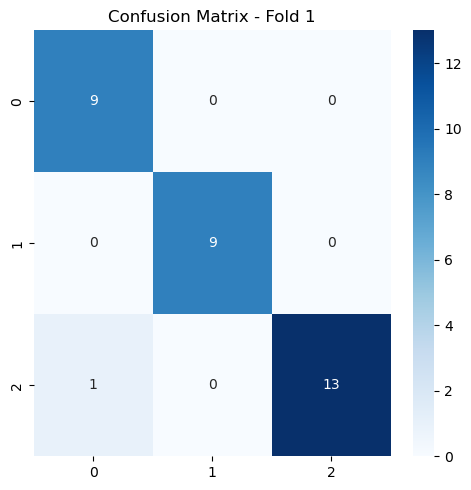

____________________________________________________________

Iteration: 2
Training data length: 94
Verification data length: 32
Accuracy: 0.94
F1 Score: 0.9444


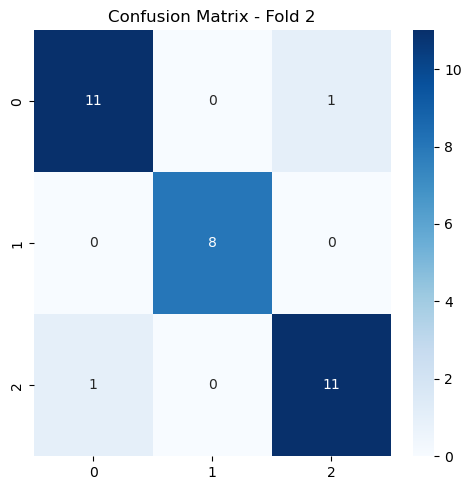

____________________________________________________________

Iteration: 3
Training data length: 95
Verification data length: 31
Accuracy: 1.00
F1 Score: 1.0000


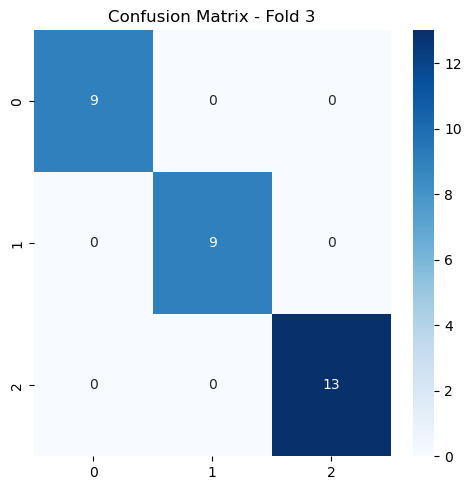

____________________________________________________________

Iteration: 4
Training data length: 95
Verification data length: 31
Accuracy: 1.00
F1 Score: 1.0000


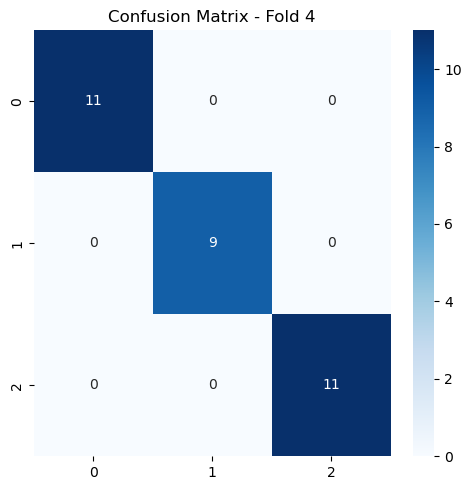

____________________________________________________________

Cross-validation F1 Scores: [0.9701, 0.9444, 1.0, 1.0]
Mean F1 Score: 0.9786

Cross-validation Accuracies: [0.9688, 0.9375, 1.0, 1.0]
Mean Accuracy: 0.9766


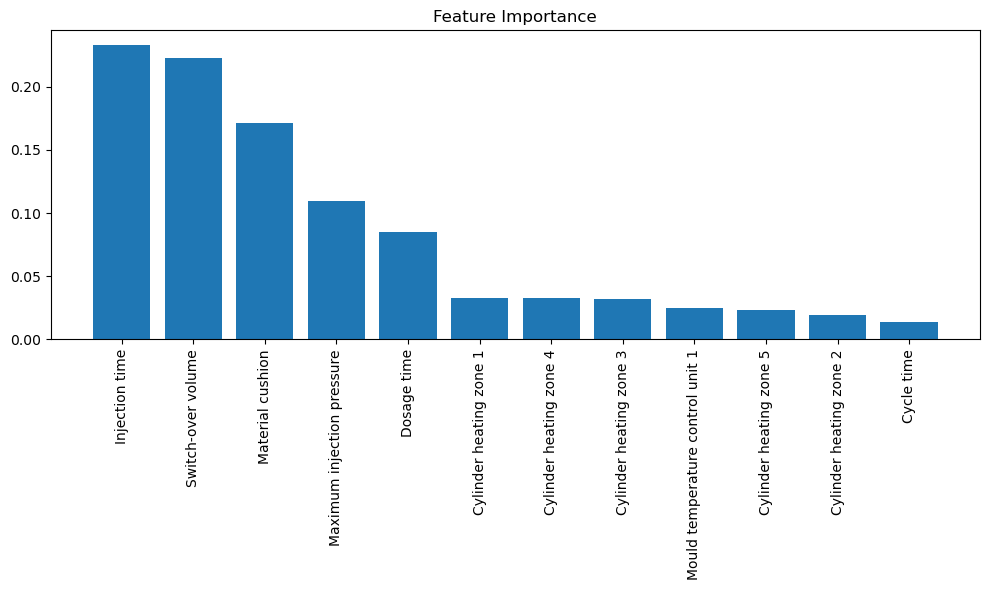

In [90]:
# Import required libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.tree import export_graphviz
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from PIL import Image
from subprocess import call

# Initialize Random Forest Classifier
model2 = RandomForestClassifier(random_state=0)

# Define K-Fold cross-validator
cv = KFold(n_splits=4, shuffle=True, random_state=0)

# Accuracy and F1 score lists
accuracy_l = []
f1_l = []

# Loop through folds
for i, (tr_i, te_i) in enumerate(cv.split(X, y), 1):
    X_tr, X_v = X.iloc[tr_i], X.iloc[te_i]
    y_tr, y_v = y.iloc[tr_i], y.iloc[te_i]

    print('____________________________________________________________')
    print(f"\nIteration: {i}")
    print(f"Training data length: {len(y_tr)}")
    print(f"Verification data length: {len(y_v)}")

    # Fit the model
    model2.fit(X_tr, y_tr)
    y_p = model2.predict(X_v)

    # Calculate accuracy
    accuracy = accuracy_score(y_v, y_p)
    accuracy_l.append(accuracy)
    print(f"Accuracy: {accuracy:.2f}")

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')
    f1_l.append(f1)
    print(f"F1 Score: {f1:.4f}")

    # Plot and save confusion matrix
    conf_matrix = confusion_matrix(y_v, y_p)
    plt.figure(figsize=(5, 5))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - Fold {i}")
    plt.tight_layout()
    conf_matrix_path = os.path.join(random_forest_save_path, f'randomforest_{i}_confusion_matrix.png')
    plt.savefig(conf_matrix_path)
    plt.show()

# Calculate mean scores
mean_accuracy = round(np.mean(accuracy_l), 4)
mean_f1 = round(np.mean(f1_l), 4)

# Print cross-validation summary
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l])
print("Mean Accuracy:", mean_accuracy)

# Feature importance visualization
importances = model2.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns

plt.figure(figsize=(10, 6))
plt.title("Feature Importance")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), features[indices], rotation=90)
plt.tight_layout()
plt.show()

In [91]:
# Example observation with 12 features (replace with actual values)
observation = [[12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1]]

# Predict the observation's class
y_pred = model2.predict(observation)
print("Prediction class:", y_pred[0])

Prediction class: Normal1


#### FEATURE IMPORTANCE

Feature names: ['Injection time', 'Switch-over volume', 'Material cushion', 'Maximum injection pressure', 'Dosage time', 'Cylinder heating zone 1', 'Cylinder heating zone 4', 'Cylinder heating zone 3', 'Mould temperature control unit 1', 'Cylinder heating zone 5', 'Cylinder heating zone 2', 'Cycle time']

Feature importance: [0.2331, 0.2228, 0.1716, 0.1094, 0.0848, 0.0328, 0.0325, 0.0317, 0.0252, 0.0232, 0.0195, 0.0133]


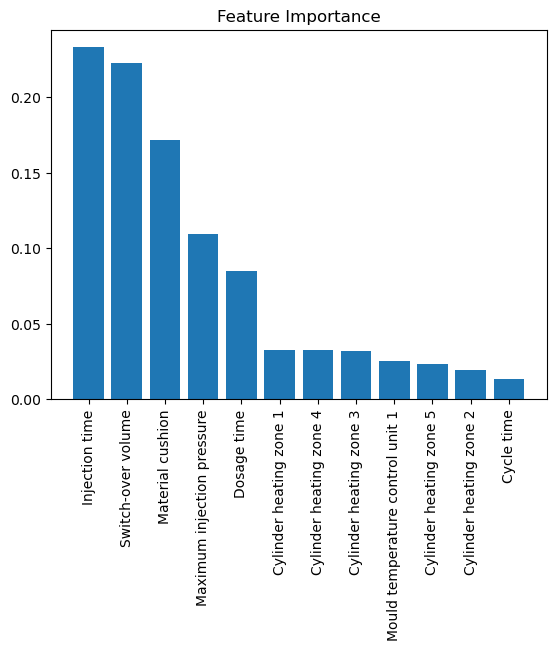


Chosen features: ['Injection time', 'Switch-over volume', 'Material cushion', 'Maximum injection pressure']


In [93]:
#RF identifying Important Features
importances = model2.feature_importances_

# Sort feature importances in descending order
indices = np.argsort(importances)[::-1]
importances_rounded = [round(val, 4) for val in importances[indices]]

# Rearrange feature names so they match the sorted feature importances
names = [X.columns[i] for i in indices]
print("Feature names:", names)
print("\nFeature importance:", importances_rounded)

#Create plot
plt.figure()

# Create plot title
plt.title("Feature Importance")

# Add bars
plt.bar(range(X.shape[1]), importances[indices])

# Add feature names as x-axis labels
plt.xticks(range(X.shape[1]), names, rotation=90)

# Show plot
plt.show()

# Extract the top 2 features
chosen_indices = indices[:4]  # Get the indices of the top 2 features
chosen_names = [X.columns[i] for i in chosen_indices]  # Get their names
chosen_data = X.iloc[:, chosen_indices]  # Extract the data for the top 2 features

print(f"\nChosen features: {chosen_names}")

### HYPERPARAMETER TUNING

#### GRID SEARCH

In [96]:
# Define the parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],        # Number of trees in the forest
    'max_depth': [None, 10, 20, 30],      # Maximum depth of each tree
    'min_samples_split': [2, 5, 10],      # Minimum number of samples to split an internal node
    'min_samples_leaf': [1, 2, 4],        # Minimum number of samples required to be a leaf node
    'criterion': ['gini', 'entropy'],     # Criterion for splitting
    'max_features': ['sqrt', 'log2', None], # Number of features to consider at each split
    "bootstrap": [True, False]
}

# Initialize the Random Forest Classifier
model2 = RandomForestClassifier(random_state=0)

# Convert y_train to a 1D numpy array
# y_train = y_train.values.ravel()

# Initialize GridSearchCV with 4-fold cross-validation
grid_search = GridSearchCV(
    estimator=model2,
    param_grid=param_grid,
    cv=4,  # 4-fold cross-validation
    scoring='accuracy',  # Scoring metric
    n_jobs=-1,           # Use all available cores
    verbose=1            # Verbose output for progress
)

# Measure runtime of the grid search process
start_time = time.time()  # Start time

# Perform Grid Search
grid_search.fit(X_train, y_train)

end_time = time.time()  # End time
runtime = end_time - start_time  # Total runtime in seconds

# Print the best parameters and the best cross-validation score
print("\nBest Parameters:", grid_search.best_params_)
print("\nBest Cross-Validation Accuracy:", round(grid_search.best_score_, 4))
print(f"Grid Search Runtime: {runtime:.2f} seconds")

Fitting 4 folds for each of 1296 candidates, totalling 5184 fits

Best Parameters: {'bootstrap': True, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}

Best Cross-Validation Accuracy: 0.9683
Grid Search Runtime: 114.60 seconds



Training with the best parameters...
____________________________________________________________

Iteration: 1
Training data length: 94
Verification data length: 32
Accuracy: 0.97
F1 Score: 0.9701
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_1.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_1.png


RF Prediction report 
               precision    recall  f1-score   support

  Condition4       0.90      1.00      0.95         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.93      0.96        14

    accuracy                           0.97        32
   macro avg       0.97      0.98      0.97        32
weighted avg       0.97      0.97      0.97        32



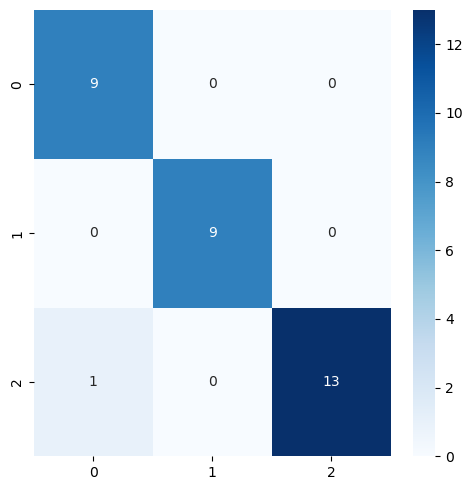

____________________________________________________________

Iteration: 2
Training data length: 94
Verification data length: 32
Accuracy: 0.91
F1 Score: 0.9165
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_2.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_2.png


RF Prediction report 
               precision    recall  f1-score   support

  Condition4       0.85      0.92      0.88        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.91      0.83      0.87        12

    accuracy                           0.91        32
   macro avg       0.92      0.92      0.92        32
weighted avg       0.91      0.91      0.91        32



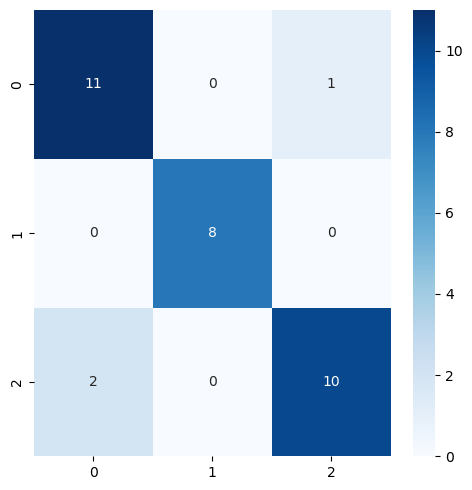

____________________________________________________________

Iteration: 3
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_3.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_3.png


RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        13

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



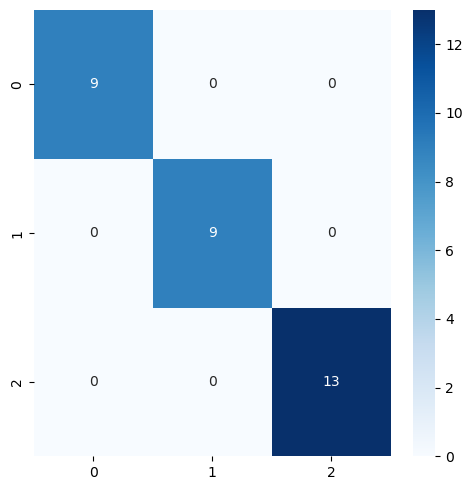

____________________________________________________________

Iteration: 4
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_4.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_4.png


RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        11
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        11

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



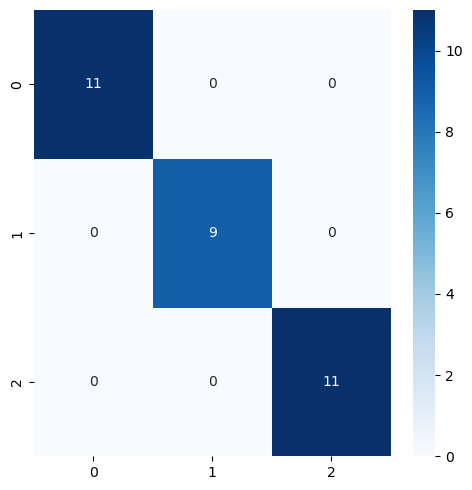

____________________________________________________________

Cross-validation F1 Scores: [0.9701, 0.9165, 1.0, 1.0]
Mean F1 Score: 0.9717

Cross-validation Accuracies: [0.9688, 0.9062, 1.0, 1.0]
Mean Accuracy: 0.9688


In [106]:
from IPython.display import Image, display
# Use the best parameters for final training and evaluation
print("\nTraining with the best parameters...")

best_rf_grid = RandomForestClassifier(**grid_search.best_params_, random_state=0)

# Perform cross-validation as in the original script
cv = KFold(n_splits=4, shuffle=True, random_state=0)

accuracy_l_grid = []
f1_l_grid = []

i = 1
for tr_i, te_i in cv.split(X, y):
    X_tr = X.iloc[tr_i]
    X_v = X.iloc[te_i]
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("\nIteration:", i)
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    i += 1

    # Fit Random Forest Classification to the Training set
    best_rf_grid.fit(X_tr, y_tr)
    y_p = best_rf_grid.predict(X_v)
    
    # Calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(2))
    accuracy_l_grid.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_grid.append(f1)

    # Extract single tree
    estimator = best_rf_grid.estimators_[5]
    dot_file_path = os.path.join(random_forest_save_path, f'tree_{i-1}.dot')
    png_file_path = os.path.join(random_forest_save_path, f'tree_{i-1}.png')
    
    # Export as dot file
    export_graphviz(estimator, out_file=dot_file_path, 
                    feature_names=feature_names,
                    class_names=target_names,
                    rounded=True, proportion=False, 
                    precision=2, filled=True)

    # Convert to png using system command (requires Graphviz)
    from subprocess import call
    # Check if dot file was created
    if os.path.exists(dot_file_path):
        print(f"DOT file created at: {dot_file_path}")

        # Convert to PNG using system command
        call(['dot', '-Tpng', dot_file_path, '-o', png_file_path, '-Gdpi=600'])

        # Check if PNG file was successfully created
        if os.path.exists(png_file_path):
            print(f"PNG file created at: {png_file_path}")
            display(Image(filename=png_file_path))
        else:
            print(f"Error: {png_file_path} was not created. Graphviz might not be running correctly.")
    else:
        print(f"Error: {dot_file_path} was not created. Check export_graphviz parameters and permissions.")

    # Classification report
    print("RF Prediction report", "\n", classification_report(y_v, y_p))
    
    # Plot and save confusion matrix
    fig, ax = plt.subplots(figsize=(5, 5))
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues', ax=ax)
    plt.tight_layout()
    plt.show()

# Mean accuracy & f1 score
mean_accuracy = round(np.mean(accuracy_l_grid), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_grid), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_grid])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_grid])
print("Mean Accuracy:", mean_accuracy)

#### RANDOM SEARCH

In [108]:
# Define the parameter distribution for RandomizedSearchCV
param_dist = {
    'n_estimators': randint(50, 201),        # Number of trees in the forest
    'max_depth': [None, 10, 20, 30],      # Maximum depth of each tree
    'min_samples_split': randint(2, 11),      # Minimum number of samples to split an internal node
    'min_samples_leaf': randint(1, 5),        # Minimum number of samples required to be a leaf node
    'criterion': ['gini', 'entropy'],     # Criterion for splitting
    'max_features': ['sqrt', 'log2', None], # Number of features to consider at each split
    "bootstrap": [True, False]
}

# Initialize the Random Forest Classifier
model2 = RandomForestClassifier(random_state=0)

# Initialize RandomizedSearchCV with 4-fold cross-validation
random_search = RandomizedSearchCV(
    estimator=model2,
    param_distributions=param_dist,
    n_iter=50,            # Number of random parameter combinations to try
    cv=cv,                 # 4-fold cross-validation
    scoring='accuracy',   # Scoring metric
    n_jobs=-1,            # Use all available cores
    random_state=0,       # Ensure reproducibility
    verbose=1             # Verbose output for progress
)

# Measure runtime of the random search process
start_time = time.time()  # Start time

# Perform Randomized Search
random_search.fit(X_train, y_train)

end_time = time.time()  # End time
runtime = end_time - start_time  # Total runtime in seconds

# Print the best parameters and the best cross-validation score
print("\nBest Parameters:", random_search.best_params_)
print("\nBest Cross-Validation Accuracy:", round(random_search.best_score_, 4))
print(f"Randomized Search Runtime: {runtime:.2f} seconds")

Fitting 4 folds for each of 50 candidates, totalling 200 fits

Best Parameters: {'bootstrap': True, 'criterion': 'entropy', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 153}

Best Cross-Validation Accuracy: 0.9583
Randomized Search Runtime: 4.53 seconds



Training with the best parameters...
____________________________________________________________

Iteration: 1
Training data length: 94
Verification data length: 32
Accuracy: 0.97
F1 Score: 0.9701
RF Prediction report 
               precision    recall  f1-score   support

  Condition4       0.90      1.00      0.95         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.93      0.96        14

    accuracy                           0.97        32
   macro avg       0.97      0.98      0.97        32
weighted avg       0.97      0.97      0.97        32



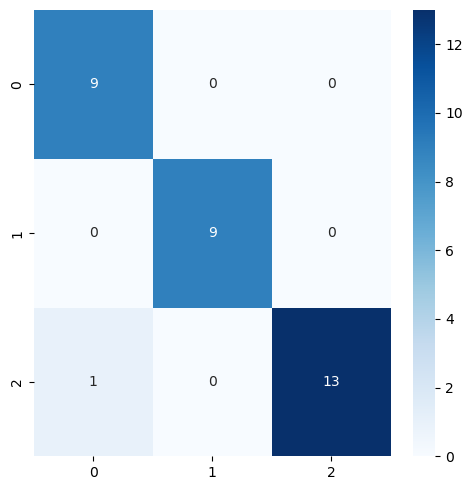

____________________________________________________________

Iteration: 2
Training data length: 94
Verification data length: 32
Accuracy: 0.91
F1 Score: 0.9165
RF Prediction report 
               precision    recall  f1-score   support

  Condition4       0.85      0.92      0.88        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.91      0.83      0.87        12

    accuracy                           0.91        32
   macro avg       0.92      0.92      0.92        32
weighted avg       0.91      0.91      0.91        32



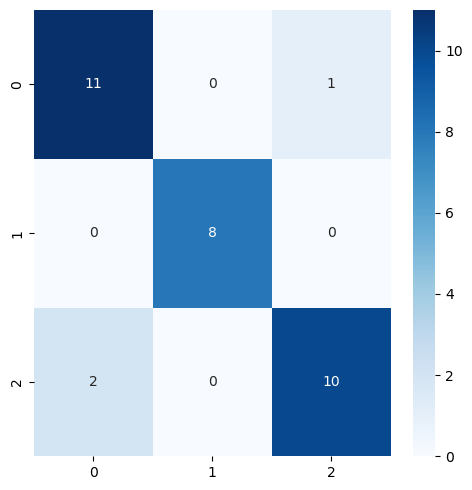

____________________________________________________________

Iteration: 3
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0
RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        13

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



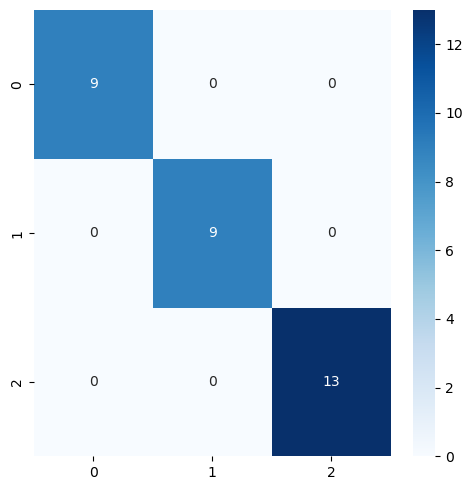

____________________________________________________________

Iteration: 4
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0
RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        11
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        11

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



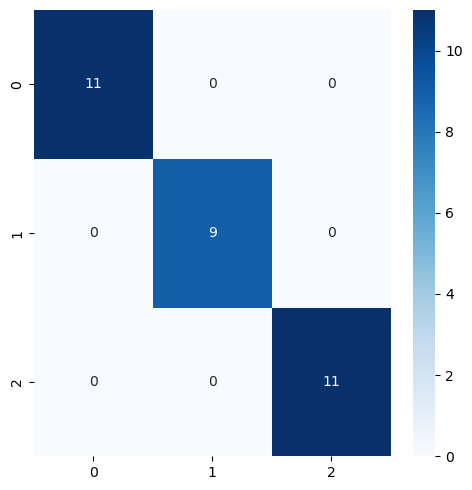

____________________________________________________________

Cross-validation F1 Scores: [0.9701, 0.9165, 1.0, 1.0]
Mean F1 Score: 0.9717

Cross-validation Accuracies: [0.9688, 0.9062, 1.0, 1.0]
Mean Accuracy: 0.9688


In [109]:
# Use the best parameters for final training and evaluation
print("\nTraining with the best parameters...")
best_rf_rand = RandomForestClassifier(**random_search.best_params_, random_state=0)

# Perform cross-validation as in the original script
cv = KFold(n_splits=4, shuffle=True, random_state=0)

accuracy_l_rand = []
f1_l_rand = []

i = 1
for tr_i, te_i in cv.split(X, y):
    X_tr = X.iloc[tr_i]
    X_v = X.iloc[te_i]
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("\nIteration:", i)
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    i += 1

    # Fit Random Forest Classification to the Training set
    best_rf_rand.fit(X_tr, y_tr)
    y_p = best_rf_rand.predict(X_v)
    
    # Calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(2))
    accuracy_l_rand.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_rand.append(f1)

    # Classification report
    print("RF Prediction report", "\n", classification_report(y_v, y_p))
    
    # Plot and save confusion matrix
    fig, ax = plt.subplots(figsize=(5, 5))
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues', ax=ax)
    plt.tight_layout()
    plt.show()

# Mean accuracy & f1 score
mean_accuracy = round(np.mean(accuracy_l_rand), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_rand), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_rand])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_rand])
print("Mean Accuracy:", mean_accuracy)

### REDUCED FEATURE SELECTION

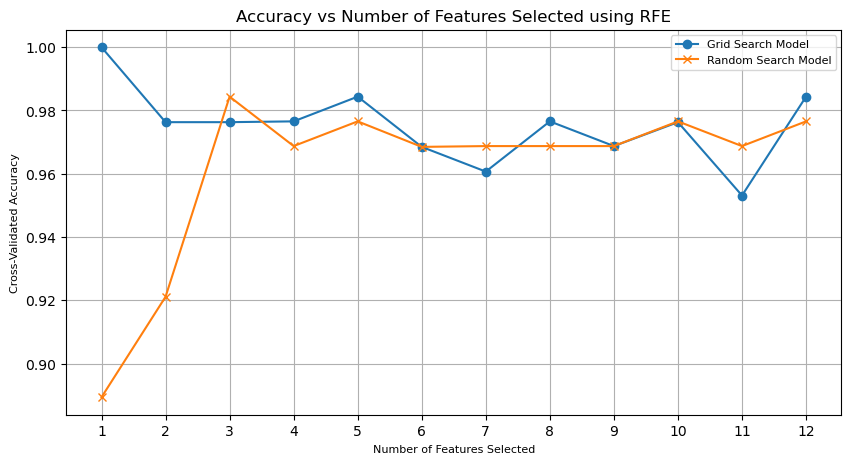


Grid Search Model:
Optimal Number of Features: 1
Selected Features: ['Injection time']
Cross-Validated Accuracy: 1.0000

Random Search Model:
Optimal Number of Features: 3
Selected Features: ['Injection time', 'Switch-over volume', 'Material cushion']
Cross-Validated Accuracy: 0.9844


In [111]:
# Define your Random Forest models using best hyperparameters from previous searches
best_params_grid = grid_search.best_params_  # Best params from Grid Search
best_params_random = random_search.best_params_  # Best params from Random Search

model_grid = RandomForestClassifier(**best_params_grid, random_state=0)
model_random = RandomForestClassifier(**best_params_random, random_state=0)

# Stratified K-Fold cross-validation
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

# Lists to store results
accuracy_grid = []
accuracy_random = []
num_features = []
selected_features_grid_final = None
selected_features_random_final = None

# Perform RFE for each number of features
for n_features in range(1, X.shape[1] + 1):
    # RFE with Grid Search best model
    rfe_grid = RFE(model_grid, n_features_to_select=n_features)
    rfe_grid.fit(X, y)
    grid_features = X.columns[rfe_grid.support_]  # Selected features based on RFE
    score_grid = np.mean(
        [
            model_grid.fit(X.iloc[train_idx, rfe_grid.support_], y.iloc[train_idx])
            .score(X.iloc[test_idx, rfe_grid.support_], y.iloc[test_idx])
            for train_idx, test_idx in cv.split(X, y)
        ]
    )
    accuracy_grid.append(score_grid)

    # Update the final selected features for Grid Search at the optimal point
    if len(accuracy_grid) == 1 or score_grid > max(accuracy_grid[:-1]):
        selected_features_grid_final = grid_features.tolist()

    # RFE with Random Search best model
    rfe_random = RFE(model_random, n_features_to_select=n_features)
    rfe_random.fit(X, y)
    random_features = X.columns[rfe_random.support_]  # Selected features based on RFE
    score_random = np.mean(
        [
            model_random.fit(X.iloc[train_idx, rfe_random.support_], y.iloc[train_idx])
            .score(X.iloc[test_idx, rfe_random.support_], y.iloc[test_idx])
            for train_idx, test_idx in cv.split(X, y)
        ]
    )
    accuracy_random.append(score_random)

    # Update the final selected features for Random Search at the optimal point
    if len(accuracy_random) == 1 or score_random > max(accuracy_random[:-1]):
        selected_features_random_final = random_features.tolist()

    # Track the number of features
    num_features.append(n_features)

# Find the optimal number of features and accuracy for both models
optimal_index_grid = np.argmax(accuracy_grid)
optimal_num_features_grid = num_features[optimal_index_grid]
optimal_accuracy_grid = accuracy_grid[optimal_index_grid]

optimal_index_random = np.argmax(accuracy_random)
optimal_num_features_random = num_features[optimal_index_random]
optimal_accuracy_random = accuracy_random[optimal_index_random]

# Plot the accuracy vs. number of features
plt.figure(figsize=(10, 5))
plt.plot(num_features, accuracy_grid, marker='o', label='Grid Search Model')
plt.plot(num_features, accuracy_random, marker='x', label='Random Search Model')
plt.title("Accuracy vs Number of Features Selected using RFE", fontsize=12)
plt.xlabel("Number of Features Selected", fontsize=8)
plt.ylabel("Cross-Validated Accuracy", fontsize=8)
plt.xticks(num_features)
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

# Display results for Grid Search
print("\nGrid Search Model:")
print(f"Optimal Number of Features: {optimal_num_features_grid}")
print(f"Selected Features: {selected_features_grid_final}")
print(f"Cross-Validated Accuracy: {optimal_accuracy_grid:.4f}")

# Display results for Random Search
print("\nRandom Search Model:")
print(f"Optimal Number of Features: {optimal_num_features_random}")
print(f"Selected Features: {selected_features_random_final}")
print(f"Cross-Validated Accuracy: {optimal_accuracy_random:.4f}")


#### GRID SEARCH

In [113]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

X_selected_grid = X[selected_features_grid_final]

# Define the hyperparameter grid for GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],        # Number of trees in the forest
    'max_depth': [None, 10, 20, 30],       # Maximum depth of each tree
    'min_samples_split': [2, 5, 10],       # Minimum number of samples to split an internal node
    'min_samples_leaf': [1, 2, 4],         # Minimum number of samples required to be a leaf node
    'criterion': ['gini', 'entropy'],     # Criterion for splitting
    'max_features': ['sqrt', 'log2', None], # Number of features to consider at each split
    "bootstrap": [True, False]
}

# Stratified K-Fold cross-validation
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

# Initialize the Random Forest Classifier with the best parameters from GridSearchCV (use your own values here)
rf_model = RandomForestClassifier(random_state=0)

# Initialize GridSearchCV for hyperparameter tuning on the reduced feature set
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=cv,                    # 4-fold cross-validation
    scoring='accuracy',      # Scoring metric
    n_jobs=-1,               # Use all available cores
    verbose=1                # Verbose output for progress
)

# Measure runtime of the grid search process
start_time = time.time()  # Start time

# Perform Grid Search
grid_search.fit(X_selected_grid, y)

end_time = time.time()  # End time
runtime = end_time - start_time  # Total runtime in seconds

# Store the best parameters in a variable for future model rebuilding
best_grid = grid_search.best_params_

# Print the best parameters and the best cross-validation score
print("\nBest Parameters from Grid Search:", grid_search.best_params_)
print("\nBest Cross-Validation Accuracy:", round(grid_search.best_score_, 4))
print(f"Grid Search Runtime: {runtime:.2f} seconds")

Fitting 4 folds for each of 1296 candidates, totalling 5184 fits

Best Parameters from Grid Search: {'bootstrap': True, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}

Best Cross-Validation Accuracy: 1.0
Grid Search Runtime: 97.21 seconds


#### RANDOM SEARCH

In [115]:
# Kernel 1: RandomizedSearchCV for Hyperparameter Tuning
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint
import time

X_selected_rand = X[selected_features_random_final]

# Define the parameter distribution for RandomizedSearchCV
param_dist = {
    'n_estimators': randint(50, 201),        # Number of trees in the forest
    'max_depth': [None, 10, 20, 30],      # Maximum depth of each tree
    'min_samples_split': randint(2, 11),      # Minimum number of samples to split an internal node
    'min_samples_leaf': randint(1, 5),        # Minimum number of samples required to be a leaf node
    'criterion': ['gini', 'entropy'],     # Criterion for splitting
    'max_features': ['sqrt', 'log2', None], # Number of features to consider at each split
    "bootstrap": [True, False]
}

# Stratified K-Fold cross-validation
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

# Initialize RandomForestClassifier
rf = RandomForestClassifier(random_state=0)

# Initialize RandomizedSearchCV with the parameter grid
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=100,            # Number of random parameter combinations to try
    cv=cv,                 # 4-fold cross-validation
    scoring='accuracy',   # Scoring metric
    n_jobs=-1,            # Use all available cores
    random_state=0,       # Ensure reproducibility
    verbose=1             # Verbose output for progress
)

# Measure runtime of the random search process
start_time = time.time()  # Start time

# Perform Randomized Search
random_search.fit(X_selected_rand, y)

end_time = time.time()  # End time
runtime = end_time - start_time  # Total runtime in seconds

# Store the best parameters in a variable for future model rebuilding
best_rand = random_search.best_params_

# Print the best parameters and the best cross-validation score
print("\nBest Parameters from RandomizedSearchCV:", random_search.best_params_)
print("\nBest Cross-Validation Accuracy from RandomizedSearchCV:", round(random_search.best_score_, 4))
print(f"Randomized Search Runtime: {runtime:.2f} seconds")

Fitting 4 folds for each of 100 candidates, totalling 400 fits

Best Parameters from RandomizedSearchCV: {'bootstrap': True, 'criterion': 'entropy', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 153}

Best Cross-Validation Accuracy from RandomizedSearchCV: 0.9844
Randomized Search Runtime: 8.52 seconds


### REBUILD MODELS W REDUCED FEATURES BEST PARAMS

#### GRID SEARCH


Training with the best parameters using selected features...
____________________________________________________________

Iteration: 1
Training data length: 94
Verification data length: 32
Accuracy: 1.0
F1 Score: 1.0
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_1.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_1.png


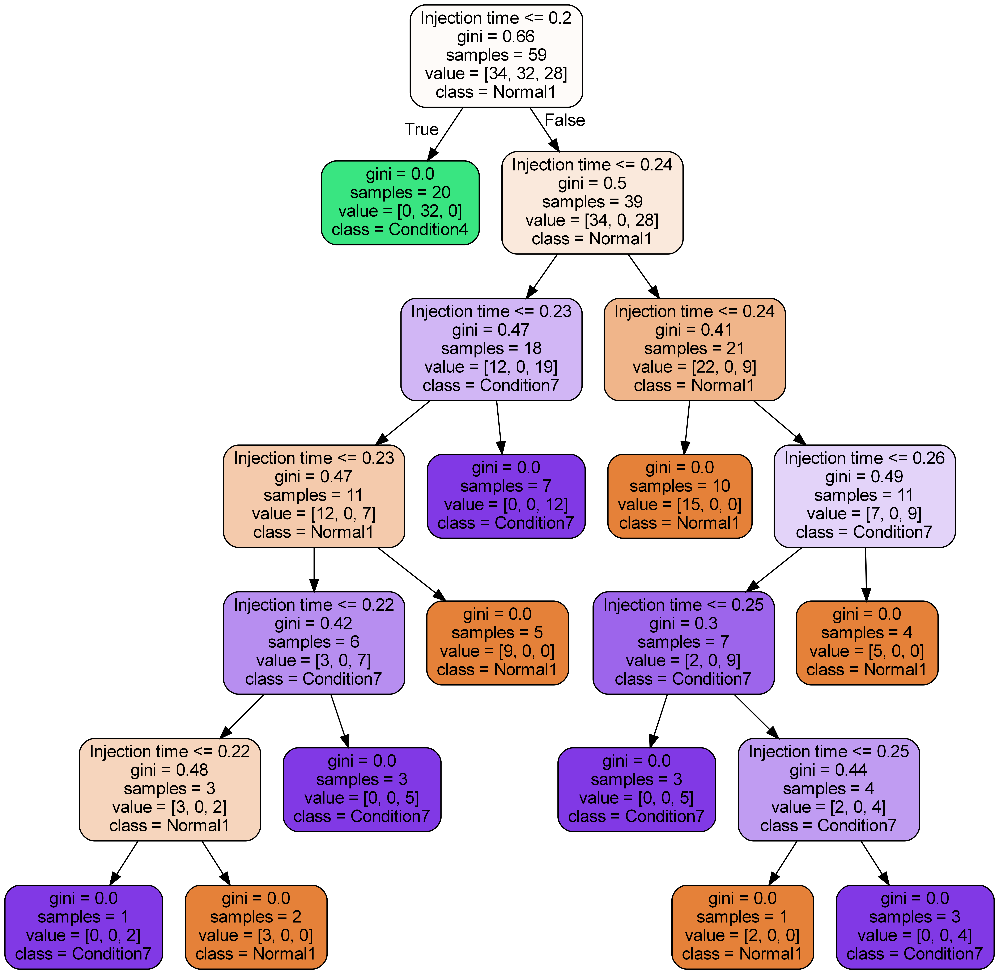

RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        14

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32



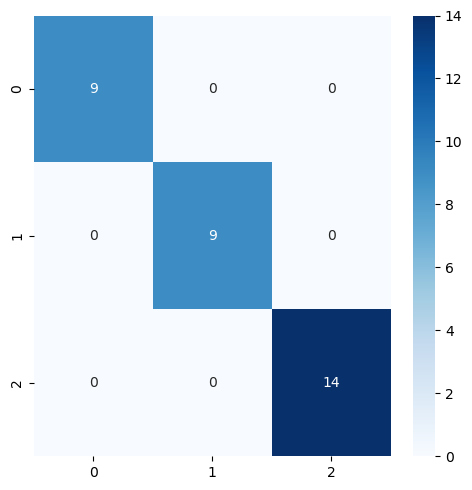

____________________________________________________________

Iteration: 2
Training data length: 94
Verification data length: 32
Accuracy: 1.0
F1 Score: 1.0
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_2.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_2.png


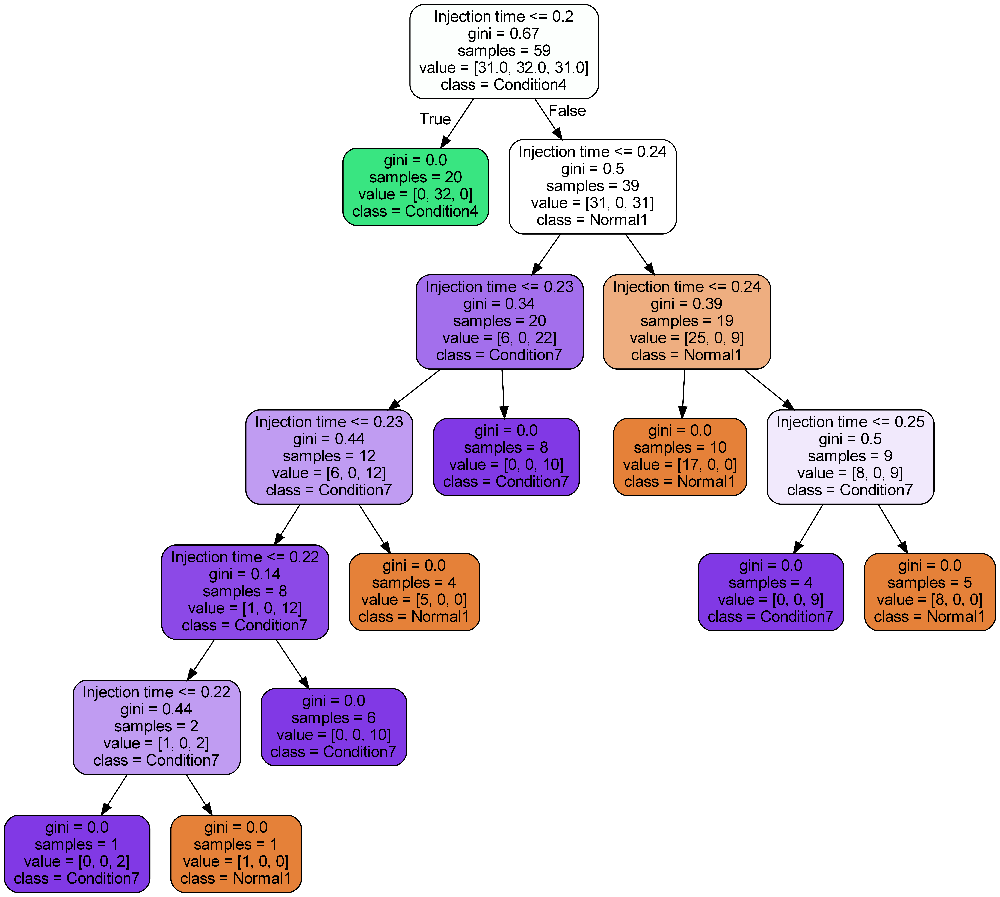

RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        12
  Condition7       1.00      1.00      1.00         8
     Normal1       1.00      1.00      1.00        12

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32



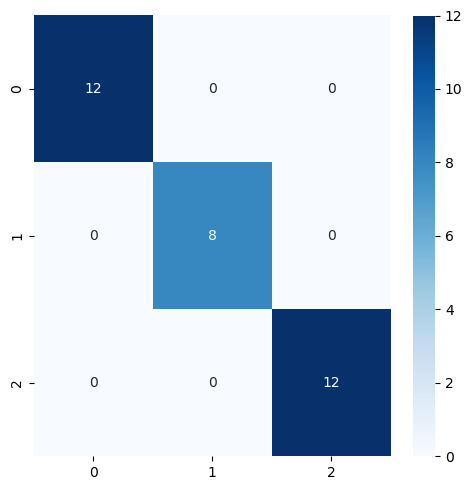

____________________________________________________________

Iteration: 3
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_3.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_3.png


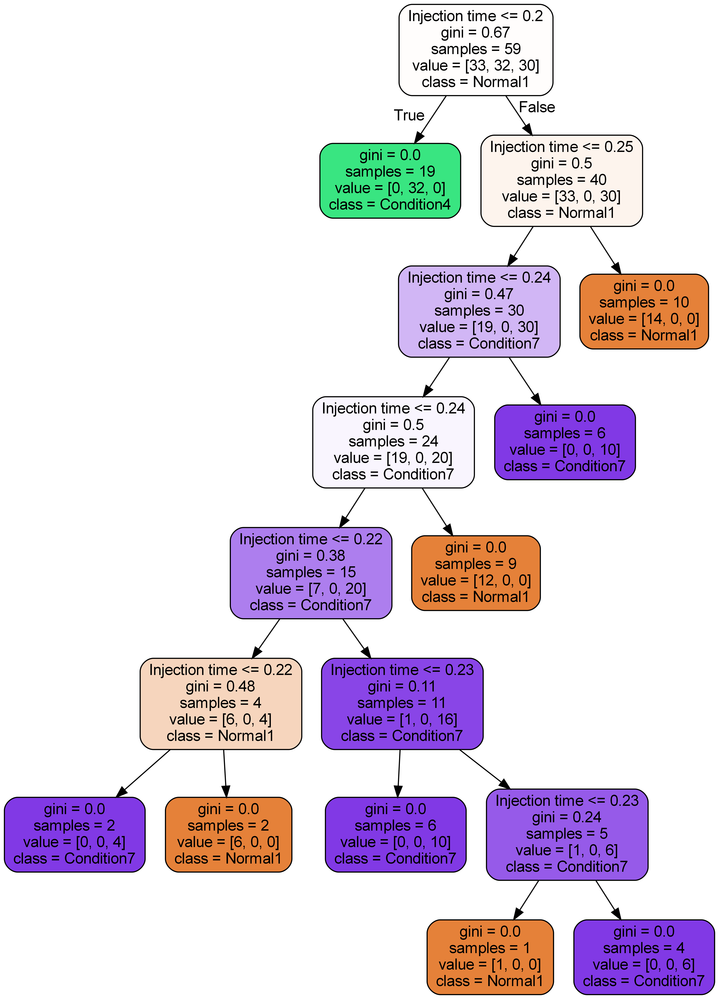

RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        13

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



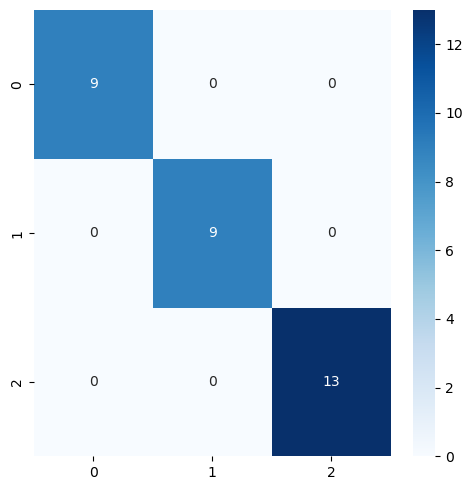

____________________________________________________________

Iteration: 4
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_4.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\tree_4.png


RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        11
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        11

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



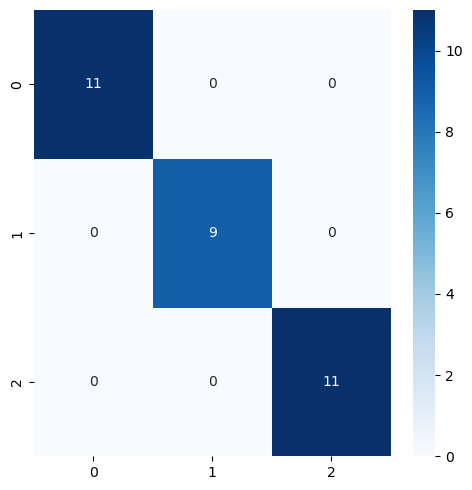

____________________________________________________________

Cross-validation F1 Scores: [1.0, 1.0, 1.0, 1.0]
Mean F1 Score: 1.0

Cross-validation Accuracies: [1.0, 1.0, 1.0, 1.0]
Mean Accuracy: 1.0


In [118]:
from IPython.display import Image, display

# Use the best parameters for final training and evaluation
print("\nTraining with the best parameters using selected features...")

# Define the Random Forest model with the best parameters from Grid Search
redc_rf_grid = RandomForestClassifier(**best_params_grid, random_state=0)

# Filter the dataset to include only the selected features from RFE
X_selected = X[selected_features_grid_final]  # Use `selected_features_grid_final` from RFE

# Perform cross-validation as in the original script
cv = KFold(n_splits=4, shuffle=True, random_state=0)

accuracy_l_grid_redc = []
f1_l_grid_redc = []

i = 1
for tr_i, te_i in cv.split(X_selected, y):  # Use `X_selected` instead of `X`
    X_tr = X_selected.iloc[tr_i]
    X_v = X_selected.iloc[te_i]
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("\nIteration:", i)
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    i += 1

    # Fit Random Forest Classification to the Training set
    redc_rf_grid.fit(X_tr, y_tr)
    y_p = redc_rf_grid.predict(X_v)
    
    # Calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(2))
    accuracy_l_grid_redc.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_grid_redc.append(f1)

    # Extract single tree
    estimator = redc_rf_grid.estimators_[5]  # Extract a specific tree (5th in this case)
    dot_file_path = os.path.join(random_forest_save_path, f'tree_{i-1}.dot')
    png_file_path = os.path.join(random_forest_save_path, f'tree_{i-1}.png')
    
    # Export as dot file
    export_graphviz(
        estimator, 
        out_file=dot_file_path, 
        feature_names=selected_features_grid_final,  # Use selected features as names
        class_names=target_names,
        rounded=True, 
        proportion=False, 
        precision=2, 
        filled=True
    )

    # Convert to PNG using system command (requires Graphviz)
    from subprocess import call
    if os.path.exists(dot_file_path):
        print(f"DOT file created at: {dot_file_path}")

        # Convert to PNG using system command
        call(['dot', '-Tpng', dot_file_path, '-o', png_file_path, '-Gdpi=600'])

        # Check if PNG file was successfully created
        if os.path.exists(png_file_path):
            print(f"PNG file created at: {png_file_path}")
            display(Image(filename=png_file_path))
        else:
            print(f"Error: {png_file_path} was not created. Graphviz might not be running correctly.")
    else:
        print(f"Error: {dot_file_path} was not created. Check export_graphviz parameters and permissions.")

    # Classification report
    print("RF Prediction report", "\n", classification_report(y_v, y_p))
    
    # Plot and save confusion matrix
    fig, ax = plt.subplots(figsize=(5, 5))
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues', ax=ax)
    plt.tight_layout()
    plt.show()

# Mean accuracy & f1 score
mean_accuracy = round(np.mean(accuracy_l_grid_redc), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_grid_redc), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_grid_redc])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_grid_redc])
print("Mean Accuracy:", mean_accuracy)


#### RANDOM SEARCH


Training with the best parameters using selected features...
____________________________________________________________

Iteration: 1
Training data length: 94
Verification data length: 32
Accuracy: 0.97
F1 Score: 0.9701
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\random_tree_1.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\random_tree_1.png


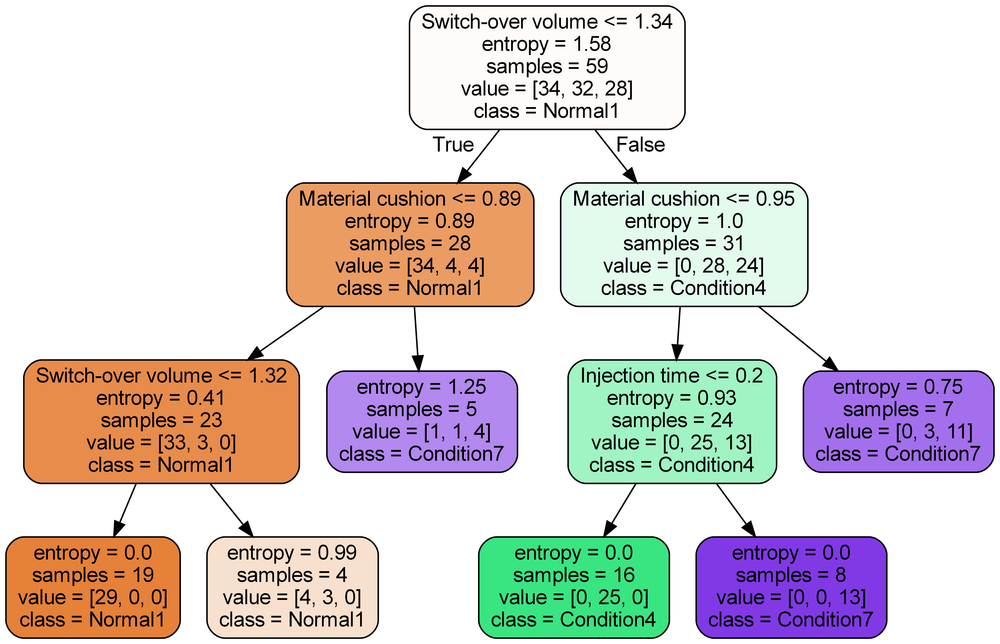

RF Prediction report 
               precision    recall  f1-score   support

  Condition4       0.90      1.00      0.95         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      0.93      0.96        14

    accuracy                           0.97        32
   macro avg       0.97      0.98      0.97        32
weighted avg       0.97      0.97      0.97        32



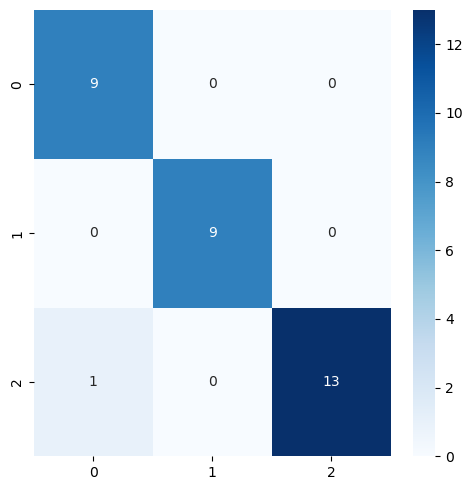

____________________________________________________________

Iteration: 2
Training data length: 94
Verification data length: 32
Accuracy: 0.94
F1 Score: 0.9444
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\random_tree_2.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\random_tree_2.png


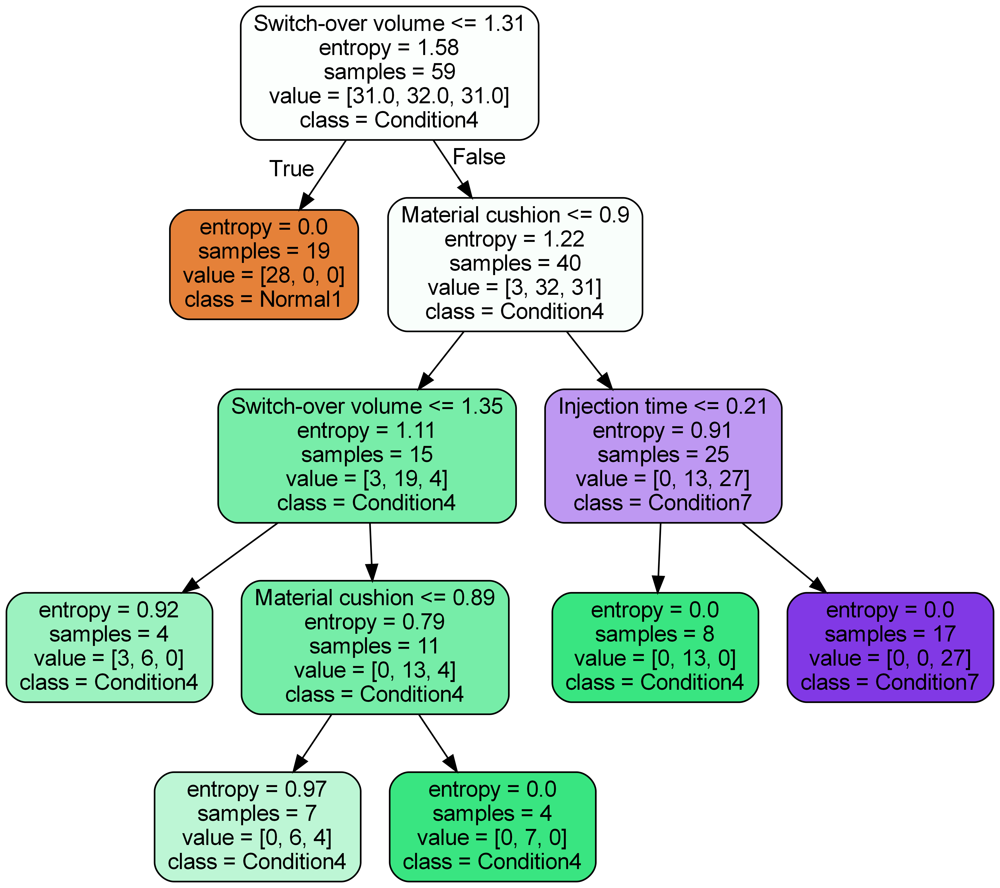

RF Prediction report 
               precision    recall  f1-score   support

  Condition4       0.92      0.92      0.92        12
  Condition7       1.00      1.00      1.00         8
     Normal1       0.92      0.92      0.92        12

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32



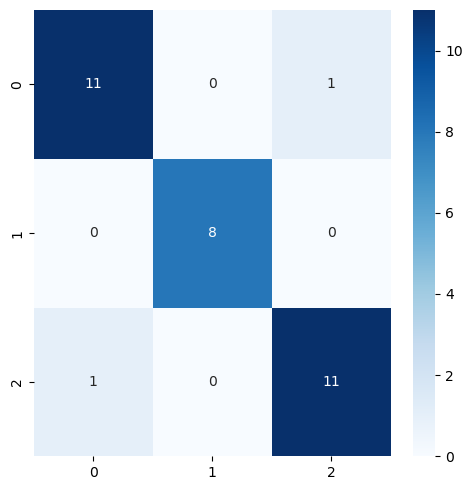

____________________________________________________________

Iteration: 3
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\random_tree_3.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\random_tree_3.png


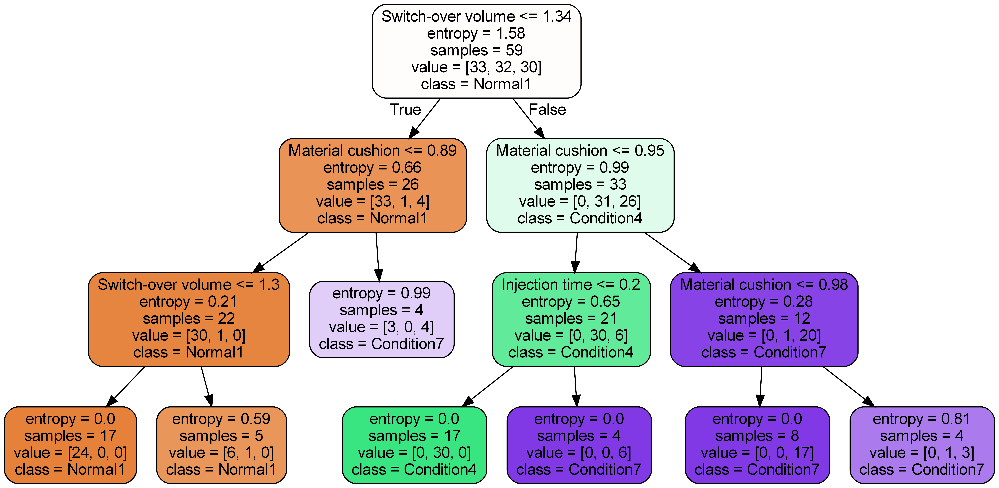

RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00         9
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        13

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



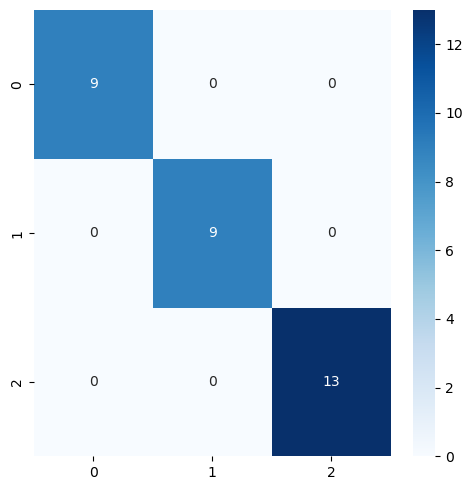

____________________________________________________________

Iteration: 4
Training data length: 95
Verification data length: 31
Accuracy: 1.0
F1 Score: 1.0
DOT file created at: C:\Users\Ivan Chee\Random_Forest_Project1\random_tree_4.dot
PNG file created at: C:\Users\Ivan Chee\Random_Forest_Project1\random_tree_4.png


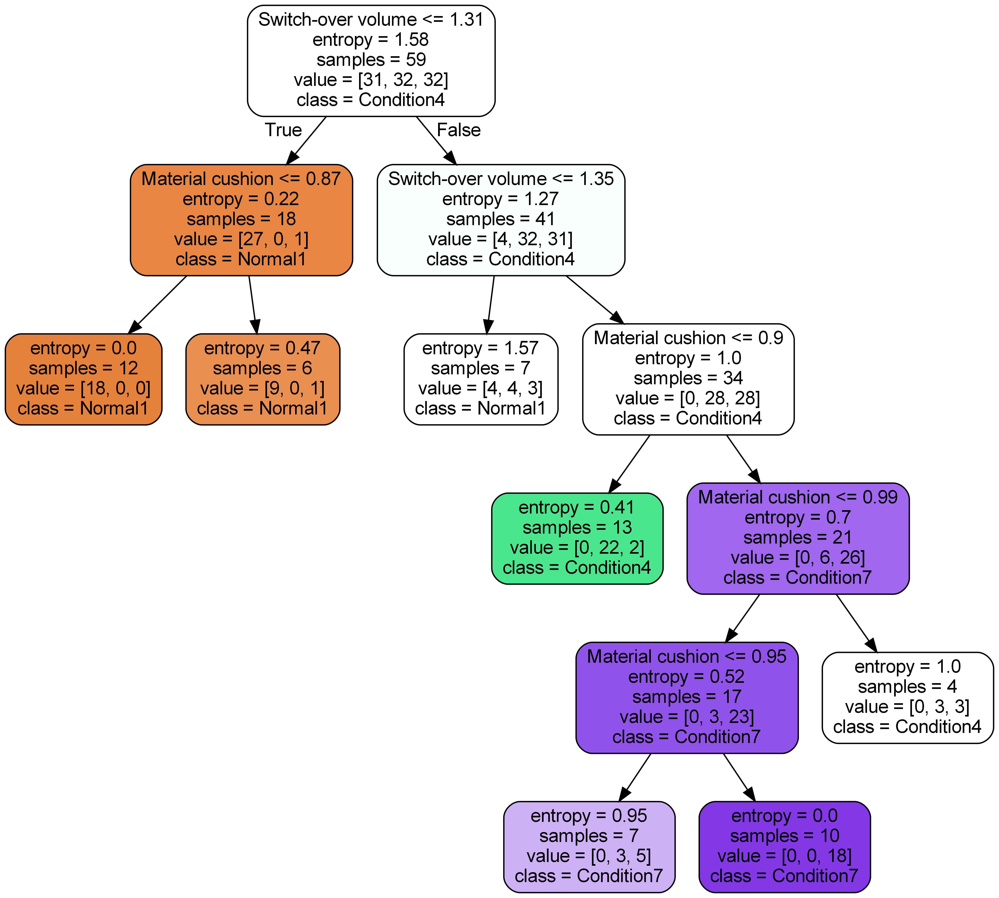

RF Prediction report 
               precision    recall  f1-score   support

  Condition4       1.00      1.00      1.00        11
  Condition7       1.00      1.00      1.00         9
     Normal1       1.00      1.00      1.00        11

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



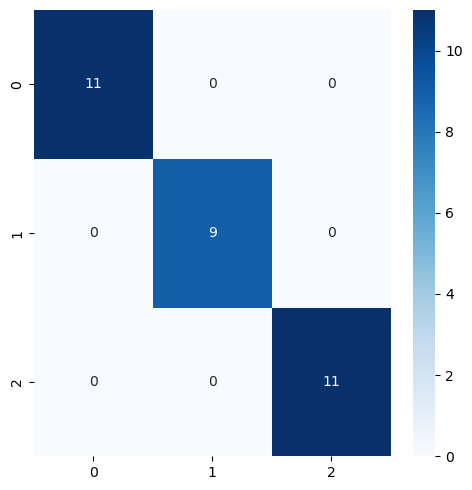

____________________________________________________________

Cross-validation F1 Scores: [0.9701, 0.9444, 1.0, 1.0]
Mean F1 Score: 0.9786

Cross-validation Accuracies: [0.9688, 0.9375, 1.0, 1.0]
Mean Accuracy: 0.9766


In [120]:
from IPython.display import Image, display

# Use the best parameters for final training and evaluation
print("\nTraining with the best parameters using selected features...")

# Define the Random Forest model with the best parameters from Random Search
redc_rf_random = RandomForestClassifier(**best_params_random, random_state=0)

# Filter the dataset to include only the selected features from RFE
X_selected = X[selected_features_random_final]  # Use `selected_features_random_final` from RFE

# Perform cross-validation as in the original script
cv = KFold(n_splits=4, shuffle=True, random_state=0)

accuracy_l_rand_redc = []
f1_l_rand_redc = []

i = 1
for tr_i, te_i in cv.split(X_selected, y):  # Use `X_selected` instead of `X`
    X_tr = X_selected.iloc[tr_i]
    X_v = X_selected.iloc[te_i]
    y_tr = y.iloc[tr_i]
    y_v = y.iloc[te_i]

    print('____________________________________________________________')
    print("\nIteration:", i)
    print("Training data length:", len(y_tr))
    print("Verification data length:", len(y_v))
    i += 1

    # Fit Random Forest Classification to the Training set
    redc_rf_random.fit(X_tr, y_tr)
    y_p = redc_rf_random.predict(X_v)
    
    # Calculate accuracy
    accuracy = np.mean(acs(y_v, y_p))
    print("Accuracy:", accuracy.round(2))
    accuracy_l_rand_redc.append(accuracy)

    # Calculate F1 score
    f1 = f1_score(y_v, y_p, average='macro')  # Use 'macro' to consider all classes equally
    print("F1 Score:", round(f1, 4))
    f1_l_rand_redc.append(f1)

    # Extract single tree
    estimator = redc_rf_random.estimators_[5]  # Extract a specific tree (5th in this case)
    dot_file_path = os.path.join(random_forest_save_path, f'random_tree_{i-1}.dot')
    png_file_path = os.path.join(random_forest_save_path, f'random_tree_{i-1}.png')
    
    # Export as dot file
    export_graphviz(
        estimator, 
        out_file=dot_file_path, 
        feature_names=selected_features_random_final,  # Use selected features as names
        class_names=target_names,
        rounded=True, 
        proportion=False, 
        precision=2, 
        filled=True
    )

    # Convert to PNG using system command (requires Graphviz)
    from subprocess import call
    if os.path.exists(dot_file_path):
        print(f"DOT file created at: {dot_file_path}")

        # Convert to PNG using system command
        call(['dot', '-Tpng', dot_file_path, '-o', png_file_path, '-Gdpi=600'])

        # Check if PNG file was successfully created
        if os.path.exists(png_file_path):
            print(f"PNG file created at: {png_file_path}")
            display(Image(filename=png_file_path))
        else:
            print(f"Error: {png_file_path} was not created. Graphviz might not be running correctly.")
    else:
        print(f"Error: {dot_file_path} was not created. Check export_graphviz parameters and permissions.")

    # Classification report
    print("RF Prediction report", "\n", classification_report(y_v, y_p))
    
    # Plot and save confusion matrix
    fig, ax = plt.subplots(figsize=(5, 5))
    ax = sns.heatmap(confusion_matrix(y_v, y_p), annot=True, fmt='d', cmap='Blues', ax=ax)
    plt.tight_layout()
    plt.show()

# Mean accuracy & f1 score
mean_accuracy = round(np.mean(accuracy_l_rand_redc), 4)  # Calculate and round mean accuracy
mean_f1 = round(np.mean(f1_l_random_redc), 4)  # Calculate and round mean F1 score

# Summary of cross-validation
print('____________________________________________________________')
print("\nCross-validation F1 Scores:", [round(f, 4) for f in f1_l_random_redc])
print("Mean F1 Score:", mean_f1)
print("\nCross-validation Accuracies:", [round(acc, 4) for acc in accuracy_l_random_redc])
print("Mean Accuracy:", mean_accuracy)


### COMPARING RF MODELS

#### ACCURACY SCORE

In [125]:
import matplotlib.pyplot as plt
import numpy as np

# Check if accuracy lists are empty or contain NaN values, and handle them
accuracies = [
    np.mean(accuracy_l) if accuracy_l else 0.0,
    np.mean(accuracy_l_grid) if accuracy_l_grid else 0.0,
    np.mean(accuracy_l_rand) if accuracy_l_rand else 0.0,
    np.mean(accuracy_l_grid_redc) if accuracy_l_grid_redc else 0.0,
    np.mean(accuracy_l_rand_redc) if accuracy_l_rand_redc else 0.0
]

# Ensure accuracies are finite values (replace NaN or Inf with 0)
accuracies = [acc if np.isfinite(acc) else 0.0 for acc in accuracies]

# Define the model names
model_names = ['RF', 'Grid (Initial)', 'Random (Initial)',
               'Reduced Features Grid', 'Reduced Features Random']

# Create the bar plot
plt.figure(figsize=(12, 5))
bars = plt.bar(model_names, accuracies, color=['blue', 'green', 'red', 'navy', 'orange'])

# Add title and labels
plt.title('Comparison of RF Model Accuracies', fontsize=16)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Mean Accuracy', fontsize=12)

# Display accuracy values on top of the bars
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

NameError: name 'accuracy_l_rand_redc' is not defined

#### F1-SCORES

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Check if accuracy lists are empty or contain NaN values, and handle them
f1_score = [
    np.mean(f1_l) if f1_l else 0.0,
    np.mean(f1_l_grid) if f1_l_grid else 0.0,
    np.mean(f1_l_rand) if f1_l_rand else 0.0,
    np.mean(f1_l_grid_redc) if f1_l_grid_redc else 0.0,
    np.mean(f1_l_rand_redc) if f1_l_rand_redc else 0.0
]

# Ensure accuracies are finite values (replace NaN or Inf with 0)
f1_score = [score if np.isfinite(score) else 0.0 for score in f1_score]

# Define the model names
model_names = ['RF', 'Grid (Initial)', 'Random (Initial)',
               'Reduced Features Grid', 'Reduced Features Random']

# Create the bar plot
plt.figure(figsize=(12, 5))
bars = plt.bar(model_names, accuracies, color=['blue', 'green', 'red', 'navy', 'orange'])

# Add title and labels
plt.title('Comparison of RF Model F1-Scores', fontsize=16)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Mean Accuracy', fontsize=12)

# Display accuracy values on top of the bars
for i, v in enumerate(f1_score):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()